Cell 1 — Install packages

In [1]:
!pip install -q pymupdf qdrant-client

import importlib
for pkg in ["pymupdf", "qdrant_client", "sentence_transformers", "openai", "requests"]:
    importlib.import_module(pkg)
print("All packages ready")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.8/25.8 MB 65.4 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 406.5/406.5 kB 17.2 MB/s eta 0:00:00
All packages ready


Cell 2 — Config

In [2]:
# ── Config  (later file: config.yaml + finsight/config.py) ──
import os, copy, re, time
from pathlib import Path

WORK = Path("/kaggle/working")


def find_raw_dir() -> str:
    """Use the saved Kaggle dataset if it exists, otherwise the download folder."""
    hits = sorted(Path("/kaggle/input").rglob("TCS_FY2025_annual_report.pdf"))
    return str(hits[0].parent) if hits else str(WORK / "data/raw/finance")


CONFIG = {
    "data": {
        "raw_dir": find_raw_dir(),                     # saved dataset (or download folder)
        "index_dir": str(WORK / "data/index/phase1"),  # Qdrant + chunks are saved here
    },
    "chunking": {"chunk_size": 512, "chunk_overlap": 64},       # approx tokens
    "embedding": {"model": "BAAI/bge-small-en-v1.5", "batch_size": 64},
    "retrieval": {"top_k": 5},
    "generation": {
        "base_url": "https://api.groq.com/openai/v1",
        "model": None,                 # set in Cell 18
        "temperature": 0.0,
        "max_tokens": 2000,            # reasoning models need room to think AND answer
        "reasoning_effort": "low",     # less thinking = faster answers
    },
}


def deep_update(base: dict, override: dict | None) -> dict:
    """Copy of `base` with values from `override` replaced (works for nested dicts)."""
    out = copy.deepcopy(base)
    for key, value in (override or {}).items():
        if isinstance(value, dict) and isinstance(out.get(key), dict):
            out[key] = deep_update(out[key], value)
        else:
            out[key] = value
    return out

print("Config ready")
print("PDFs will be read from:", CONFIG["data"]["raw_dir"])

Config ready
PDFs will be read from: /kaggle/input/datasets/arpkr678/finsight-reports/finance


Cell 3 — Your document links (6 companies × 6 documents = 36)

In [3]:
# # ── Document links  (later file: data/document_links.csv) ──
# # (company, financial year, doc_type, quarter, url)
# DOCUMENT_LINKS = [
#     # TCS
#     ("TCS", "FY2026", "annual_report", "", "https://www.bseindia.com/xml-data/corpfiling/AttachHis/ad42e748-d73c-4c79-8c52-bcf1b1399bc1.pdf"),
#     ("TCS", "FY2025", "annual_report", "", "https://www.bseindia.com/xml-data/corpfiling/AttachHis/bb9f9e0a-e4ce-4a4e-997e-0b5de8c2bec0.pdf"),
#     ("TCS", "FY2024", "annual_report", "", "https://www.bseindia.com/xml-data/corpfiling/AttachHis/d57e49b6-fd89-4fa8-b591-4f590100db1e.pdf"),
#     ("TCS", "FY2026", "earnings_call", "4", "https://www.bseindia.com/stockinfo/AnnPdfOpen.aspx?Pname=07ae2d32-1050-4e80-96ff-eb2d98378d4e.pdf"),
#     ("TCS", "FY2025", "earnings_call", "4", "https://www.bseindia.com/stockinfo/AnnPdfOpen.aspx?Pname=d3f70d49-123f-40d6-a0a9-b584546c8c63.pdf"),
#     ("TCS", "FY2024", "earnings_call", "4", "https://www.bseindia.com/stockinfo/AnnPdfOpen.aspx?Pname=5c6ff602-30d9-490a-b147-1d824b5b6665.pdf"),
#     # Infosys
#     ("INFY", "FY2026", "annual_report", "", "https://www.bseindia.com/xml-data/corpfiling/AttachHis/19dd605c-2b6b-4084-8dca-9d578a3eb7a0.pdf"),
#     ("INFY", "FY2025", "annual_report", "", "https://www.bseindia.com/xml-data/corpfiling/AttachHis/4527f4d2-dac4-4528-a1dc-5070fd9e140d.pdf"),
#     ("INFY", "FY2024", "annual_report", "", "https://www.bseindia.com/xml-data/corpfiling/AttachHis/25cc7fbc-154b-4463-928d-c95f2d8c5c9c.pdf"),
#     ("INFY", "FY2026", "earnings_call", "4", "https://www.bseindia.com/stockinfo/AnnPdfOpen.aspx?Pname=2ab7badf-388c-4dab-bfcc-3e128677734c.pdf"),
#     ("INFY", "FY2025", "earnings_call", "4", "https://www.bseindia.com/stockinfo/AnnPdfOpen.aspx?Pname=8c8bbc00-087d-4d75-9171-d37a3f83a170.pdf"),
#     ("INFY", "FY2024", "earnings_call", "4", "https://www.bseindia.com/stockinfo/AnnPdfOpen.aspx?Pname=77f16d60-73b2-4877-80fb-c641f2529a70.pdf"),
#     # HDFC Bank
#     ("HDFCBANK", "FY2026", "annual_report", "", "https://www.bseindia.com/xml-data/corpfiling/AttachHis/7d621500-082a-4342-b98d-ba677d3890c5.pdf"),
#     ("HDFCBANK", "FY2025", "annual_report", "", "https://www.bseindia.com/xml-data/corpfiling/AttachHis/411e22d2-0720-4cec-b659-9ccd639f0f1a.pdf"),
#     ("HDFCBANK", "FY2024", "annual_report", "", "https://www.hdfc.bank.in/content/dam/hdfcbankpws/in/en/pdf/annual-reports/2023-24/integrated-annual-report-2023-24.pdf"),
#     ("HDFCBANK", "FY2026", "earnings_call", "4", "https://www.bseindia.com/stockinfo/AnnPdfOpen.aspx?Pname=a77abbbb-954a-4221-8240-67bf0da6ba1c.pdf"),
#     ("HDFCBANK", "FY2025", "earnings_call", "4", "https://www.bseindia.com/stockinfo/AnnPdfOpen.aspx?Pname=ff4ae1b4-cf07-4f6d-b097-3bd8139fb570.pdf"),
#     ("HDFCBANK", "FY2024", "earnings_call", "4", "https://www.bseindia.com/stockinfo/AnnPdfOpen.aspx?Pname=880ee466-e764-4e05-9ef3-3d9bb8e485f4.pdf"),
#     # ICICI Bank
#     ("ICICIBANK", "FY2026", "annual_report", "", "https://www.bseindia.com/xml-data/corpfiling/AttachHis/01c30537-c969-4503-bbae-a07d51eb09a5.pdf"),
#     ("ICICIBANK", "FY2025", "annual_report", "", "https://www.bseindia.com/xml-data/corpfiling/AttachHis/d80c4401-bed9-4aa4-b532-00255b963376.pdf"),
#     ("ICICIBANK", "FY2024", "annual_report", "", "https://www.bseindia.com/xml-data/corpfiling/AttachHis/9d5f21fd-9b1e-42e5-a48b-84d2623f293c.pdf"),
#     ("ICICIBANK", "FY2026", "earnings_call", "4", "https://www.bseindia.com/stockinfo/AnnPdfOpen.aspx?Pname=50d0e36c-8e96-4fde-9d2e-d33a9443ec34.pdf"),
#     ("ICICIBANK", "FY2025", "earnings_call", "4", "https://www.bseindia.com/stockinfo/AnnPdfOpen.aspx?Pname=1a691340-05c5-4029-a15f-cdd78f457400.pdf"),
#     ("ICICIBANK", "FY2024", "earnings_call", "4", "https://www.icicibank.com/content/dam/icicibank/india/managed-assets/docs/about-us/2024/2024_04_q4-2024_opening-transcript-of-analyst-call.pdf"),
#     # Hindustan Unilever
#     ("HINDUNILVR", "FY2026", "annual_report", "", "https://www.bseindia.com/xml-data/corpfiling/AttachHis/881493e4-75af-4a7f-8c64-9d0886e63f1d.pdf"),
#     ("HINDUNILVR", "FY2025", "annual_report", "", "https://www.bseindia.com/xml-data/corpfiling/AttachHis/770bf03e-526d-45d8-8364-13f7fc523289.pdf"),
#     ("HINDUNILVR", "FY2024", "annual_report", "", "https://www.bseindia.com/xml-data/corpfiling/AttachHis/02d8d87d-90ce-4191-8b3f-4167267aee8a.pdf"),
#     ("HINDUNILVR", "FY2026", "earnings_call", "4", "https://www.bseindia.com/stockinfo/AnnPdfOpen.aspx?Pname=55988411-440d-4801-8c08-90a5908c4a04.pdf"),
#     ("HINDUNILVR", "FY2025", "earnings_call", "4", "https://www.bseindia.com/stockinfo/AnnPdfOpen.aspx?Pname=57aad284-8283-4c21-8035-99627387a92d.pdf"),
#     ("HINDUNILVR", "FY2024", "earnings_call", "4", "https://www.hul.co.in/files/1167108a-d524-4489-af5e-5114ff741569/hul-earnings-apr24-2024-v2-website-upload.pdf"),
#     # Wipro
#     ("WIPRO", "FY2026", "annual_report", "", "https://www.bseindia.com/xml-data/corpfiling/AttachHis/d4ffaa08-a47a-487b-b136-eb4f26c1bace.pdf"),
#     ("WIPRO", "FY2025", "annual_report", "", "https://www.bseindia.com/xml-data/corpfiling/AttachHis/bad4d97f-e94b-486a-b1ab-c50cd7ae0c75.pdf"),
#     ("WIPRO", "FY2024", "annual_report", "", "https://www.bseindia.com/xml-data/corpfiling/AttachHis/53cec073-5278-4dcd-9066-2fd101023af5.pdf"),
#     ("WIPRO", "FY2026", "earnings_call", "4", "https://www.bseindia.com/stockinfo/AnnPdfOpen.aspx?Pname=78fab9a0-4864-4470-be49-3544e57f1c49.pdf"),
#     ("WIPRO", "FY2025", "earnings_call", "4", "https://www.bseindia.com/stockinfo/AnnPdfOpen.aspx?Pname=3aa50722-240f-4b06-8be1-d37a0026f8c5.pdf"),
#     ("WIPRO", "FY2024", "earnings_call", "4", "https://www.bseindia.com/stockinfo/AnnPdfOpen.aspx?Pname=64445460-0bf5-44b1-adb3-59d8b8416860.pdf"),
# ]
# print(f"{len(DOCUMENT_LINKS)} documents listed")

Cell 4 — Downloader

In [4]:
# # ── Downloader  (later file: scripts/download_documents.py) ──
# import re, time
# import requests

# HEADERS = {
#     "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 "
#                   "(KHTML, like Gecko) Chrome/124.0 Safari/537.36",
#     "Accept": "application/pdf,*/*",
# }


# def make_filename(company: str, year: str, doc_type: str, quarter: str) -> str:
#     if not re.fullmatch(r"FY\d{4}", year):
#         raise ValueError(f"year must look like FY2025, got '{year}'")
#     if doc_type == "earnings_call":
#         if quarter not in {"1", "2", "3", "4"}:
#             raise ValueError("earnings_call needs quarter 1-4")
#         return f"{company}_{year}Q{quarter}_earnings_call.pdf"
#     if doc_type == "annual_report":
#         return f"{company}_{year}_annual_report.pdf"
#     raise ValueError(f"unknown doc_type '{doc_type}'")


# def download_file(url: str, dest: Path, retries: int = 3) -> str:
#     headers = dict(HEADERS)
#     if "bseindia.com" in url:
#         headers["Referer"] = "https://www.bseindia.com/"
#     last_error = ""
#     for attempt in range(retries):
#         try:
#             with requests.get(url, headers=headers, timeout=180, stream=True) as r:
#                 r.raise_for_status()
#                 tmp = dest.with_suffix(".part")
#                 with open(tmp, "wb") as f:
#                     for block in r.iter_content(1 << 16):
#                         f.write(block)
#             with open(tmp, "rb") as f:
#                 if f.read(5) != b"%PDF-":      # the site sent an HTML page instead of a PDF
#                     tmp.unlink()
#                     return "NOT A PDF (site blocked the download: get this one manually)"
#             tmp.rename(dest)
#             return "ok"
#         except Exception as exc:
#             last_error = f"{type(exc).__name__}: {exc}"[:150]
#             time.sleep(3 * (attempt + 1))
#     return f"FAILED: {last_error}"


# def download_all(links, out_dir) -> list:
#     out = Path(out_dir)
#     out.mkdir(parents=True, exist_ok=True)
#     problems = []
#     for i, (company, year, doc_type, quarter, url) in enumerate(links, start=1):
#         name = make_filename(company, year, doc_type, quarter)
#         dest = out / name
#         if dest.exists() and dest.stat().st_size > 10_000:
#             print(f"[{i}/{len(links)}] {name}: already downloaded")
#             continue
#         status = download_file(url, dest)
#         size = f"({dest.stat().st_size / 1e6:.1f} MB)" if dest.exists() else ""
#         print(f"[{i}/{len(links)}] {name}: {status} {size}")
#         if status != "ok":
#             problems.append((name, status))
#         time.sleep(1)    # be polite to the servers
#     print(f"\nProblems: {len(problems)}")
#     for name, status in problems:
#         print(f"  - {name}: {status}")
#     return problems

Cell 5 — Download everything (safe to re-run; it skips files you already have)

In [5]:
# problems = download_all(DOCUMENT_LINKS, CONFIG["data"]["raw_dir"])

In [6]:
# # ── Copy manually downloaded files (blocked sites) into the raw folder ──
# !find /kaggle/input -name "HINDUNILVR_FY2024Q4_earnings_call.pdf" -exec cp {} /kaggle/working/data/raw/finance/ \;
# !ls /kaggle/working/data/raw/finance | wc -l

Cell 6 — Data structures

In [7]:
# ── Data structures  (later file: finsight/schema.py) ──
from dataclasses import asdict, dataclass, field


@dataclass
class Element:
    """A piece of a parsed document. In Phase 1 this is one page of text."""
    page: int
    text: str
    kind: str = "text"      # later phases add "heading" and "table"


@dataclass
class Chunk:
    chunk_id: str
    doc_id: str
    text: str
    page_start: int
    page_end: int
    metadata: dict = field(default_factory=dict)

    def to_dict(self) -> dict:
        return asdict(self)

    @classmethod
    def from_dict(cls, d: dict) -> "Chunk":
        return cls(**d)

    def source_label(self) -> str:
        """e.g. 'TCS FY2024 Annual Report, p. 45'"""
        title = self.metadata.get("title", self.doc_id)
        if self.page_start == self.page_end:
            return f"{title}, p. {self.page_start}"
        return f"{title}, pp. {self.page_start}-{self.page_end}"


@dataclass
class RetrievedChunk:
    chunk: Chunk
    score: float

    def ref(self) -> dict:
        return {"chunk_id": self.chunk.chunk_id, "doc_id": self.chunk.doc_id,
                "page_start": self.chunk.page_start, "page_end": self.chunk.page_end,
                "label": self.chunk.source_label(), "score": round(self.score, 4)}

print("Data structures ready")

Data structures ready


Cell 7 — Parser and metadata

In [8]:
# ── Parser + metadata  (later files: finsight/ingestion/parser.py, metadata.py) ──
import pymupdf

SUPPORTED_SUFFIXES = {".pdf", ".txt", ".md"}
FILENAME_RE = re.compile(
    r"^(?P<company>[A-Za-z0-9&-]+)_(?P<year>FY\d{4})(?:Q(?P<quarter>[1-4]))?_(?P<doc_type>annual_report|earnings_call)$"
)


def clean_text(text: str) -> str:
    text = re.sub(r"-\n(?=[a-z])", "", text)     # join words split by a hyphen at line end
    text = re.sub(r"[ \t]+", " ", text)           # collapse repeated spaces
    text = re.sub(r"\n{3,}", "\n\n", text)        # collapse many blank lines
    return text.strip()


def parse_document(path) -> list[Element]:
    path = Path(path)
    suffix = path.suffix.lower()
    if suffix == ".pdf":
        elements = []
        with pymupdf.open(path) as doc:
            for page_no, page in enumerate(doc, start=1):
                text = clean_text(page.get_text("text"))
                if text:
                    elements.append(Element(page=page_no, text=text))
        return elements
    if suffix in {".txt", ".md"}:
        text = clean_text(path.read_text(encoding="utf-8", errors="ignore"))
        return [Element(page=1, text=text)] if text else []
    raise ValueError(f"Unsupported file type: {path.name}")


def extract_metadata(path) -> dict:
    """TCS_FY2024Q4_earnings_call.pdf -> company, year, quarter, doc_type, title"""
    path = Path(path)
    match = FILENAME_RE.match(path.stem)
    if not match:
        return {"doc_id": path.stem, "title": path.stem, "doc_type": "unknown", "matched_pattern": False}
    meta = {k: v for k, v in match.groupdict().items() if v}
    quarter = f" Q{meta['quarter']}" if meta.get("quarter") else ""
    doc_type = meta["doc_type"].replace("_", " ").title()
    meta.update(doc_id=path.stem, title=f"{meta['company']} {meta['year']}{quarter} {doc_type}",
                matched_pattern=True)
    return meta

print("Parser ready")

Parser ready


Cell 8 — Data quality check

In [9]:
# ── Data quality check  (later file: scripts/check_documents.py) ──
def check_documents(folder) -> list:
    files = sorted(Path(folder).rglob("*.pdf"))
    print(f"{'file':<42}{'pages':>7}{'MB':>7}{'chars/page':>12}  status")
    total_pages, flagged = 0, []
    for path in files:
        status = []
        if not extract_metadata(path)["matched_pattern"]:
            status.append("BAD NAME")
        try:
            with pymupdf.open(path) as doc:
                pages = len(doc)
                sample = [doc[i] for i in range(0, pages, max(1, pages // 20))]   # ~20 pages spread out
                chars = sum(len(p.get_text("text").strip()) for p in sample) / max(1, len(sample))
        except Exception as exc:
            print(f"{path.name:<42}  CANNOT OPEN: {exc}")
            flagged.append(path.name)
            continue
        if chars < 200:
            status.append("SCANNED? little text")
        if pages < 3:
            status.append("very short: wrong file?")
        total_pages += pages
        if status:
            flagged.append(path.name)
        print(f"{path.name:<42}{pages:>7}{path.stat().st_size / 1e6:>7.1f}{chars:>12.0f}  {', '.join(status) or 'OK'}")
    print(f"\n{len(files)} files, {total_pages} pages, {len(flagged)} flagged")
    return flagged

flagged = check_documents(CONFIG["data"]["raw_dir"])

file                                        pages     MB  chars/page  status
HDFCBANK_FY2024Q4_earnings_call.pdf            21    0.8        3048  OK
HDFCBANK_FY2024_annual_report.pdf             585   15.7        2598  OK
HDFCBANK_FY2025Q4_earnings_call.pdf            18    0.4        2952  OK
HDFCBANK_FY2025_annual_report.pdf             609    8.5        3160  OK
HDFCBANK_FY2026Q4_earnings_call.pdf            16    0.4        3179  OK
HDFCBANK_FY2026_annual_report.pdf             678   12.7        2744  OK
HINDUNILVR_FY2024Q4_earnings_call.pdf          53    0.4        1701  OK
HINDUNILVR_FY2024_annual_report.pdf           229   21.6        6336  OK
HINDUNILVR_FY2025Q4_earnings_call.pdf          41   20.2        2333  OK
HINDUNILVR_FY2025_annual_report.pdf           236   28.9        6220  OK
HINDUNILVR_FY2026Q4_earnings_call.pdf          36    0.5        2060  OK
HINDUNILVR_FY2026_annual_report.pdf           246   21.6        5420  OK
ICICIBANK_FY2024Q4_earnings_call.pdf           

Cell 9 — Chunker

In [10]:
# ── Chunker  (later file: finsight/ingestion/chunker.py) ──
WORDS_PER_TOKEN = 1 / 1.3     # rough rule: 1 English word ~ 1.3 tokens


def approx_tokens(text: str) -> int:
    return max(1, round(len(text.split()) * 1.3))


def chunk_fixed(elements: list[Element], doc_id: str, metadata: dict,
                chunk_size: int = 512, chunk_overlap: int = 64) -> list[Chunk]:
    """Fixed-size word windows with overlap. Remembers the page of every word."""
    words = [(word, el.page) for el in elements for word in el.text.split()]
    size = max(1, int(chunk_size * WORDS_PER_TOKEN))
    stride = max(1, size - int(chunk_overlap * WORDS_PER_TOKEN))
    chunks = []
    for start in range(0, len(words), stride):
        window = words[start:start + size]
        if not window:
            break
        chunks.append(Chunk(
            chunk_id=f"{doc_id}::{len(chunks):04d}",
            doc_id=doc_id,
            text=" ".join(w for w, _ in window),
            page_start=window[0][1],
            page_end=window[-1][1],
            metadata=metadata,
        ))
        if start + size >= len(words):
            break
    return chunks

print("Chunker ready")

Chunker ready


Cell 10 — Embedder

In [11]:
# ── Embedder  (later file: finsight/indexing/embedder.py) ──
import hashlib
from functools import lru_cache
import numpy as np


class HashEmbedder:
    """Fake embedder for quick tests only (no download). Never report results from it."""
    dim = 384

    def _vector(self, text: str) -> np.ndarray:
        vec = np.zeros(self.dim, dtype=np.float32)
        for tok in re.findall(r"\w+", text.lower()):
            vec[int(hashlib.md5(tok.encode()).hexdigest(), 16) % self.dim] += 1.0
        norm = np.linalg.norm(vec)
        return vec / norm if norm else vec

    def embed_documents(self, texts):
        return np.vstack([self._vector(t) for t in texts]) if texts else np.zeros((0, self.dim), np.float32)

    def embed_query(self, text):
        return self._vector(text)


class SentenceTransformerEmbedder:
    def __init__(self, model_name: str, batch_size: int = 32):
        from sentence_transformers import SentenceTransformer
        self.model = SentenceTransformer(model_name)          # uses the GPU automatically
        self.batch_size = batch_size
        get_dim = getattr(self.model, "get_embedding_dimension", None) or self.model.get_sentence_embedding_dimension
        self.dim = get_dim()
        # bge models work better when the QUERY (not the documents) gets this instruction
        self.query_prefix = ("Represent this sentence for searching relevant passages: "
                             if "bge" in model_name.lower() else "")

    def embed_documents(self, texts):
        return self.model.encode(texts, batch_size=self.batch_size, normalize_embeddings=True,
                                 convert_to_numpy=True, show_progress_bar=False).astype(np.float32)

    def embed_query(self, text):
        return self.model.encode([self.query_prefix + text], normalize_embeddings=True,
                                 convert_to_numpy=True)[0].astype(np.float32)


@lru_cache(maxsize=2)
def get_embedder(model_name: str, batch_size: int = 32):
    return HashEmbedder() if model_name == "hash" else SentenceTransformerEmbedder(model_name, batch_size)

print("Embedder ready")

Embedder ready


Cell 11 — Vector index

In [12]:
# ── Vector index  (later file: finsight/indexing/index.py) ──
import json, uuid
from qdrant_client import QdrantClient, models

COLLECTION = "chunks"
_OPEN_INDEXES = {}     # Qdrant local mode allows only ONE connection per folder, so we reuse it


class VectorIndex:
    def __init__(self, index_dir):
        self.dir = Path(index_dir)
        self.dir.mkdir(parents=True, exist_ok=True)
        self.client = QdrantClient(path=str(self.dir / "qdrant"))
        self.chunks: dict[str, Chunk] = {}
        chunk_file = self.dir / "chunks.jsonl"
        if chunk_file.exists():
            with open(chunk_file, encoding="utf-8") as f:
                for line in f:
                    c = Chunk.from_dict(json.loads(line))
                    self.chunks[c.chunk_id] = c

    def reset(self, dim: int) -> None:
        """Delete everything and create an empty collection (Phase 1 rebuilds from scratch)."""
        if self.client.collection_exists(COLLECTION):
            self.client.delete_collection(COLLECTION)
        self.client.create_collection(COLLECTION, vectors_config=models.VectorParams(
            size=dim, distance=models.Distance.COSINE))
        self.chunks = {}

    def add(self, chunks: list[Chunk], vectors: np.ndarray) -> None:
        points = [models.PointStruct(id=str(uuid.uuid5(uuid.NAMESPACE_URL, c.chunk_id)),
                                     vector=v.tolist(), payload={"chunk_id": c.chunk_id, **c.metadata})
                  for c, v in zip(chunks, vectors)]
        for i in range(0, len(points), 256):
            self.client.upsert(COLLECTION, points=points[i:i + 256])
        for c in chunks:
            self.chunks[c.chunk_id] = c

    def search(self, query_vector: np.ndarray, k: int) -> list[tuple[Chunk, float]]:
        if not self.client.collection_exists(COLLECTION):
            return []
        result = self.client.query_points(COLLECTION, query=query_vector.tolist(), limit=k)
        return [(self.chunks[p.payload["chunk_id"]], float(p.score)) for p in result.points]

    def save(self) -> None:
        with open(self.dir / "chunks.jsonl", "w", encoding="utf-8") as f:
            for c in self.chunks.values():
                f.write(json.dumps(c.to_dict(), ensure_ascii=False) + "\n")


def get_index(index_dir) -> VectorIndex:
    key = str(Path(index_dir).resolve())
    if key not in _OPEN_INDEXES:
        _OPEN_INDEXES[key] = VectorIndex(index_dir)
    return _OPEN_INDEXES[key]

print("Index ready")

Index ready


Cell 12 — Ingestion

In [13]:
# ── Ingestion  (later file: finsight/indexing/ingest.py) ──
def ingest(cfg: dict) -> dict:
    raw_dir = Path(cfg["data"]["raw_dir"])
    files = sorted(p for p in raw_dir.rglob("*") if p.suffix.lower() in SUPPORTED_SUFFIXES)
    if not files:
        raise FileNotFoundError(f"No documents found in {raw_dir}")
    embedder = get_embedder(cfg["embedding"]["model"], cfg["embedding"]["batch_size"])
    index = get_index(cfg["data"]["index_dir"])
    index.reset(embedder.dim)
    stats = {"documents": 0, "pages": 0, "chunks": 0, "failed": [], "unmatched_filenames": []}
    start = time.time()
    for path in files:
        try:
            elements = parse_document(path)
        except Exception as exc:          # one broken PDF should not stop everything
            print(f"FAILED {path.name}: {exc}")
            stats["failed"].append(path.name)
            continue
        meta = extract_metadata(path)
        if not meta["matched_pattern"]:
            stats["unmatched_filenames"].append(path.name)
        chunks = chunk_fixed(elements, meta["doc_id"], meta,
                             cfg["chunking"]["chunk_size"], cfg["chunking"]["chunk_overlap"])
        if chunks:
            index.add(chunks, embedder.embed_documents([c.text for c in chunks]))
        print(f"{path.name:<42} {len(elements):>4} pages -> {len(chunks):>4} chunks")
        stats["documents"] += 1
        stats["pages"] += len(elements)
        stats["chunks"] += len(chunks)
    index.save()
    stats["minutes"] = round((time.time() - start) / 60, 1)
    return stats

Cell 13 — LLM and prompts

In [14]:
# ── LLM + prompts  (later files: finsight/generation/llm.py, prompts.py) ──
from openai import OpenAI, APIConnectionError, BadRequestError, RateLimitError


@dataclass
class LLMResponse:
    text: str
    input_tokens: int = 0
    output_tokens: int = 0
    finish_reason: str = ""


class OpenAICompatibleLLM:
    """Works with Groq, OpenAI, Ollama, or any OpenAI-compatible API."""

    def __init__(self, base_url, model, api_key=None, temperature=0.0, max_tokens=2000,
                 reasoning_effort=None, max_retries=4):
        if not model:
            raise ValueError("No LLM model set. Set LLM_MODEL in the secrets cell.")
        self.client = OpenAI(base_url=base_url, api_key=api_key or "not-needed", timeout=120,
                             max_retries=0)   # our own retry loop handles it and prints a message
        self.model, self.temperature, self.max_tokens = model, temperature, max_tokens
        self.reasoning_effort, self.max_retries = reasoning_effort, max_retries

    def chat(self, messages: list[dict]) -> LLMResponse:
        kwargs = dict(model=self.model, messages=messages,
                      temperature=self.temperature, max_tokens=self.max_tokens)
        if self.reasoning_effort:   # reasoning models (e.g. gpt-oss) think less -> faster, fewer tokens
            kwargs["extra_body"] = {"reasoning_effort": self.reasoning_effort}
        for attempt in range(self.max_retries + 1):
            try:
                resp = self.client.chat.completions.create(**kwargs)
                break
            except BadRequestError:
                if "extra_body" not in kwargs:
                    raise
                kwargs.pop("extra_body")          # this model does not support reasoning_effort
                self.reasoning_effort = None
            except (RateLimitError, APIConnectionError):
                if attempt == self.max_retries:
                    raise
                wait = 2 ** attempt * 5          # free tiers rate-limit: wait 5s, 10s, 20s, 40s
                print(f"Rate limited, retrying in {wait}s ...")
                time.sleep(wait)
        choice, usage = resp.choices[0], resp.usage
        return LLMResponse(choice.message.content or "",
                           getattr(usage, "prompt_tokens", 0) or 0,
                           getattr(usage, "completion_tokens", 0) or 0,
                           choice.finish_reason or "")


def llm_from_config(gcfg: dict) -> OpenAICompatibleLLM:
    return OpenAICompatibleLLM(
        base_url=os.getenv("LLM_BASE_URL") or gcfg["base_url"],
        model=os.getenv("LLM_MODEL") or gcfg.get("model"),
        api_key=os.getenv("LLM_API_KEY"),
        temperature=gcfg.get("temperature", 0.0),
        max_tokens=gcfg.get("max_tokens", 2000),
        reasoning_effort=gcfg.get("reasoning_effort"),
    )


ANSWER_SYSTEM = """You are a careful financial analyst answering questions about company annual reports and earnings call transcripts.
Answer using ONLY the numbered sources provided.

Rules:
1. End every sentence that states a fact with its citation in square brackets, like [1] or [2][3].
2. Always name the company and the period in your answer (e.g. "HDFC Bank's gross NPA ratio as of March 31, 2025 was ...").
3. Only use a source if it is about the company and period asked. If no source matches, reply with exactly one line:
   NOT_FOUND: <short reason>
4. Never use outside knowledge and never guess numbers.
5. Copy numbers exactly, with units (₹ crore, %, etc.).
Keep the answer short (at most 6 sentences)."""


def format_sources(chunks: list[RetrievedChunk]) -> str:
    return "\n\n".join(f"[{i}] {c.chunk.source_label()}\n{c.chunk.text}" for i, c in enumerate(chunks, start=1))


def build_messages(question: str, chunks: list[RetrievedChunk]) -> list[dict]:
    return [{"role": "system", "content": ANSWER_SYSTEM},
            {"role": "user", "content": f"Sources:\n\n{format_sources(chunks)}\n\nQuestion: {question}"}]


def normalize_citations(answer: str) -> str:
    """Some models (e.g. gpt-oss) write 【5】 or 【5†L10】 instead of [5]."""
    answer = answer.replace("【", "[").replace("】", "]")
    return re.sub(r"\[(\d+)†[^\]]*\]", r"[\1]", answer)


def extract_citations(answer: str) -> list[int]:
    """'Revenue grew [1][3]. Margin fell [2, 3].' -> [1, 3, 2]"""
    numbers = []
    for group in re.findall(r"\[(\d+(?:\s*,\s*\d+)*)\]", normalize_citations(answer)):
        for n in group.split(","):
            n = int(n)
            if n not in numbers:
                numbers.append(n)
    return numbers


def is_refusal(answer: str) -> bool:
    return answer.strip().upper().startswith("NOT_FOUND")

print("LLM + prompts ready")

LLM + prompts ready


Cell 14 — RAG pipeline

In [15]:
# ── RAG pipeline  (later file: finsight/pipeline.py) ──
class RAGPipeline:
    def __init__(self, cfg: dict, llm=None):
        self.cfg = cfg
        self.embedder = get_embedder(cfg["embedding"]["model"], cfg["embedding"]["batch_size"])
        self.index = get_index(cfg["data"]["index_dir"])
        self._llm = llm

    @property
    def llm(self):
        # created only when first needed, so search works without an API key
        if self._llm is None:
            self._llm = llm_from_config(self.cfg["generation"])
        return self._llm

    def retrieve(self, question: str) -> list[RetrievedChunk]:
        results = self.index.search(self.embedder.embed_query(question), self.cfg["retrieval"]["top_k"])
        return [RetrievedChunk(chunk, score) for chunk, score in results]

    def ask(self, question: str) -> dict:
        t0 = time.perf_counter()
        chunks = self.retrieve(question)
        t1 = time.perf_counter()
        if not chunks:
            return {"question": question, "answer": "No documents are indexed yet.", "refused": True,
                    "error": None, "citations": [], "sources": [], "latency_ms": {}}
        out = self.llm.chat(build_messages(question, chunks))
        t2 = time.perf_counter()
        answer = normalize_citations(out.text.strip())
        error = None
        if not answer:
            # reasoning models can spend all max_tokens "thinking" and return nothing
            error = f"Empty answer (finish_reason={out.finish_reason}). Increase max_tokens or lower reasoning_effort."
            answer = "Sorry, I could not generate an answer. Please try again."
        refused = is_refusal(answer)
        # keep only citation numbers that point to a real source
        citations = [] if (refused or error) else [
            {"number": n, **chunks[n - 1].ref()} for n in extract_citations(answer) if 1 <= n <= len(chunks)]
        return {
            "question": question,
            "answer": answer,
            "refused": refused,
            "error": error,
            "grounded": refused or bool(citations),   # False = answered without valid citations
            "citations": citations,
            "sources": [c.ref() for c in chunks],
            "latency_ms": {"retrieval": round((t1 - t0) * 1000), "generation": round((t2 - t1) * 1000),
                           "total": round((t2 - t0) * 1000)},
            "tokens": {"input": out.input_tokens, "output": out.output_tokens},
        }

print("Pipeline ready")

Pipeline ready


Cell 15 — Self-tests (should print ALL TESTS PASSED)

In [16]:
# ── Self-tests: fake embedder + fake LLM in a temporary folder ──
import tempfile


class FakeLLM:
    def chat(self, messages):
        return LLMResponse("Revenue was ₹12,450 crore [1]. Also see [7].", 100, 10)


class EmptyLLM:
    """Simulates a reasoning model that used all its tokens and returned nothing."""
    def chat(self, messages):
        return LLMResponse("", 100, 2000, "length")


def run_tests():
    # metadata from file names
    meta = extract_metadata("TCS_FY2024Q4_earnings_call.pdf")
    assert meta["company"] == "TCS" and meta["quarter"] == "4"
    assert meta["title"] == "TCS FY2024 Q4 Earnings Call"
    assert not extract_metadata("random file.pdf")["matched_pattern"]

    # chunks keep page numbers
    chunks = chunk_fixed([Element(1, "a " * 500), Element(2, "b " * 500)], "DOC", {}, 256, 32)
    assert chunks[0].page_start == 1 and chunks[-1].page_end == 2 and len(chunks) > 3

    # citations and refusals
    assert extract_citations("A [1][3]. B [2, 3].") == [1, 3, 2]
    assert extract_citations("NPA was 1.33% 【5】 and 【2†L10】.") == [5, 2]   # gpt-oss style
    assert is_refusal("NOT_FOUND: no data") and not is_refusal("Revenue was 5 [1].")

    # end-to-end with a tiny fake corpus
    tmp = Path(tempfile.mkdtemp())
    (tmp / "raw").mkdir()
    (tmp / "raw/ACME_FY2024_annual_report.txt").write_text("ACME revenue for FY2024 was 12,450 crore.")
    (tmp / "raw/GLOBEX_FY2024_annual_report.txt").write_text("Globex Bank gross NPA was 2.1 percent.")
    test_cfg = deep_update(CONFIG, {"data": {"raw_dir": str(tmp / "raw"), "index_dir": str(tmp / "index")},
                                    "embedding": {"model": "hash"}})
    stats = ingest(test_cfg)
    assert stats["documents"] == 2 and stats["unmatched_filenames"] == []

    result = RAGPipeline(test_cfg, llm=FakeLLM()).ask("What was ACME revenue?")
    assert result["sources"][0]["doc_id"] == "ACME_FY2024_annual_report"
    assert [c["number"] for c in result["citations"]] == [1]     # [7] does not exist -> dropped

    empty = RAGPipeline(test_cfg, llm=EmptyLLM()).ask("What was ACME revenue?")
    assert empty["error"] and empty["citations"] == []

    print("\nALL TESTS PASSED")

run_tests()

ACME_FY2024_annual_report.txt                 1 pages ->    1 chunks
GLOBEX_FY2024_annual_report.txt               1 pages ->    1 chunks

ALL TESTS PASSED


Cell 16 — Build the real index (downloads the embedding model the first time; takes a few minutes)

In [17]:
stats = ingest(CONFIG)
stats

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/94.8k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/743 [00:00<?, ?B/s]

...

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

HDFCBANK_FY2024Q4_earnings_call.pdf          21 pages ->   33 chunks
HDFCBANK_FY2024_annual_report.pdf           585 pages ->  728 chunks
HDFCBANK_FY2025Q4_earnings_call.pdf          18 pages ->   28 chunks
HDFCBANK_FY2025_annual_report.pdf           607 pages ->  767 chunks
HDFCBANK_FY2026Q4_earnings_call.pdf          16 pages ->   26 chunks
HDFCBANK_FY2026_annual_report.pdf           677 pages ->  860 chunks
HINDUNILVR_FY2024Q4_earnings_call.pdf        53 pages ->   45 chunks
HINDUNILVR_FY2024_annual_report.pdf         229 pages ->  602 chunks
HINDUNILVR_FY2025Q4_earnings_call.pdf        41 pages ->   46 chunks
HINDUNILVR_FY2025_annual_report.pdf         236 pages ->  613 chunks
HINDUNILVR_FY2026Q4_earnings_call.pdf        36 pages ->   36 chunks
HINDUNILVR_FY2026_annual_report.pdf         246 pages ->  599 chunks
ICICIBANK_FY2024Q4_earnings_call.pdf         23 pages ->   19 chunks
ICICIBANK_FY2024_annual_report.pdf          462 pages ->  588 chunks
ICICIBANK_FY2025Q4_earnings_call.p

{'documents': 36,
 'pages': 8333,
 'chunks': 11578,
 'failed': [],
 'unmatched_filenames': [],
 'minutes': 4.4}

Cell 17 — Check search (no LLM needed)

In [18]:
pipe = RAGPipeline(CONFIG)
for r in pipe.retrieve("What was TCS revenue from operations in FY2025?"):
    print(round(r.score, 3), r.chunk.source_label())
    print("   ", r.chunk.text[:200].replace("\n", " "), "...\n")

0.775 TCS FY2024 Annual Report, pp. 76-77
    (in ₹) 127.74 10.9 125.88 115.19 Analysis of revenue growth and margin performance On a reported basis, TCS’ revenue grew 6.8% in FY 2024, compared to 17.6% in the prior year. The company’s performanc ...

0.771 TCS FY2026 Annual Report, p. 25
    191,754 FY 2024 240,893 FY 2023 225,458 FY 2025 255,324 FY 2026 267,021 In FY 2026, TCS reported an operating margin of 25.0%, an improvement of 70 basis points compared to FY 2025, and was at a 4-yea ...

0.759 TCS FY2025 Q4 Earnings Call, pp. 2-3
    TCS' financial results for the fourth quarter and full year FY 2025 that ended March 31, 2025. This call is being webcast through our website and an archive, including the transcript, will be availabl ...

0.756 TCS FY2025 Annual Report, pp. 70-71
    share for an aggregate consideration of `17,000 crore. The Shareholders’ payout with respect to dividend and buyback including tax on buyback (excluding transaction costs, other incidental and related 

Cell 18 — LLM key

In [19]:
from kaggle_secrets import UserSecretsClient
os.environ["LLM_API_KEY"] = UserSecretsClient().get_secret("GROQ_API_KEY")
os.environ["LLM_BASE_URL"] = "https://api.groq.com/openai/v1"
os.environ["LLM_MODEL"] = "openai/gpt-oss-20b"      # copy exactly from Groq's Models page
print("Key loaded:", bool(os.environ["LLM_API_KEY"]))

Key loaded: True


Cell 19 — Ask questions

In [20]:
def show(question: str):
    r = pipe.ask(question)
    print("Q:", question, "\n")
    print(r["answer"], "\n")
    if r.get("error"):
        print("⚠️ ERROR:", r["error"])
    elif not r["grounded"]:
        print("⚠️ Answer has no valid citations")
    for c in r["citations"]:
        print(f"  [{c['number']}] {c['label']}")
    print("\n  Retrieved:", ", ".join(s["label"] for s in r["sources"]))
    print(f"\nLatency: {r['latency_ms']}  |  Tokens: {r.get('tokens')}\n" + "-" * 90)

# show("What was TCS's revenue from operations in FY2025?")
# show("What was HDFC Bank's gross NPA ratio as of March 31, 2025?")
# show("What did Infosys management say about revenue growth guidance for FY2026?")
# show("What was Wipro's revenue in FY2010?")      # should return NOT_FOUND

Q: What was TCS's revenue from operations in FY2025? 

TCS's revenue from operations in FY 2025 was ₹2,55,324 crore. [4] 

  [4] TCS FY2025 Annual Report, pp. 70-71

  Retrieved: TCS FY2024 Annual Report, pp. 76-77, TCS FY2026 Annual Report, p. 25, TCS FY2026 Annual Report, p. 59, TCS FY2025 Annual Report, pp. 70-71, TCS FY2025 Q4 Earnings Call, pp. 2-3

Latency: {'retrieval': 40, 'generation': 1742, 'total': 1782}  |  Tokens: {'input': 3275, 'output': 61}
------------------------------------------------------------------------------------------
Q: What was HDFC Bank's gross NPA ratio as of March 31, 2025? 

HDFC Bank's gross NPA ratio as of March 31, 2025 was 1.33 %[5] 

  [5] HDFCBANK FY2025 Annual Report, pp. 380-381

  Retrieved: HDFCBANK FY2026 Annual Report, pp. 279-280, HDFCBANK FY2026 Annual Report, pp. 427-428, HDFCBANK FY2025 Annual Report, pp. 386-387, HDFCBANK FY2025 Annual Report, pp. 384-385, HDFCBANK FY2025 Annual Report, pp. 380-381

Latency: {'retrieval': 32, 'generati

Cell 20 — Save PDFs for future sessions

In [21]:
# !cd /kaggle/working/data/raw && zip -rq /kaggle/working/finance_pdfs.zip finance && ls -lh /kaggle/working/finance_pdfs.zip

Phase -2

Cell 1 — Setup

In [1]:
!pip install -q pymupdf qdrant-client rank-bm25

import importlib
for pkg in ["pymupdf", "qdrant_client", "rank_bm25", "sentence_transformers", "openai"]:
    importlib.import_module(pkg)
print("All packages ready")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.8/25.8 MB 31.8 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 406.5/406.5 kB 19.1 MB/s eta 0:00:00
All packages ready


Cell 2 — Config

In [2]:
# ── Config  (later file: config.yaml + finsight/config.py) ──
import os, re, json, time, copy, hashlib, uuid
from pathlib import Path

WORK = Path("/kaggle/working")


def find_raw_dir() -> str:
    """Use the saved Kaggle dataset if it exists, otherwise the download folder."""
    hits = sorted(Path("/kaggle/input").rglob("TCS_FY2025_annual_report.pdf"))
    return str(hits[0].parent) if hits else str(WORK / "data/raw/finance")


CONFIG = {
    "data": {
        "raw_dir": find_raw_dir(),
        "parsed_dir": str(WORK / "data/parsed"),     # cache of parsed PDFs (parse once, reuse)
        "index_root": str(WORK / "data/index"),      # one sub-folder per chunking + embedding setup
    },
    "parsing": {"detect_tables": True, "workers": min(4, os.cpu_count() or 1)},
    "parser_version": "2.2",       # change this whenever the parser changes, so old cache files are not reused
    "chunker_version": "2.3",      # change this whenever chunking changes (rebuilds the index, keeps the parse cache)
    "chunking": {
        "strategy": "structure",   # "fixed" (Phase 1) | "recursive" | "structure" (Phase 2)
        "chunk_size": 512,         # approx tokens
        "chunk_overlap": 64,
        "min_section_tokens": 200, # merge tiny sections into the next one (avoids 60-token chunks)
        "dedup": True,             # drop boilerplate repeated across documents
        "unit_headers": False,     # Phase 4: add the page's unit ("amounts in ₹ thousand") to each chunk header
        "flatten_headers": False,  # Phase 4: merge 2-row table headers ("FY 2026" + "Female %" -> "FY 2026 Female %")
    },
    "embedding": {"model": "BAAI/bge-small-en-v1.5", "batch_size": 64},
    "index": {"backend": "numpy"},   # "numpy" = exact + fast in notebooks | "qdrant" = for the deployed server
    "retrieval": {
        "mode": "hybrid",           # "dense" (Phase 1) | "bm25" | "hybrid" (Phase 2)
        "top_k": 30,                # candidates from each search
        "rrf_k": 60,
        "use_reranker": True,
        "reranker_model": "BAAI/bge-reranker-base",
        "final_k": 6,               # chunks sent to the LLM
        "company_filter": True,     # only search the companies named in the question
        "soft_filters": True,       # boost chunks from the year / doc type the question asks about
        "decompose_multi_company": True,
        "per_company_k": 4,         # chunks per company for comparison questions
        "expand_query": True,       # add FY26 <-> FY2026 and finance synonyms to the keyword search
    },
    "generation": {
        "base_url": "https://api.groq.com/openai/v1",
        "model": None,              # set in the secrets cell
        "temperature": 0.0,
        "max_tokens": 2000,
        "reasoning_effort": "low",
        "min_rerank_score": 0.3,    # relevance gate (tuned in Phase 3; 0 = off)
    },
}

# Phase 1 settings, kept so we can compare old vs new
BASELINE_OVERRIDES = {
    "chunking": {"strategy": "fixed", "dedup": False},
    "retrieval": {"mode": "dense", "use_reranker": False, "company_filter": False,
                  "soft_filters": False, "decompose_multi_company": False, "final_k": 5,
                  "expand_query": False},
}


def deep_update(base: dict, override: dict | None) -> dict:
    out = copy.deepcopy(base)
    for key, value in (override or {}).items():
        if isinstance(value, dict) and isinstance(out.get(key), dict):
            out[key] = deep_update(out[key], value)
        else:
            out[key] = value
    return out


def index_key(cfg: dict) -> str:
    ch, emb = cfg["chunking"], cfg["embedding"]["model"].split("/")[-1]
    extra = f"m{ch.get('min_section_tokens', 0)}" if ch["strategy"] == "structure" else ""
    extra += ("u" if ch.get("unit_headers") else "") + ("f" if ch.get("flatten_headers") else "")
    return (f"{ch['strategy']}{ch['chunk_size']}o{ch['chunk_overlap']}{extra}{'d' if ch['dedup'] else ''}"
            f"__{emb}__p{cfg['parser_version']}c{cfg.get('chunker_version', '')}")

print("Config ready | PDFs from:", CONFIG["data"]["raw_dir"])

Config ready | PDFs from: /kaggle/input/datasets/arpkr678/finsight-reports/finance


Cell 3 — Company information

In [5]:
# ── Company information  (later file: data/companies.csv) ──
COMPANIES = {
    "TCS":        {"name": "Tata Consultancy Services", "sector": "IT",      "aliases": ["TCS", "Tata Consultancy"]},
    "INFY":       {"name": "Infosys",                   "sector": "IT",      "aliases": ["Infosys"]},
    "WIPRO":      {"name": "Wipro",                     "sector": "IT",      "aliases": ["Wipro"]},
    "HDFCBANK":   {"name": "HDFC Bank",                 "sector": "Banking", "aliases": ["HDFC Bank", "HDFC"]},
    "ICICIBANK":  {"name": "ICICI Bank",                "sector": "Banking", "aliases": ["ICICI Bank", "ICICI"]},
    "HINDUNILVR": {"name": "Hindustan Unilever",        "sector": "FMCG",    "aliases": ["Hindustan Unilever", "HUL"]},
}
print(f"{len(COMPANIES)} companies")

6 companies


Cell 4 — Data structures

In [6]:
# ── Data structures  (later file: finsight/schema.py) ──
from dataclasses import asdict, dataclass, field


@dataclass
class Element:
    """One piece of a parsed document, in reading order."""
    page: int
    kind: str      # "heading" | "text" | "table"
    text: str


@dataclass
class Chunk:
    chunk_id: str
    doc_id: str
    text: str
    page_start: int
    page_end: int
    section: str = ""
    content_type: str = "text"     # "text" | "table"
    metadata: dict = field(default_factory=dict)

    def to_dict(self) -> dict:
        return asdict(self)

    @classmethod
    def from_dict(cls, d: dict) -> "Chunk":
        return cls(**d)

    def source_label(self) -> str:
        title = self.metadata.get("title", self.doc_id)
        pages = f"p. {self.page_start}" if self.page_start == self.page_end else f"pp. {self.page_start}-{self.page_end}"
        return f"{title}, {pages}" + (f" ({self.section[:60]})" if self.section else "")


@dataclass
class RetrievedChunk:
    chunk: Chunk
    score: float
    dense_rank: int | None = None
    bm25_rank: int | None = None
    rerank_score: float | None = None

    def ref(self) -> dict:
        c = self.chunk
        return {"chunk_id": c.chunk_id, "doc_id": c.doc_id, "page_start": c.page_start, "page_end": c.page_end,
                "section": c.section, "content_type": c.content_type, "label": c.source_label(),
                "score": round(self.score, 5), "dense_rank": self.dense_rank, "bm25_rank": self.bm25_rank,
                "rerank_score": None if self.rerank_score is None else round(self.rerank_score, 4)}

print("Data structures ready")

Data structures ready


Cell 5 — Parser (headings, tables, header/footer removal)

In [7]:
# ── Parser: headings, tables, header/footer removal  (later file: finsight/ingestion/parser.py) ──
import statistics
from collections import Counter
import pymupdf

SUPPORTED_SUFFIXES = {".pdf", ".txt", ".md"}
SPEAKER_RE = re.compile(r"^[A-Z][A-Za-z.\-' ]{1,40}:\s")      # "Rajesh Gopinathan: ..." in transcripts
MAX_PARAGRAPH_WORDS = 160


def _cell(value) -> str:
    return "" if value is None else re.sub(r"\s+", " ", str(value)).strip().replace("|", "/")


def rows_to_markdown(rows: list[list]) -> str:
    clean = [[_cell(c) for c in row] for row in rows if row and any(_cell(c) for c in row)]
    if len(clean) < 2:
        return ""
    width = max(len(r) for r in clean)
    clean = [r + [""] * (width - len(r)) for r in clean]
    lines = ["| " + " | ".join(clean[0]) + " |", "| " + " | ".join(["---"] * width) + " |"]
    return "\n".join(lines + ["| " + " | ".join(r) + " |" for r in clean[1:]])


def _normalise(text: str) -> str:
    return re.sub(r"\d+", "#", text.strip().lower())       # page numbers become '#'


NOT_HEADINGS = re.compile(r"^(total|subject|particulars|notes?|sr\.? ?no\.?|s\.? ?no\.?|amount|year ended.*|"
                          r"as at.*|(march|mar) 31.*|in ₹.*|₹ in .*|\(.*\)|continued)$", re.I)


def _is_heading(text: str, size: float, bold: bool, body_size: float, allow_bold: bool = True) -> bool:
    """A heading is short, mostly letters, not a sentence, and either bigger than body text or bold Title/UPPER case."""
    words = text.split()
    if not words or len(words) > 12 or len(text) > 100 or text.endswith((".", ",", ";", ":")):
        return False
    chars = text.replace(" ", "")
    if sum(ch.isalpha() for ch in chars) < 0.7 * len(chars):          # mostly numbers / symbols: chart label
        return False
    if "%" in text or NOT_HEADINGS.match(text.strip()):
        return False
    if size >= body_size * 1.2:
        return True
    return allow_bold and bold and len(words) <= 8 and (text.isupper() or text.istitle())


class _Paragraphs:
    """Joins lines into paragraphs; never crosses a page, so citations stay accurate."""

    def __init__(self, elements: list, joiner: str = " "):
        self.elements, self.joiner, self.lines, self.page = elements, joiner, [], 1

    def add(self, text: str, page: int) -> None:
        if not self.lines:
            self.page = page
        self.lines.append(text)
        if len(self.joiner.join(self.lines).split()) >= MAX_PARAGRAPH_WORDS and text.rstrip().endswith((".", "?", "!")):
            self.flush()

    def flush(self) -> None:
        if self.lines:
            self.elements.append(Element(self.page, "text", self.joiner.join(self.lines).strip()))
            self.lines = []


def parse_pdf(path, detect_tables: bool = True, allow_bold_headings: bool = True) -> list[Element]:
    doc = pymupdf.open(path)
    pages, sizes = [], []      # pages: list of (y, kind, text, size, bold, in_margin)
    for page in doc:
        items, table_rects, height = [], [], page.rect.height or 1.0
        if detect_tables:
            try:
                for table in page.find_tables().tables:
                    md = rows_to_markdown(table.extract())
                    if md:
                        rect = pymupdf.Rect(table.bbox)
                        table_rects.append(rect)
                        items.append((rect.y0, "table", md, 0.0, False, False))
            except Exception:
                pass
        for block in page.get_text("dict")["blocks"]:
            if block.get("type") != 0:
                continue
            for line in block["lines"]:
                spans = [s for s in line["spans"] if s["text"].strip()]
                if not spans:
                    continue
                rect = pymupdf.Rect(line["bbox"])
                centre = pymupdf.Point((rect.x0 + rect.x1) / 2, (rect.y0 + rect.y1) / 2)
                if any(r.contains(centre) for r in table_rects):
                    continue                     # already inside a table
                size = max(s["size"] for s in spans)
                bold = any((s["flags"] & 16) or "bold" in s["font"].lower() for s in spans)
                in_margin = rect.y0 < 0.08 * height or rect.y1 > 0.92 * height
                items.append((rect.y0, "line", " ".join(s["text"].strip() for s in spans), size, bold, in_margin))
                sizes.append(round(size, 1))
        items.sort(key=lambda x: x[0])
        pages.append(items)
    doc.close()

    body_size = statistics.median(sizes) if sizes else 10.0
    repeated = set()
    if len(pages) >= 5:   # lines in the top/bottom margin that repeat on many pages = headers/footers
        counts = Counter(t for items in pages for t in {_normalise(x[2]) for x in items if x[1] == "line" and x[5]})
        repeated = {t for t, c in counts.items() if c >= max(3, int(0.3 * len(pages))) and len(t) < 100}

    elements = []
    para = _Paragraphs(elements)
    for page_no, items in enumerate(pages, start=1):
        for _, kind, text, size, bold, in_margin in items:
            if kind == "table":
                para.flush()
                elements.append(Element(page_no, "table", text))
            elif in_margin and (_normalise(text) in repeated or re.fullmatch(r"(page\s*)?\d{1,4}", text.lower())):
                continue
            elif _is_heading(text, size, bold, body_size, allow_bold_headings):
                para.flush()
                elements.append(Element(page_no, "heading", text))
            else:
                if SPEAKER_RE.match(text):
                    para.flush()
                para.add(text, page_no)
        para.flush()
    return elements


def parse_text(text: str) -> list[Element]:
    elements = []
    para = _Paragraphs(elements)
    for line in text.splitlines():
        line = line.strip()
        if not line:
            para.flush()
        elif line.startswith("#"):
            para.flush()
            elements.append(Element(1, "heading", line.lstrip("#").strip()))
        else:
            if SPEAKER_RE.match(line):
                para.flush()
            para.add(line, 1)
    para.flush()
    return elements


def parse_document(path, detect_tables: bool = True) -> list[Element]:
    path = Path(path)
    if path.suffix.lower() == ".pdf":
        # transcripts print speaker names in bold: those are NOT section headings
        return parse_pdf(path, detect_tables, allow_bold_headings="earnings_call" not in path.stem)
    if path.suffix.lower() in {".txt", ".md"}:
        return parse_text(path.read_text(encoding="utf-8", errors="ignore"))
    raise ValueError(f"Unsupported file type: {path.name}")

print("Parser ready")

Parser ready


Cell 6 — Metadata

In [8]:
# ── Metadata from file names  (later file: finsight/ingestion/metadata.py) ──
FILENAME_RE = re.compile(
    r"^(?P<company>[A-Za-z0-9&-]+)_(?P<year>FY\d{4})(?:Q(?P<quarter>[1-4]))?_(?P<doc_type>annual_report|earnings_call)$"
)


def extract_metadata(path) -> dict:
    """TCS_FY2024Q4_earnings_call.pdf -> company, year, quarter, doc_type, sector, title"""
    path = Path(path)
    match = FILENAME_RE.match(path.stem)
    if not match:
        return {"doc_id": path.stem, "title": path.stem, "doc_type": "unknown", "matched_pattern": False}
    meta = {k: v for k, v in match.groupdict().items() if v}
    info = COMPANIES.get(meta["company"], {})
    quarter = f" Q{meta['quarter']}" if meta.get("quarter") else ""
    meta.update(doc_id=path.stem, sector=info.get("sector", ""), matched_pattern=True,
                title=f"{info.get('name', meta['company'])} {meta['year']}{quarter} "
                      f"{meta['doc_type'].replace('_', ' ').title()}")
    return meta

print(extract_metadata("HDFCBANK_FY2025Q4_earnings_call.pdf")["title"])

HDFC Bank FY2025 Q4 Earnings Call


Cell 7 — Chunking strategies

In [10]:
# ── Chunking strategies  (later file: finsight/ingestion/chunker.py) ──
def approx_tokens(text: str) -> int:
    return max(1, round(len(text.split()) * 1.3))       # ~1.3 tokens per English word


@dataclass
class _Unit:
    text: str
    page: int
    section: str
    kind: str


def _to_units(elements: list[Element]) -> list[_Unit]:
    section, units = "", []
    for el in elements:
        if el.kind == "heading":
            section = el.text[:150]
        units.append(_Unit(el.text, el.page, section, el.kind))
    return units


def _split_sentences(text: str) -> list[str]:
    return [s for s in re.split(r"(?<=[.!?])\s+(?=[A-Z0-9\"(₹$])", text) if s.strip()]


def _split_long(unit: _Unit, max_tokens: int) -> list[_Unit]:
    if approx_tokens(unit.text) <= max_tokens:
        return [unit]
    if unit.kind == "table":        # split by rows, repeating the header row in every piece
        lines = unit.text.split("\n")
        header, pieces, cur = lines[:2], [], []
        for row in lines[2:]:
            if cur and approx_tokens("\n".join(header + cur + [row])) > max_tokens:
                pieces.append(cur)
                cur = []
            cur.append(row)
        if cur:
            pieces.append(cur)
        return [_Unit("\n".join(header + p), unit.page, unit.section, "table") for p in pieces]
    parts, step = [], max(1, int(max_tokens / 1.3))
    for sentence in _split_sentences(unit.text):
        if approx_tokens(sentence) <= max_tokens:
            parts.append(sentence)
        else:
            words = sentence.split()
            parts += [" ".join(words[i:i + step]) for i in range(0, len(words), step)]
    return [_Unit(p, unit.page, unit.section, unit.kind) for p in parts]


def _pack(units: list[_Unit], max_tokens: int, overlap_tokens: int) -> list[list[_Unit]]:
    """Greedily pack units up to max_tokens, carrying the last few units over as overlap."""
    expanded = [piece for u in units for piece in _split_long(u, max_tokens)]
    groups, cur, cur_tokens = [], [], 0
    for unit in expanded:
        t = approx_tokens(unit.text)
        if cur and cur_tokens + t > max_tokens:
            groups.append(cur)
            keep, kept = [], 0
            for prev in reversed(cur):
                pt = approx_tokens(prev.text)
                if kept + pt > overlap_tokens:
                    break
                keep.insert(0, prev)
                kept += pt
            cur, cur_tokens = keep, kept
        cur.append(unit)
        cur_tokens += t
    if cur:
        groups.append(cur)
    return groups


def _content_hash(text: str) -> str:
    return hashlib.sha1(re.sub(r"\s+", " ", text.lower()).encode()).hexdigest()


def _make_chunk(group, doc_id, idx, metadata, header="", content_type=None) -> Chunk:
    body = "\n".join(u.text for u in group)
    pages = [u.page for u in group]
    ctype = content_type or ("table" if all(u.kind == "table" for u in group) else "text")
    return Chunk(chunk_id=f"{doc_id}::{idx:05d}", doc_id=doc_id, text=f"{header}\n{body}" if header else body,
                 page_start=min(pages), page_end=max(pages),
                 section=next((u.section for u in group if u.section), ""), content_type=ctype,
                 metadata={**metadata, "doc_id": doc_id, "content_hash": _content_hash(body)})


def _is_real_table(md: str) -> bool:
    """Rejects 1-column boxes, 1-row boxes, and bar-chart labels mis-detected as tables."""
    lines = md.split("\n")
    rows = [[c.strip() for c in line.strip().strip("|").split("|")] for line in lines if not line.startswith("| ---")]
    if len(rows[0]) < 2 or (len(rows) < 3 and approx_tokens(md) < 25):
        return False
    cells = [c for r in rows for c in r]
    if sum(not c for c in cells) / len(cells) > 0.4:                 # mostly empty cells
        return False
    header = [c for c in rows[0] if c]
    is_year = lambda c: re.fullmatch(r"(FY\s?)?(19|20)\d{2}(-\d{2})?", c, re.I)
    if header and all(re.fullmatch(r"[\d,.\s%()₹`-]+", c) and not is_year(c) for c in header):
        return False                                                 # header is only numbers: chart labels
    return True


_NUMBER_CELL = re.compile(r"^[\s\d,.\-–()%₹`]*$")
_YEAR_CELL = re.compile(r"^(FY\s?)?(19|20)\d{2}(\s?[-–]\s?\d{2,4})?\*?$", re.I)


def flatten_table_header(md: str) -> str:
    """Merges a 2-row header into one, so every column says what it is.
    | | FY 2026 | | |          ->   | | FY 2026 Male % | FY 2026 Female % | FY 2026 Total % |
    | | Male % | Female % | Total % |"""
    lines = md.split("\n")
    if len(lines) < 4:
        return md
    cells = lambda line: [c.strip() for c in line.strip().strip("|").split("|")]
    top, second = cells(lines[0]), cells(lines[2])
    if len(top) != len(second) or not any(top) or "" not in top[1:]:
        return md                                   # top row does not span columns: nothing to merge
    filled = [c for c in second if c]
    if len(filled) < 0.5 * len(second):
        return md                                   # second row is mostly empty: it is data, not a header
    numbers = [c for c in filled if _NUMBER_CELL.match(c) and not _YEAR_CELL.match(c)]
    if len(numbers) > 0.2 * len(filled):
        return md                                   # second row holds numbers: it is data, not a header
    spanned, last = [], ""
    for i, c in enumerate(top):
        last = c or (last if i > 0 else "")
        spanned.append(last)
    header = [" ".join(x for x in (a, b) if x) for a, b in zip(spanned, second)]
    return "\n".join(["| " + " | ".join(header) + " |", lines[1]] + lines[3:])


def chunk_elements(elements, doc_id, metadata, strategy="structure", chunk_size=512, chunk_overlap=64,
                   min_section_tokens=200, page_units=None, flatten_headers=False) -> list[Chunk]:
    """page_units: {page: "₹ thousand"} adds the unit to chunk headers. flatten_headers merges 2-row table headers."""
    page_units = page_units or {}
    if flatten_headers:
        elements = [Element(e.page, e.kind, flatten_table_header(e.text)) if e.kind == "table" else e for e in elements]
    if strategy == "fixed":           # Phase 1: word windows, ignores structure
        words = [(w, el.page) for el in elements for w in el.text.split()]
        size_w, overlap_w = max(1, int(chunk_size / 1.3)), int(chunk_overlap / 1.3)
        chunks = []
        for i in range(0, len(words), max(1, size_w - overlap_w)):
            window = words[i:i + size_w]
            chunk = _make_chunk([_Unit(" ".join(w for w, _ in window), window[0][1], "", "text")],
                                doc_id, len(chunks), metadata)
            chunk.page_end = window[-1][1]
            chunks.append(chunk)
            if i + size_w >= len(words):
                break
        return chunks

    units = _to_units(elements)
    if strategy == "recursive":       # paragraphs/sentences packed to size, no sections
        groups = _pack([u for u in units if u.kind != "heading"], chunk_size, chunk_overlap)
        return [_make_chunk(g, doc_id, i, metadata) for i, g in enumerate(groups)]
    if strategy != "structure":
        raise ValueError(f"Unknown chunking strategy: {strategy}")

    # structure: follow sections, tables are separate chunks, every chunk gets a context header
    title, chunks, sections = metadata.get("title", doc_id), [], []
    for u in units:
        if u.kind == "table" and not _is_real_table(u.text):
            u.kind = "text"                     # layout boxes and chart labels are not real tables
        if not sections or u.section != sections[-1][0].section:
            sections.append([])
        sections[-1].append(u)
    merged = []                                 # merge tiny sections into the next one
    for sec in sections:
        if merged and sum(approx_tokens(u.text) for u in merged[-1] if u.kind != "table") < min_section_tokens:
            merged[-1].extend(sec)
        else:
            merged.append(sec)
    sections = merged
    def header_for(section, page=None):
        parts = [title] + ([section] if section else []) + ([f"amounts in {page_units[page]}"] if page in page_units else [])
        return "[" + " | ".join(parts) + "]"

    room = chunk_size - approx_tokens(header_for("x" * 60)) - (4 if page_units else 0)   # space for the header
    for sec_units in sections:
        text_buf = []

        def flush_text():
            if any(u.kind != "heading" for u in text_buf):
                for g in _pack(text_buf, room, chunk_overlap):
                    if any(u.kind != "heading" for u in g):
                        section = next((u.section for u in g if u.section), "")
                        chunks.append(_make_chunk(g, doc_id, len(chunks), metadata, header_for(section, g[0].page)))
            text_buf.clear()

        for u in sec_units:
            if u.kind == "table":            # a table is labelled with the section it actually sits in
                flush_text()
                for piece in _split_long(u, room):
                    chunks.append(_make_chunk([piece], doc_id, len(chunks), metadata,
                                              header_for(u.section, u.page), "table"))
            else:
                text_buf.append(u)
        flush_text()
    return chunks

print("Chunker ready")

Chunker ready


Cell 8 — Embedder

In [11]:
# ── Embedder  (later file: finsight/indexing/embedder.py) ──
from functools import lru_cache
import numpy as np


class HashEmbedder:
    """Fake embedder for quick tests only. Never report results from it."""
    dim = 384

    def _vector(self, text):
        vec = np.zeros(self.dim, dtype=np.float32)
        for tok in re.findall(r"\w+", text.lower()):
            vec[int(hashlib.md5(tok.encode()).hexdigest(), 16) % self.dim] += 1.0
        norm = np.linalg.norm(vec)
        return vec / norm if norm else vec

    def embed_documents(self, texts):
        return np.vstack([self._vector(t) for t in texts]) if texts else np.zeros((0, self.dim), np.float32)

    def embed_query(self, text):
        return self._vector(text)


class SentenceTransformerEmbedder:
    def __init__(self, model_name, batch_size=64):
        from sentence_transformers import SentenceTransformer
        self.model, self.batch_size = SentenceTransformer(model_name), batch_size
        get_dim = getattr(self.model, "get_embedding_dimension", None) or self.model.get_sentence_embedding_dimension
        self.dim = get_dim()
        lname = model_name.lower()
        self.query_prefix = ("Represent this sentence for searching relevant passages: " if "bge" in lname
                             else "query: " if "e5" in lname else "")
        self.doc_prefix = "passage: " if "e5" in lname else ""

    def embed_documents(self, texts):
        if not texts:
            return np.zeros((0, self.dim), np.float32)
        return self.model.encode([self.doc_prefix + t for t in texts], batch_size=self.batch_size,
                                 normalize_embeddings=True, convert_to_numpy=True,
                                 show_progress_bar=False).astype(np.float32)

    def embed_query(self, text):
        return self.model.encode([self.query_prefix + text], normalize_embeddings=True,
                                 convert_to_numpy=True)[0].astype(np.float32)


@lru_cache(maxsize=4)
def get_embedder(model_name, batch_size=64):
    return HashEmbedder() if model_name == "hash" else SentenceTransformerEmbedder(model_name, batch_size)

print("Embedder ready")

Embedder ready


Cell 9 — Document index (Qdrant vectors + BM25 keyword index)

In [12]:
# ── Document index: chunks + vectors (Qdrant) + BM25 keyword index  (later file: finsight/indexing/index.py) ──
from qdrant_client import QdrantClient, models
from rank_bm25 import BM25Okapi

STOPWORDS = set("""a an and are as at be by for from has have in is it its of on or that the to was were will with
what which who how did does do this these those their our your than then there""".split())


def normalize_years(text: str) -> str:
    """FY26, FY 2026, FY'26 and 2025-26 all become 'fy2026', so keyword search matches any style."""
    text = re.sub(r"\bFY\s?'?(\d{2})\b", lambda m: f"fy20{m.group(1)}", text, flags=re.I)
    text = re.sub(r"\bFY\s?(\d{4})\b", lambda m: f"fy{m.group(1)}", text, flags=re.I)
    return re.sub(r"\b20(\d{2})\s?[-–]\s?(\d{2})\b", lambda m: f"fy20{m.group(2)}", text)


def tokenize(text: str) -> list[str]:
    return [t for t in re.findall(r"[a-z0-9]+(?:\.[0-9]+)?", normalize_years(text).lower()) if t not in STOPWORDS]


def matches_filter(meta: dict, flt: dict | None) -> bool:
    for key, wanted in (flt or {}).items():
        values = wanted if isinstance(wanted, (list, tuple, set)) else [wanted]
        if str(meta.get(key)) not in {str(v) for v in values}:
            return False
    return True


class DocumentIndex:
    COLLECTION = "chunks"

    def __init__(self, index_dir, backend="qdrant"):
        self.dir = Path(index_dir)
        self.dir.mkdir(parents=True, exist_ok=True)
        self.backend = backend
        self.chunks: dict[str, Chunk] = {}
        self.ids: list[str] = []
        self.vectors = np.zeros((0, 0), dtype=np.float32)
        self.registry: dict[str, dict] = {}     # doc_id -> {"hash": file hash, "chunk_ids": [...]}
        self._bm25, self._client = None, None
        self._meta_cache, self._bm25_cache = {}, (None, None)
        if (self.dir / "chunks.jsonl").exists():
            with open(self.dir / "chunks.jsonl", encoding="utf-8") as f:
                for line in f:
                    c = Chunk.from_dict(json.loads(line))
                    self.chunks[c.chunk_id] = c
            self.ids = json.loads((self.dir / "ids.json").read_text())
            self.vectors = np.load(self.dir / "vectors.npy")
            self.registry = json.loads((self.dir / "registry.json").read_text())

    # ---- writes
    @property
    def content_hashes(self) -> set:
        return {c.metadata.get("content_hash") for c in self.chunks.values()}

    def add_document(self, doc_id, file_hash, chunks, vectors):
        self.remove_document(doc_id)
        if chunks:
            self.vectors = vectors if self.vectors.size == 0 else np.vstack([self.vectors, vectors])
            for c in chunks:
                self.chunks[c.chunk_id] = c
                self.ids.append(c.chunk_id)
            if self.backend == "qdrant":
                self._qdrant_upsert(chunks, vectors)
        self.registry[doc_id] = {"hash": file_hash, "chunk_ids": [c.chunk_id for c in chunks]}
        self._changed()

    def remove_document(self, doc_id):
        removed = set(self.registry.pop(doc_id, {}).get("chunk_ids", []))
        if not removed:
            return
        keep = [i for i, cid in enumerate(self.ids) if cid not in removed]
        self.vectors, self.ids = self.vectors[keep], [self.ids[i] for i in keep]
        for cid in removed:
            self.chunks.pop(cid, None)
        if self.backend == "qdrant" and self.client().collection_exists(self.COLLECTION):
            self.client().delete(self.COLLECTION, points_selector=models.FilterSelector(filter=models.Filter(
                must=[models.FieldCondition(key="doc_id", match=models.MatchValue(value=doc_id))])))
        self._changed()

    def _changed(self):
        self._bm25, self._meta_cache, self._bm25_cache = None, {}, (None, None)

    def save(self):
        with open(self.dir / "chunks.jsonl", "w", encoding="utf-8") as f:
            for cid in self.ids:
                f.write(json.dumps(self.chunks[cid].to_dict(), ensure_ascii=False) + "\n")
        (self.dir / "ids.json").write_text(json.dumps(self.ids))
        np.save(self.dir / "vectors.npy", self.vectors)
        (self.dir / "registry.json").write_text(json.dumps(self.registry))

    # ---- search
    def _meta_array(self, key):
        if key not in self._meta_cache:      # one numpy array per metadata field -> fast vectorised filtering
            self._meta_cache[key] = np.array([str(self.chunks[c].metadata.get(key)) for c in self.ids])
        return self._meta_cache[key]

    def _positions(self, flt):
        if not flt:
            return np.arange(len(self.ids))
        mask = np.ones(len(self.ids), dtype=bool)
        for key, wanted in flt.items():
            values = [str(v) for v in (wanted if isinstance(wanted, (list, tuple, set)) else [wanted])]
            mask &= np.isin(self._meta_array(key), values)
        return np.nonzero(mask)[0]

    def dense_search(self, query_vector, k, flt=None) -> list[tuple[str, float]]:
        if not self.ids:
            return []
        if self.backend == "qdrant":
            conditions = [models.FieldCondition(key=key, match=models.MatchAny(
                any=[str(v) for v in (vals if isinstance(vals, (list, tuple, set)) else [vals])]))
                for key, vals in (flt or {}).items()]
            result = self.client().query_points(self.COLLECTION, query=query_vector.tolist(), limit=k,
                                                query_filter=models.Filter(must=conditions) if conditions else None)
            return [(p.payload["chunk_id"], float(p.score)) for p in result.points]
        pos = self._positions(flt)
        if len(pos) == 0:
            return []
        scores = self.vectors[pos] @ query_vector
        top = np.argsort(-scores)[:k]
        return [(self.ids[pos[i]], float(scores[i])) for i in top]

    def bm25_search(self, query, k, flt=None) -> list[tuple[str, float]]:
        tokens = tokenize(query)
        if not self.ids or not tokens:
            return []
        if self._bm25 is None:
            self._bm25 = BM25Okapi([tokenize(self.chunks[cid].text) or ["_"] for cid in self.ids])
        if self._bm25_cache[0] != tokens:     # same query searched with different filters: score only once
            self._bm25_cache = (tokens, self._bm25.get_scores(tokens))
        scores = self._bm25_cache[1]
        pos = self._positions(flt)
        if len(pos) == 0:
            return []
        sub = scores[pos]
        return [(self.ids[pos[i]], float(sub[i])) for i in np.argsort(-sub)[:k] if sub[i] > 0]

    # ---- qdrant helpers
    def client(self):
        if self._client is None:
            self._client = QdrantClient(path=str(self.dir / "qdrant"))
        return self._client

    def _qdrant_upsert(self, chunks, vectors):
        if not self.client().collection_exists(self.COLLECTION):
            self.client().create_collection(self.COLLECTION, vectors_config=models.VectorParams(
                size=vectors.shape[1], distance=models.Distance.COSINE))
        points = [models.PointStruct(id=str(uuid.uuid5(uuid.NAMESPACE_URL, c.chunk_id)), vector=v.tolist(),
                                     payload={**{k: str(val) for k, val in c.metadata.items()}, "chunk_id": c.chunk_id})
                  for c, v in zip(chunks, vectors)]
        for i in range(0, len(points), 256):
            self.client().upsert(self.COLLECTION, points=points[i:i + 256])


_OPEN_INDEXES = {}    # Qdrant local mode allows only ONE connection per folder, so we reuse it


def get_index(cfg) -> DocumentIndex:
    path = str(Path(cfg["data"]["index_root"]) / index_key(cfg))
    if path not in _OPEN_INDEXES:
        _OPEN_INDEXES[path] = DocumentIndex(path, cfg["index"]["backend"])
    return _OPEN_INDEXES[path]

print("Index ready")

Index ready


Cell 10 — Ingestion (parallel parsing, parse cache, incremental, dedup)

In [13]:
# ── Ingestion: parallel parsing + parse cache + incremental indexing  (later file: finsight/indexing/ingest.py) ──
from concurrent.futures import ProcessPoolExecutor


def file_hash(path) -> str:
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(1 << 20), b""):
            h.update(block)
    return h.hexdigest()


def _parse_to_cache(args):
    """Runs in a worker process: parse one file and save the elements as JSON."""
    path, cache_file, detect_tables = args
    t = time.time()
    try:
        elements = parse_document(path, detect_tables)
        cache_file.write_text(json.dumps([asdict(e) for e in elements]))
        return path.name, len(elements), round(time.time() - t, 1), None
    except Exception as exc:
        return path.name, 0, round(time.time() - t, 1), f"{type(exc).__name__}: {exc}"


def parse_all(cfg, files) -> dict:
    """Parse every file once (in parallel) and cache the result. Returns {path: elements}."""
    cache_dir = Path(cfg["data"]["parsed_dir"])
    cache_dir.mkdir(parents=True, exist_ok=True)
    detect = cfg["parsing"]["detect_tables"]
    tag = f"{'t' if detect else 'n'}{cfg['parser_version']}"
    saved = {p.name: p for p in Path("/kaggle/input").rglob("*.json")} if Path("/kaggle/input").exists() else {}
    jobs, cache = [], {}
    for path in files:
        cache_file = cache_dir / f"{path.stem}.{file_hash(path)[:12]}.{tag}.json"
        cache[path] = cache_file
        if not cache_file.exists() and cache_file.name in saved:     # reuse a parse cache saved as a dataset
            cache_file.write_bytes(saved[cache_file.name].read_bytes())
        if not cache_file.exists():
            jobs.append((path, cache_file, detect))
    if jobs:
        print(f"Parsing {len(jobs)} files with {cfg['parsing']['workers']} workers ...")
        start = time.time()
        with ProcessPoolExecutor(max_workers=cfg["parsing"]["workers"]) as pool:
            for name, n, secs, err in pool.map(_parse_to_cache, jobs):
                print(f"  {name:<42} {n:>6} elements  {secs:>6}s" + (f"  FAILED: {err}" if err else ""))
        print(f"Parsing took {(time.time() - start) / 60:.1f} min")
    return {p: [Element(**e) for e in json.loads(f.read_text())] for p, f in cache.items() if f.exists()}


# ---- page units: read straight from the PDF (the header/footer remover may have dropped these lines)
_SYM = r"(?:₹|`|Rs\.?|INR|\bC\b|\bI\b|\bH\b|\bJ\b)"            # PDFs often turn ₹ into ` C I H or J
_SCALE_WORDS = r"(?:[\'‘’]\s?000\'?s?\b|thousands?\b|lakhs?\b|crores?\b|millions?\b|billions?\b)"
_UNIT_PATTERNS = [
    re.compile(rf"\b(?:US\$|USD)\s*(?:in\s+)?(millions?|billions?)\b", re.I),                          # US$ million
    re.compile(rf"{_SYM}\s*(?:in\s+)?({_SCALE_WORDS})", re.I),                                       # ₹ in '000s, ` crore
    re.compile(rf"\(\s*(?:all\s+)?(?:amounts?\s+)?in\s+(?:\S{{1,3}}\s*)?({_SCALE_WORDS})", re.I),    # (All amounts in ₹ crores
]


def _normalise_unit(word: str, usd: bool) -> str:
    w = word.lower().strip("'‘’ s")
    scale = "thousand" if "000" in w or w.startswith("thousand") else w.rstrip("s")
    return f"{'US$' if usd else '₹'} {scale}"


def detect_page_units(text: str) -> str | None:
    """'(₹ in '000s)' -> '₹ thousand'. Most common unit on the page wins; None if no unit line."""
    found = []
    for i, pattern in enumerate(_UNIT_PATTERNS):
        found += [_normalise_unit(m, usd=(i == 0)) for m in pattern.findall(text)]
    return Counter(found).most_common(1)[0][0] if found else None


def page_units_for(cfg, path) -> dict[int, str]:
    if Path(path).suffix.lower() != ".pdf":
        return {}
    cache = Path(cfg["data"]["parsed_dir"]) / f"{Path(path).stem}.{file_hash(path)[:12]}.units.json"
    if cache.exists():
        return {int(k): v for k, v in json.loads(cache.read_text()).items()}
    units = {}
    with pymupdf.open(path) as doc:
        for page_no, page in enumerate(doc, start=1):
            unit = detect_page_units(page.get_text("text"))
            if unit:
                units[page_no] = unit
    cache.parent.mkdir(parents=True, exist_ok=True)
    cache.write_text(json.dumps(units))
    return units


def ingest(cfg, force=False) -> dict:
    raw_dir = Path(cfg["data"]["raw_dir"])
    files = sorted(p for p in raw_dir.rglob("*") if p.suffix.lower() in SUPPORTED_SUFFIXES)
    if not files:
        raise FileNotFoundError(f"No documents found in {raw_dir}")
    index = get_index(cfg)
    embedder = get_embedder(cfg["embedding"]["model"], cfg["embedding"]["batch_size"])
    ch = cfg["chunking"]
    stats = {"index": index_key(cfg), "added": 0, "skipped": 0, "chunks_added": 0, "table_chunks": 0,
             "duplicates_dropped": 0, "failed": [], "unmatched_filenames": []}
    start = time.time()
    todo = [p for p in files if force or index.registry.get(p.stem, {}).get("hash") != file_hash(p)]
    stats["skipped"] = len(files) - len(todo)
    parsed = parse_all(cfg, todo) if todo else {}
    known = index.content_hashes
    for path in todo:
        if path not in parsed:
            stats["failed"].append(path.name)
            continue
        meta = extract_metadata(path)
        if not meta["matched_pattern"]:
            stats["unmatched_filenames"].append(path.name)
        units = page_units_for(cfg, path) if ch.get("unit_headers") else {}
        chunks = chunk_elements(parsed[path], meta["doc_id"], meta, ch["strategy"], ch["chunk_size"],
                                ch["chunk_overlap"], ch.get("min_section_tokens", 0),
                                page_units=units, flatten_headers=ch.get("flatten_headers", False))
        if ch["dedup"]:      # same paragraph in many reports (disclaimers etc.) is kept only once
            unique = []
            for c in chunks:
                if c.metadata["content_hash"] in known:
                    stats["duplicates_dropped"] += 1
                else:
                    known.add(c.metadata["content_hash"])
                    unique.append(c)
            chunks = unique
        index.add_document(meta["doc_id"], file_hash(path), chunks, embedder.embed_documents([c.text for c in chunks]))
        stats["added"] += 1
        stats["chunks_added"] += len(chunks)
        stats["table_chunks"] += sum(c.content_type == "table" for c in chunks)
    index.save()
    stats["total_chunks"] = len(index.ids)
    stats["minutes"] = round((time.time() - start) / 60, 1)
    return stats

print("Ingestion ready")

Ingestion ready


Cell 11 — Question understanding

In [15]:
# ── Question understanding: company, year, quarter, doc type  (later file: finsight/retrieval/query_analysis.py) ──
GUIDANCE_WORDS = re.compile(r"\b(guidance|outlook|expect|expects|expected|target|forecast)\b", re.I)
CALL_WORDS = re.compile(r"\b(call|concall|transcript|management (said|say|commentary)|analysts?|ceo said|cfo said)\b", re.I)
REPORT_WORDS = re.compile(r"\b(annual report|balance sheet|notes to accounts|directors'? report)\b", re.I)


def _fy(year: str) -> str:
    year = int(year)
    return f"FY{year + 2000 if year < 100 else year}"


def detect_companies(question: str) -> list[str]:
    found = []
    for code, info in COMPANIES.items():
        names = {info["name"], *info["aliases"]}
        for name in names:
            flags = 0 if (name.isupper() and len(name) <= 4) else re.I   # short codes like "TCS" are case-sensitive
            if re.search(rf"(?<![\w&]){re.escape(name)}(?![\w&])", question, flags):
                found.append(code)
                break
    return found


def detect_years(question: str) -> list[str]:
    years = []
    for m in re.finditer(r"\bFY\s?'?(\d{4}|\d{2})\b", question, re.I):          # FY2025, FY 2025, FY25
        years.append(_fy(m.group(1)))
    for m in re.finditer(r"\b(20\d{2})\s?[-–/]\s?(\d{2,4})\b", question):          # 2024-25
        years.append(_fy(m.group(2)[-2:]))
    for m in re.finditer(r"\b(?:march|mar)\s*31,?\s*(20\d{2})\b", question, re.I):  # March 31, 2025
        years.append(_fy(m.group(1)))
    return list(dict.fromkeys(years))


FINANCE_SYNONYMS = {     # different reports use different names for the same thing
    "net profit": "profit after tax PAT profit for the year net income",
    "revenue": "revenue from operations total income",
    "operating margin": "EBIT margin operating profit",
    "gross npa": "gross non-performing assets GNPA",
    "net npa": "net non-performing assets NNPA",
    "net interest margin": "NIM",
    "attrition": "employee turnover",
    "headcount": "employees workforce",
    "guidance": "outlook expect",
}


def expand_query(question: str) -> str:
    """Adds synonyms for keyword (BM25) search only; the embedding model gets the original question."""
    extra = [syn for term, syn in FINANCE_SYNONYMS.items() if term in question.lower()]
    return question + (" " + " ".join(extra) if extra else "")


def analyse_question(question: str) -> dict:
    years = detect_years(question)
    if years and GUIDANCE_WORDS.search(question):
        # guidance FOR a year is given at the END of the previous year (FY2026 guidance -> FY2025 Q4 call)
        years = list(dict.fromkeys(_fy(int(y[2:]) - 1) for y in years))
    quarter = re.search(r"\bQ([1-4])\b", question, re.I)
    doc_type = None
    if CALL_WORDS.search(question) or GUIDANCE_WORDS.search(question) or quarter:
        doc_type = "earnings_call"
    elif REPORT_WORDS.search(question):
        doc_type = "annual_report"
    return {"companies": detect_companies(question), "years": years,
            "quarter": quarter.group(1) if quarter else None, "doc_type": doc_type}

print(analyse_question("What did Infosys say about FY2026 revenue guidance on the call?"))
print(analyse_question("Compare HDFC Bank and ICICI Bank gross NPA as of March 31, 2025"))

{'companies': ['INFY'], 'years': ['FY2025'], 'quarter': None, 'doc_type': 'earnings_call'}
{'companies': ['HDFCBANK', 'ICICIBANK'], 'years': ['FY2025'], 'quarter': None, 'doc_type': None}


Cell 12 — Retrieval (hybrid search, RRF, soft filters, reranker)

In [16]:
# ── Retrieval: hybrid search + RRF + soft filters + reranker  (later files: finsight/retrieval/*.py) ──
from collections import defaultdict


def reciprocal_rank_fusion(ranked_lists: list[list[str]], k: int = 60) -> list[tuple[str, float]]:
    """score(chunk) = sum over lists of 1 / (k + rank). Uses ranks only, so no score calibration needed."""
    scores = defaultdict(float)
    for ranking in ranked_lists:
        for rank, item in enumerate(ranking, start=1):
            scores[item] += 1.0 / (k + rank)
    return sorted(scores.items(), key=lambda x: -x[1])


class CrossEncoderReranker:
    """Reads question and chunk TOGETHER, so it judges relevance better than embeddings. Slower, so only top ~30."""

    def __init__(self, model_name):
        from sentence_transformers import CrossEncoder
        self.model = CrossEncoder(model_name)

    def score(self, query, texts):
        if not texts:
            return []
        s = np.asarray(self.model.predict([(query, t) for t in texts], batch_size=32, show_progress_bar=False), float)
        if s.min() < 0 or s.max() > 1:
            s = 1 / (1 + np.exp(-s))         # logits -> 0..1 so thresholds are meaningful
        return s.tolist()


class KeywordReranker:
    """Tiny stand-in for tests only."""
    def score(self, query, texts):
        q = set(tokenize(query))
        return [len(q & set(tokenize(t))) / (len(q) or 1) for t in texts]


@lru_cache(maxsize=2)
def get_reranker(model_name):
    return KeywordReranker() if model_name == "keyword" else CrossEncoderReranker(model_name)


class Retriever:
    def __init__(self, index, embedder, rcfg, reranker=None):
        self.index, self.embedder, self.cfg, self.reranker = index, embedder, rcfg, reranker

    def _search_lists(self, query, qvec, flt):
        mode, k = self.cfg["mode"], self.cfg["top_k"]
        keyword_query = expand_query(query) if self.cfg.get("expand_query") else query
        dense = self.index.dense_search(qvec, k, flt) if mode in ("dense", "hybrid") else []
        sparse = self.index.bm25_search(keyword_query, k, flt) if mode in ("bm25", "hybrid") else []
        return dense, sparse

    def candidates(self, query, hard_filter=None, soft_filter=None) -> list[RetrievedChunk]:
        qvec = self.embedder.embed_query(query)
        dense, sparse = self._search_lists(query, qvec, hard_filter)
        lists = [[c for c, _ in dense], [c for c, _ in sparse]]
        if soft_filter:
            # same search restricted to the preferred year/doc type: matching chunks appear in more lists,
            # so RRF ranks them higher, but other years can still win if they are much more relevant
            d2, s2 = self._search_lists(query, qvec, {**(hard_filter or {}), **soft_filter})
            lists += [[c for c, _ in d2], [c for c, _ in s2]]
        lists = [l for l in lists if l]
        if self.cfg["mode"] == "hybrid" or soft_filter:
            ranked = reciprocal_rank_fusion(lists, self.cfg["rrf_k"])
        else:
            ranked = dense or sparse
        dense_rank = {c: r for r, (c, _) in enumerate(dense, 1)}
        bm25_rank = {c: r for r, (c, _) in enumerate(sparse, 1)}
        return [RetrievedChunk(self.index.chunks[c], s, dense_rank.get(c), bm25_rank.get(c))
                for c, s in ranked[:self.cfg["top_k"]]]

    def retrieve(self, query, hard_filter=None, soft_filter=None, final_k=None):
        """Returns (final chunks for the LLM, all candidates before reranking)."""
        cands = self.candidates(query, hard_filter, soft_filter)
        if self.reranker and self.cfg["use_reranker"] and cands:
            for c, s in zip(cands, self.reranker.score(query, [c.chunk.text for c in cands])):
                c.rerank_score = float(s)
            cands = sorted(cands, key=lambda c: -c.rerank_score)
        return cands[:final_k or self.cfg["final_k"]], cands

print("Retrieval ready")

Retrieval ready


Cell 13 — LLM and prompts

In [17]:
# ── LLM + prompts  (later files: finsight/generation/llm.py, prompts.py) ──
from openai import OpenAI, APIConnectionError, BadRequestError, RateLimitError


@dataclass
class LLMResponse:
    text: str
    input_tokens: int = 0
    output_tokens: int = 0
    finish_reason: str = ""


class DailyLimitError(Exception):
    """The model's daily token budget is used up: retrying for a few seconds will not help."""


class OpenAICompatibleLLM:
    """Works with Groq, OpenAI, Ollama, or any OpenAI-compatible API."""

    def __init__(self, base_url, model, api_key=None, temperature=0.0, max_tokens=2000,
                 reasoning_effort=None, max_retries=5):
        if not model:
            raise ValueError("No LLM model set. Set LLM_MODEL in the secrets cell.")
        self.client = OpenAI(base_url=base_url, api_key=api_key or "not-needed", timeout=120, max_retries=0)
        self.model, self.temperature, self.max_tokens = model, temperature, max_tokens
        self.reasoning_effort, self.max_retries = reasoning_effort, max_retries

    def chat(self, messages) -> LLMResponse:
        kwargs = dict(model=self.model, messages=messages, temperature=self.temperature, max_tokens=self.max_tokens)
        if self.reasoning_effort:
            kwargs["extra_body"] = {"reasoning_effort": self.reasoning_effort}
        for attempt in range(self.max_retries + 1):
            try:
                resp = self.client.chat.completions.create(**kwargs)
                break
            except BadRequestError:
                if "extra_body" not in kwargs:
                    raise
                kwargs.pop("extra_body")           # model does not support reasoning_effort
                self.reasoning_effort = None
            except (RateLimitError, APIConnectionError) as exc:
                if "per day" in str(exc):          # daily budget gone: stop now instead of retrying
                    raise DailyLimitError(str(exc)) from exc
                if attempt == self.max_retries:
                    raise
                wait = 2 ** attempt * 5
                print(f"Rate limited, retrying in {wait}s ...")
                time.sleep(wait)
        choice, usage = resp.choices[0], resp.usage
        return LLMResponse(choice.message.content or "", getattr(usage, "prompt_tokens", 0) or 0,
                           getattr(usage, "completion_tokens", 0) or 0, choice.finish_reason or "")


def llm_from_config(gcfg, model=None) -> OpenAICompatibleLLM:
    """model=None uses LLM_MODEL; pass another name to use a different model (e.g. for drafting or judging)."""
    return OpenAICompatibleLLM(base_url=os.getenv("LLM_BASE_URL") or gcfg["base_url"],
                               model=model or os.getenv("LLM_MODEL") or gcfg.get("model"), api_key=os.getenv("LLM_API_KEY"),
                               temperature=gcfg.get("temperature", 0.0), max_tokens=gcfg.get("max_tokens", 2000),
                               reasoning_effort=gcfg.get("reasoning_effort"))


ANSWER_SYSTEM = """You are a careful financial analyst answering questions about company annual reports and earnings call transcripts.
Answer using ONLY the numbered sources provided.

Rules:
1. End every sentence that states a fact with its citation in square brackets, like [1] or [2][3].
2. Always name the company and the period in your answer (e.g. "HDFC Bank's gross NPA ratio as of March 31, 2025 was ...").
3. Only use a source if it is about the company and period asked. Annual reports also show previous-year figures; use them only if clearly labelled with the right year.
4. If the sources contain only part of the answer (for example, one company in a comparison), answer that part
   and clearly say what is missing. Reply with exactly one line "NOT_FOUND: <short reason>" only when the
   sources contain none of the answer.
5. Never use outside knowledge and never guess numbers. You may do simple arithmetic on cited numbers
   (differences, growth %); if you do, say "calculated".
6. Copy numbers exactly and ALWAYS write their unit and scale. A source header like "[... | amounts in ₹ thousand]"
   or a table title like "(₹ in '000s)" gives the unit of that source's MONEY amounts: write "₹1,202,409,132 thousand",
   never just "₹1,202,409,132". Percentages, ratios and counts keep their own units (13.4% stays 13.4%).
   Never assume or convert currency (₹ is not US$). If no unit is stated anywhere, say "unit not stated".
   Read row and column headers carefully.
7. For comparisons, give each company's figure with its own citation and unit. If the units differ, say so.
Keep the answer short (at most 6 sentences)."""


def format_sources(chunks) -> str:
    return "\n\n".join(f"[{i}] {c.chunk.source_label()}\n{c.chunk.text}" for i, c in enumerate(chunks, start=1))


def build_messages(question, chunks) -> list[dict]:
    return [{"role": "system", "content": ANSWER_SYSTEM},
            {"role": "user", "content": f"Sources:\n\n{format_sources(chunks)}\n\nQuestion: {question}"}]


def normalize_citations(answer: str) -> str:
    answer = answer.replace("【", "[").replace("】", "]")
    return re.sub(r"\[(\d+)†[^\]]*\]", r"[\1]", answer)


def extract_citations(answer: str) -> list[int]:
    numbers = []
    for group in re.findall(r"\[(\d+(?:\s*,\s*\d+)*)\]", normalize_citations(answer)):
        for n in group.split(","):
            if int(n) not in numbers:
                numbers.append(int(n))
    return numbers


def is_refusal(answer: str) -> bool:
    return answer.strip().upper().startswith("NOT_FOUND")

print("LLM + prompts ready")

LLM + prompts ready


Cell 14 — RAG pipeline

In [18]:
# ── RAG pipeline  (later file: finsight/pipeline.py) ──
class RAGPipeline:
    def __init__(self, cfg, llm=None):
        self.cfg = cfg
        r = cfg["retrieval"]
        self.embedder = get_embedder(cfg["embedding"]["model"], cfg["embedding"]["batch_size"])
        self.index = get_index(cfg)
        self.reranker = get_reranker(r["reranker_model"]) if r["use_reranker"] else None
        self.retriever = Retriever(self.index, self.embedder, r, self.reranker)
        self._llm = llm

    @property
    def llm(self):
        if self._llm is None:
            self._llm = llm_from_config(self.cfg["generation"])
        return self._llm

    def search(self, question, filters=None):
        """Returns (final chunks, all candidates, info about filters used)."""
        r = self.cfg["retrieval"]
        q = analyse_question(question)
        hard = dict(filters or {})
        if r["company_filter"] and q["companies"] and "company" not in hard:
            hard["company"] = q["companies"]
        soft = {}
        if r["soft_filters"]:
            if q["years"]:
                soft["year"] = q["years"]
            if q["doc_type"]:
                soft["doc_type"] = q["doc_type"]
        info = {"analysis": q, "hard_filter": hard, "soft_filter": soft}
        companies = hard.get("company") or []
        if r["decompose_multi_company"] and len(companies) > 1:
            # comparison: search each company separately, with a question about that company only
            per = r.get("per_company_k", 3)
            results = [self.retriever.retrieve(self.sub_question(question, c), {**hard, "company": [c]}, soft,
                                               final_k=per) for c in companies]
            final = [res[0][i] for i in range(per) for res in results if i < len(res[0])]
            return final, [c for res in results for c in res[1]], info
        final, cands = self.retriever.retrieve(question, hard or None, soft or None)
        return final, cands, info

    @staticmethod
    def sub_question(question, company):
        """'Compare the net profit of TCS and Wipro in FY2025' -> 'Wipro net profit in FY2025'"""
        q = re.sub(r"\b(compare|comparison of|versus|vs\.?|between|and|both)\b", " ", question, flags=re.I)
        for info in COMPANIES.values():
            for name in sorted({info["name"], *info["aliases"]}, key=len, reverse=True):
                q = re.sub(rf"(?<![\w&]){re.escape(name)}(?:'s|’s)?(?![\w&])", " ", q, flags=re.I)
        q = re.sub(r"\s+", " ", q).strip()
        q = re.sub(r"\b(of|for)\s+(?=(in|for|of|during|as|at)\b)", "", q)   # "net profit of in FY2025" -> "net profit in FY2025"
        q = re.sub(r"^(the|what (is|was|were) the|what (is|was))\s+", "", q, flags=re.I)
        return f"{COMPANIES[company]['name']} {q}".strip(" ?")

    def ask(self, question, filters=None) -> dict:
        t0 = time.perf_counter()
        chunks, cands, info = self.search(question, filters)
        t1 = time.perf_counter()
        base = {"question": question, "filters": info, "sources": [c.ref() for c in chunks],
                "candidates": [c.ref() for c in cands], "citations": [], "error": None, "tokens": {}}
        top = chunks[0].rerank_score if chunks and chunks[0].rerank_score is not None else None
        if not chunks:
            return {**base, "answer": "NOT_FOUND: no matching documents.", "refused": True, "grounded": True,
                    "latency_ms": {"retrieval": round((t1 - t0) * 1000)}}
        if top is not None and top < self.cfg["generation"]["min_rerank_score"]:
            return {**base, "answer": "NOT_FOUND: retrieved passages are not relevant enough.", "refused": True,
                    "grounded": True, "top_rerank_score": top, "latency_ms": {"retrieval": round((t1 - t0) * 1000)}}
        out = self.llm.chat(build_messages(question, chunks))
        t2 = time.perf_counter()
        answer, error = normalize_citations(out.text.strip()), None
        if not answer:
            error = f"Empty answer (finish_reason={out.finish_reason}). Increase max_tokens or lower reasoning_effort."
            answer = "Sorry, I could not generate an answer. Please try again."
        refused = is_refusal(answer)
        citations = [] if (refused or error) else [
            {"number": n, **chunks[n - 1].ref()} for n in extract_citations(answer) if 1 <= n <= len(chunks)]
        return {**base, "answer": answer, "refused": refused, "error": error, "citations": citations,
                "grounded": refused or bool(citations), "top_rerank_score": top,
                "latency_ms": {"retrieval": round((t1 - t0) * 1000), "generation": round((t2 - t1) * 1000),
                               "total": round((t2 - t0) * 1000)},
                "tokens": {"input": out.input_tokens, "output": out.output_tokens}}

print("Pipeline ready")

Pipeline ready


Cell 15 — Self-tests (should print ALL TESTS PASSED)

In [19]:
# ── Self-tests (fake embedder, keyword reranker, fake LLM) ──
import tempfile


class FakeLLM:
    def chat(self, messages):
        return LLMResponse("ACME revenue was ₹12,450 crore [1]. Also see [9].", 100, 10)


def _make_test_pdf(path):
    """A small PDF with a repeated header, headings, body text, and one real table."""
    doc = pymupdf.open()
    for p in range(6):
        page = doc.new_page()
        page.insert_text((50, 30), "ACME Annual Report 2024-25", fontsize=8)          # repeated header
        page.insert_text((50, 120), f"Section {p + 1} Overview", fontsize=16)        # heading
        page.insert_text((50, 150), f"Revenue on page {p + 1} grew strongly this year.", fontsize=10)
        if p == 2:
            data = [["Metric", "FY2025", "FY2024"], ["Revenue", "12,450", "11,506"], ["Net profit", "2,310", "2,105"]]
            for r, row in enumerate(data):
                for c, val in enumerate(row):
                    rect = pymupdf.Rect(50 + c * 150, 200 + r * 20, 50 + (c + 1) * 150, 200 + (r + 1) * 20)
                    page.draw_rect(rect, width=0.8)
                    page.insert_text((rect.x0 + 4, rect.y1 - 6), val, fontsize=10)
        page.insert_text((300, 820), str(p + 1), fontsize=8)                       # page number
    doc.save(path)


def run_tests():
    tmp = Path(tempfile.mkdtemp())
    # parser: tables, headings, header/footer removal
    _make_test_pdf(tmp / "test.pdf")
    els = parse_pdf(tmp / "test.pdf")
    assert any(e.kind == "table" and "| Revenue | 12,450 | 11,506 |" in e.text for e in els), "table not found"
    assert any(e.kind == "heading" and e.text == "Section 1 Overview" for e in els), "heading not found"
    assert not any("ACME Annual Report 2024-25" in e.text for e in els), "header not removed"

    # chunking: tables separate, context header, long tables keep their header row
    chunks = chunk_elements(els, "ACME_FY2025_annual_report", {"title": "ACME FY2025 Annual Report"})
    table = [c for c in chunks if c.content_type == "table"][0]
    assert table.text.startswith("[ACME FY2025 Annual Report | Section 3 Overview]") and table.page_start == 3
    big = [["Metric", "Value"]] + [[f"row{i}", str(i)] for i in range(300)]
    pieces = chunk_elements([Element(1, "heading", "Big"), Element(1, "table", rows_to_markdown(big))], "D", {}, "structure", 120, 0)
    assert len(pieces) > 3 and all("| Metric | Value |" in c.text for c in pieces)
    fixed = chunk_elements([Element(1, "text", "a " * 600), Element(2, "text", "b " * 600)], "D", {}, "fixed", 256, 32)
    assert fixed[0].page_start == 1 and fixed[-1].page_end == 2

    # question understanding
    q = analyse_question("Compare HDFC Bank and ICICI Bank gross NPA as of March 31, 2025")
    assert q["companies"] == ["HDFCBANK", "ICICIBANK"] and q["years"] == ["FY2025"]
    q = analyse_question("What revenue guidance did Infosys give for FY26?")
    assert q["companies"] == ["INFY"] and q["years"] == ["FY2025"] and q["doc_type"] == "earnings_call"
    assert detect_companies("the scheme was hailed by many") == []      # "HUL" must not match inside words
    assert detect_years("results for 2024-25") == ["FY2025"]

    # stricter headings, year normalisation, synonyms, sub-questions, small-section merging, chart filter
    for bad in ["Gross NPA Ratio (%)", "CAGR 10.2%", "March 31, 2025", "Total", "Subject", "Aparna Iyer:", "12,450 3,210"]:
        assert not _is_heading(bad, 14, True, 10), bad
    assert _is_heading("FINANCIAL PERFORMANCE", 10, True, 10) and _is_heading("Risk Management", 14, False, 10)
    assert not _is_heading("Jayesh Sanghrajka", 10, True, 10, allow_bold=False)     # transcript speaker name
    assert tokenize("FY26 guidance") == tokenize("FY 2026 guidance") == tokenize("2025-26 guidance")
    assert "profit after tax" in expand_query("What was the net profit?")
    sq = RAGPipeline.sub_question("Compare the net profit of TCS and Wipro in FY2025", "WIPRO")
    assert sq == "Wipro net profit in FY2025", sq
    assert RAGPipeline.sub_question("What was the gross NPA of HDFC Bank and ICICI Bank as of March 31, 2025?",
                                    "ICICIBANK") == "ICICI Bank gross NPA as of March 31, 2025"
    tiny = [Element(1, "heading", "A"), Element(1, "text", "short text."), Element(1, "heading", "B"),
            Element(1, "text", "more short text."), Element(2, "heading", "C"), Element(2, "text", "word " * 300)]
    assert len(chunk_elements(tiny, "D", {"title": "T"}, "structure", 512, 0, min_section_tokens=200)) == 1
    assert not _is_real_table("| 754 |  | 458 |  | 893 |\n| --- | --- | --- | --- | --- |\n| 191, |  | 225, |  | 240, |")
    assert _is_real_table("|  | 2025 | 2024 |\n| --- | --- | --- |\n| Revenue | 12,450 | 11,506 |\n| Net profit | 2,310 | 2,105 |")
        # Phase 4: unit detection, header flattening, unit in chunk headers
    assert detect_page_units("CONSOLIDATED CASH FLOW STATEMENT  ₹ in ‘000s  Year ended") == "₹ thousand"
    assert detect_page_units("( C in crore) As at March 31, 2026") == "₹ crore"
    assert detect_page_units("( I in millions, except share data") == "₹ million"
    assert detect_page_units("bought back shares for ₹ 18,000 Crore") is None
    two_row = "|  | FY 2026 |  |\n| --- | --- | --- |\n|  | Male % | Female % |\n| Permanent | 13.8 | 13.4 |"
    assert flatten_table_header(two_row).split("\n")[0] == "|  | FY 2026 Male % | FY 2026 Female % |"
    plain = "|  | 2025 | 2024 |\n| --- | --- | --- |\n| Revenue | 12,450 | 11,506 |\n| Profit | 2,310 | 2,105 |"
    assert flatten_table_header(plain) == plain
    unit_chunks = chunk_elements([Element(3, "heading", "Schedules"), Element(3, "text", "word " * 120)], "D",
                                 {"title": "T"}, page_units={3: "₹ thousand"})
    assert unit_chunks[0].text.startswith("[T | Schedules | amounts in ₹ thousand]")
    box = [Element(1, "heading", "H"), Element(1, "table", "| Note |\n| --- |\n| See page 4 |"), Element(1, "text", "x " * 300)]
    assert all(c.content_type == "text" for c in chunk_elements(box, "D", {}, "structure", 512, 0))

    # retrieval + pipeline on a tiny corpus
    assert reciprocal_rank_fusion([["a", "b", "c"], ["b", "c", "a"]])[0][0] == "b"
    raw = tmp / "raw"
    raw.mkdir()
    (raw / "TCS_FY2025_annual_report.txt").write_text(
        "# Financial Highlights\nTCS revenue from operations in FY2025 was 2,55,324 crore.\n\n"
        "# Forward-looking statements\nThis report contains forward-looking statements.")
    (raw / "TCS_FY2024_annual_report.txt").write_text(
        "# Financial Highlights\nTCS revenue from operations in FY2024 was 2,40,893 crore.\n\n"
        "# Forward-looking statements\nThis report contains forward-looking statements.")
    (raw / "HDFCBANK_FY2025_annual_report.txt").write_text("# Asset Quality\nHDFC Bank gross NPA ratio was 1.33 percent.")
    test_cfg = deep_update(CONFIG, {"data": {"raw_dir": str(raw), "parsed_dir": str(tmp / "parsed"),
                                             "index_root": str(tmp / "index")},
                                    "parsing": {"workers": 2}, "embedding": {"model": "hash"},
                                    "chunking": {"min_section_tokens": 0},
                                    "index": {"backend": "numpy"}, "retrieval": {"reranker_model": "keyword"}})
    stats = ingest(test_cfg)
    assert stats["added"] == 3 and stats["duplicates_dropped"] == 1 and not stats["unmatched_filenames"]
    assert ingest(test_cfg)["skipped"] == 3                         # incremental: nothing re-processed

    pipe_t = RAGPipeline(test_cfg, llm=FakeLLM())
    final, _, info = pipe_t.search("What was TCS revenue from operations in FY2025?")
    assert info["hard_filter"] == {"company": ["TCS"]} and final[0].chunk.doc_id == "TCS_FY2025_annual_report"
    final, _, _ = pipe_t.search("Compare TCS revenue and HDFC Bank gross NPA")
    assert {c.chunk.metadata["company"] for c in final} == {"TCS", "HDFCBANK"}
    result = pipe_t.ask("What was TCS revenue in FY2025?")
    assert [c["number"] for c in result["citations"]] == [1]       # [9] does not exist -> dropped
    assert extract_citations("NPA was 1.33% 【5】 and 【2†L10】.") == [5, 2]
    print("\nALL TESTS PASSED")

run_tests()

Consider using the pymupdf_layout package for a greatly improved page layout analysis.
Parsing 3 files with 2 workers ...
  HDFCBANK_FY2025_annual_report.txt               2 elements     0.0s
  TCS_FY2024_annual_report.txt                    4 elements     0.0s
  TCS_FY2025_annual_report.txt                    4 elements     0.0s
Parsing took 0.0 min

ALL TESTS PASSED


Cell 16 — Build the Phase 2 index (first run: parsing takes about 5–15 minutes on 4 cores, then embedding)

In [20]:
stats = ingest(CONFIG)
stats

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/94.8k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/743 [00:00<?, ?B/s]

...

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

{'index': 'structure512o64m200d__bge-small-en-v1.5__p2.2c2.3',
 'added': 36,
 'skipped': 0,
 'chunks_added': 21093,
 'table_chunks': 4287,
 'duplicates_dropped': 775,
 'failed': [],
 'unmatched_filenames': [],
 'total_chunks': 21093,
 'minutes': 3.0}

New cell: save the parse cache (add right after Cell 16)

In [21]:
# ── Save the parse cache so future sessions skip the 13-minute parsing step ──
!cd /kaggle/working/data && zip -rq /kaggle/working/finsight_parsed_v2_2.zip parsed && ls -lh /kaggle/working/finsight_parsed_v2_2.zip

-rw-r--r-- 1 root root 7.7M Oct  9 02:05 /kaggle/working/finsight_parsed_v2_2.zip


Cell 17 — Look inside the index

In [22]:
# ── Look inside: chunk statistics and a sample table chunk ──
index = get_index(CONFIG)
chunks_all = list(index.chunks.values())
n_tables = sum(c.content_type == "table" for c in chunks_all)
sizes = [approx_tokens(c.text) for c in chunks_all]
print(f"{len(chunks_all)} chunks | {n_tables} table chunks | tokens per chunk: "
      f"median {int(np.median(sizes))}, 90th pct {int(np.percentile(sizes, 90))}, max {max(sizes)}")
tables = [c for c in chunks_all if c.content_type == "table"]
sample = next((c for c in tables if c.metadata.get("company") == "TCS" and c.metadata.get("year") == "FY2025"
               and "revenue" in c.text.lower()), tables[0] if tables else None)
if sample:
    print("\nSample table chunk ->", sample.source_label() + "\n" + sample.text[:1200])
else:
    print("No table chunks found: check that detect_tables is True")

21093 chunks | 4287 table chunks | tokens per chunk: median 272, 90th pct 473, max 759

Sample table chunk -> Tata Consultancy Services FY2025 Annual Report, p. 83 (An Overview)
[Tata Consultancy Services FY2025 Annual Report | An Overview]
| Opportunity / Threat | Factors causing disruption | TCS Approach |
| --- | --- | --- |
| Technology-led disruption | • Cost-efef ctive new and emerging AI models with their innovative capabilities that reduce the amount of programming and related services. • New quantum chips, enabling incredibly fast problem-solving that surpasses classical computing limits, solving complex problems in seconds, efef ctively "breaking time" and promises advancements in areas like drug discovery, materials science, and AI. • Physical AI signals a future where automation and mobility will converge, opening new opportunities in logistics and urban transport. • AI is transitioning from single-purpose solutions to Agentic AI to solve complex business problems. • Tradit

Cell 18 — Build the Phase 1 baseline index (for comparison; reuses the parse cache, so it's fast)

In [23]:
BASELINE = deep_update(CONFIG, BASELINE_OVERRIDES)
base_stats = ingest(BASELINE)
base_stats

{'index': 'fixed512o64__bge-small-en-v1.5__p2.2c2.3',
 'added': 36,
 'skipped': 0,
 'chunks_added': 12356,
 'table_chunks': 0,
 'duplicates_dropped': 0,
 'failed': [],
 'unmatched_filenames': [],
 'total_chunks': 12356,
 'minutes': 2.4}

Cell 19 — Compare Phase 1 vs Phase 2 search (no LLM needed)

In [24]:
pipe = RAGPipeline(CONFIG)
pipe_base = RAGPipeline(BASELINE)


def compare(question):
    print("Q:", question)
    print("   detected:", analyse_question(question))
    for name, p in (("PHASE 1", pipe_base), ("PHASE 2", pipe)):
        final, _, _ = p.search(question)
        print(f"   {name}:")
        for i, c in enumerate(final[:5], 1):
            print(f"      {i}. {c.chunk.source_label()}")
    print("-" * 100)

compare("What was TCS's revenue from operations in FY2025?")
compare("What revenue growth guidance did Infosys give for FY2026?")
compare("What was HDFC Bank's gross NPA ratio as of March 31, 2025?")
compare("Compare the net profit of TCS and Wipro in FY2025")

config.json:   0%|          | 0.00/799 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.11GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/443 [00:00<?, ?B/s]

...

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.1MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/279 [00:00<?, ?B/s]

Q: What was TCS's revenue from operations in FY2025?
   detected: {'companies': ['TCS'], 'years': ['FY2025'], 'quarter': None, 'doc_type': None}
   PHASE 1:
      1. Tata Consultancy Services FY2024 Annual Report, p. 76
      2. Tata Consultancy Services FY2025 Annual Report, p. 71
      3. Tata Consultancy Services FY2026 Annual Report, pp. 24-25
      4. Tata Consultancy Services FY2026 Annual Report, pp. 25-26
      5. Tata Consultancy Services FY2024 Annual Report, pp. 64-65
   PHASE 2:
      1. Tata Consultancy Services FY2025 Annual Report, p. 89 (Financial Performance Overview)
      2. Tata Consultancy Services FY2025 Annual Report, p. 71 (Directors’ Responsibility Statement)
      3. Tata Consultancy Services FY2025 Annual Report, pp. 23-24 (Operating Profit Trend)
      4. Tata Consultancy Services FY2025 Annual Report, pp. 22-23 (Enterprise Risk Management | Pg 88)
      5. Tata Consultancy Services FY2025 Annual Report, pp. 70-71 (Board’s Report)
---------------------------

Cell 20 — LLM key

In [25]:
from kaggle_secrets import UserSecretsClient
os.environ["LLM_API_KEY"] = UserSecretsClient().get_secret("GROQ_API_KEY")
os.environ["LLM_BASE_URL"] = "https://api.groq.com/openai/v1"
os.environ["LLM_MODEL"] = "openai/gpt-oss-20b"
print("Key loaded:", bool(os.environ["LLM_API_KEY"]))

Key loaded: True


Cell 21 — Ask questions with Phase 2

In [29]:
def show(question):
    r = pipe.ask(question)
    print("Q:", question, "\n")
    print(r["answer"], "\n")
    if r.get("error"):
        print("⚠️ ERROR:", r["error"])
    elif not r["grounded"]:
        print("⚠️ Answer has no valid citations")
    for c in r["citations"]:
        print(f"  [{c['number']}] {c['label']}")
    print("\n  Filters:", r["filters"]["hard_filter"], "| boost:", r["filters"]["soft_filter"])
    print("  Retrieved:", " || ".join(s["label"] for s in r["sources"]))
    print(f"\n  Latency: {r['latency_ms']} | Tokens: {r.get('tokens')} | Top rerank score: {r.get('top_rerank_score')}")
    print("-" * 100)
    time.sleep(8)      # stay under the free-tier rate limit

# show("What was TCS's revenue from operations in FY2025?")
# show("What was HDFC Bank's gross NPA ratio as of March 31, 2025?")
# show("What revenue growth guidance did Infosys give for FY2026?")
# show("Compare the net profit of TCS and Wipro in FY2025")
# show("How did ICICI Bank's net interest margin change between FY2024 and FY2025?")
# show("What was Wipro's revenue in FY2010?")          # should return NOT_FOUND

Cell 22

In [30]:
# ── Diagnose: is the TCS net profit chunk found by retrieval? ──
for q in ["What was TCS's net profit in FY2025?",
          RAGPipeline.sub_question("Compare the net profit of TCS and Wipro in FY2025", "TCS")]:
    final, cands, info = pipe.search(q)
    print("Q:", q)
    for i, c in enumerate(final, 1):
        print(f"  {i}. {c.chunk.source_label()} | rerank={c.rerank_score:.3f} | contains 48,553: {'48,553' in c.chunk.text}")
    hits = [i for i, c in enumerate(cands, 1) if "48,553" in c.chunk.text]
    print("  Candidates (before reranking) containing 48,553 at positions:", hits or "none")
    print("-" * 100)

Q: What was TCS's net profit in FY2025?
  1. Tata Consultancy Services FY2025 Annual Report, pp. 23-24 (Operating Profit Trend) | rerank=0.999 | contains 48,553: False
  2. Tata Consultancy Services FY2025 Annual Report, p. 89 (Financial Performance Overview) | rerank=0.997 | contains 48,553: False
  3. Tata Consultancy Services FY2025 Annual Report, pp. 22-23 (Enterprise Risk Management | Pg 88) | rerank=0.994 | contains 48,553: False
  4. Tata Consultancy Services FY2025 Annual Report, pp. 70-71 (Board’s Report) | rerank=0.983 | contains 48,553: True
  5. Tata Consultancy Services FY2026 Annual Report, p. 25 (Financial) | rerank=0.970 | contains 48,553: False
  6. Tata Consultancy Services FY2025 Annual Report, pp. 233-234 (Notes forming part of Consolidated Financial Statements) | rerank=0.953 | contains 48,553: False
  Candidates (before reranking) containing 48,553 at positions: [4, 26]
-----------------------------------------------------------------------------------------------

Phase 3

Cell 1 (Setup and helpers)

In [31]:
# ── Phase 3 setup: evaluation settings and helpers  (later file: evaluation/common.py) ──
import math, random
from collections import Counter
from statistics import mean

EVAL = {
    "dir": WORK / "eval",        # test set, results and reports are saved here
    "n_candidates": 150,         # questions the LLM drafts (about 100 survive checks + review)
    "seed": 42,                  # same seed = same sampled chunks every run
    "pause_seconds": 10,         # 8K tokens/min free limit: ~1,200-token drafts -> about 6 per minute
    "k": 6,                      # retrieval is judged on the top-6 chunks (what the LLM sees)
}
EVAL["dir"].mkdir(parents=True, exist_ok=True)

# Groq's free limits are PER MODEL (200K tokens/day each), so drafting and judging use a second model.
# gpt-oss-120b: separate budget, stronger than the model being tested, same family (same output style).
# Backup if its daily budget runs out: "qwen/qwen3.8-27b" (preview model).
os.environ["DRAFT_MODEL"] = "openai/gpt-oss-120b"
os.environ["JUDGE_MODEL"] = "openai/gpt-oss-120b"


def find_saved(name: str) -> Path:
    """Use a file from /kaggle/working/eval, else copy it from an input dataset (e.g. finsight-eval)."""
    local = EVAL["dir"] / name
    if not local.exists() and Path("/kaggle/input").exists():
        hits = sorted(Path("/kaggle/input").rglob(name))
        if hits:
            local.write_bytes(hits[0].read_bytes())
            print(f"Loaded {name} from {hits[0].parent}")
    return local


def load_jsonl(path) -> list[dict]:
    path = Path(path)
    if not path.exists():
        return []
    return [json.loads(line) for line in path.read_text(encoding="utf-8").splitlines() if line.strip()]


def append_jsonl(path, record: dict) -> None:
    with open(path, "a", encoding="utf-8") as f:
        f.write(json.dumps(record, ensure_ascii=False) + "\n")


def write_jsonl(path, records: list[dict]) -> None:
    with open(path, "w", encoding="utf-8") as f:
        for r in records:
            f.write(json.dumps(r, ensure_ascii=False) + "\n")


def parse_json(text: str) -> dict:
    """Lenient JSON parsing: handles ```json fences and extra text around the object."""
    text = re.sub(r"```(?:json)?", "", text or "")
    start, end = text.find("{"), text.rfind("}")
    if start == -1 or end == -1:
        return {}
    try:
        return json.loads(text[start:end + 1])
    except json.JSONDecodeError:
        return {}


_last_call = [0.0]


def paced_chat(llm, messages):
    """Calls the LLM but never faster than EVAL['pause_seconds'] apart (fewer rate-limit retries)."""
    wait = EVAL["pause_seconds"] - (time.time() - _last_call[0])
    if wait > 0:
        time.sleep(wait)
    try:
        return llm.chat(messages)
    finally:
        _last_call[0] = time.time()


# ---- numbers and units (used to auto-check drafts and to score answers)
_DATE_RE = re.compile(r"\b(?:jan|feb|mar|apr|may|jun|jul|aug|sep|oct|nov|dec)[a-z]*\.?\s+\d{1,2}\b|"
                      r"\b\d{1,2}(?:st|nd|rd|th)?\s+(?:jan|feb|mar|apr|may|jun|jul|aug|sep|oct|nov|dec)[a-z]*", re.I)
_YEAR_RE = re.compile(r"\b(?:FY\s?'?)?(?:19|20)\d{2}(?:\s?[-–/]\s?\d{2,4})?\b|\bFY\s?'?\d{2}\b|\bQ[1-4]\b", re.I)
UNITS = {"crore": r"crores?|\bcr\b", "million": r"million|\bmn\b", "billion": r"billion|\bbn\b",
         "lakh": r"lakhs?", "percent": r"%|percent|per cent", "bps": r"\bbps\b|basis points?"}


def extract_numbers(text: str) -> set[float]:
    """'₹2,55,324 crore in FY2025 (up 6.0%)' -> {255324.0, 6.0}. Years, quarters and dates are ignored."""
    t = _YEAR_RE.sub(" ", _DATE_RE.sub(" ", text or ""))
    t = re.sub(r"(?<=\d),(?=\d)", "", t)
    return {float(x) for x in re.findall(r"(?<![\w.])\d+(?:\.\d+)?", t)}


def extract_units(text: str) -> set[str]:
    return {u for u, pattern in UNITS.items() if re.search(pattern, text or "", re.I)}


def number_overlap(reference: set[float], answer: set[float]) -> float:
    """Share of reference numbers that appear in the answer (0.5% tolerance for rounding)."""
    if not reference:
        return 1.0
    hit = sum(any(abs(r - a) <= 0.005 * max(abs(r), 1e-9) for a in answer) for r in reference)
    return hit / len(reference)

def md(df) -> str:
    """Pretty table if 'tabulate' is installed, plain text otherwise."""
    try:
        return df.to_markdown()
    except ImportError:
        return df.to_string()

print("Phase 3 helpers ready | eval folder:", EVAL["dir"])

Phase 3 helpers ready | eval folder: /kaggle/working/eval


Cell 2 (Draft candidate questions) — runs for 15–30 minutes

In [32]:
# ── Draft candidate questions with the LLM  (later file: evaluation/generate_questions.py) ──
METRICS = ["revenue", "net profit", "operating margin", "ebitda margin", "attrition", "employees", "gross npa",
           "net npa", "net interest margin", "casa ratio", "deposits", "advances", "eps", "dividend",
           "guidance", "other"]

QUESTION_PROMPT = """You are creating test questions for a financial question-answering system.

Source: {source}
Passage:
{text}

Write ONE question that a financial analyst would realistically ask, which this passage answers clearly.
Rules:
- Name the company and the financial year or quarter in the question.
- The answer must be a specific, important fact stated in the passage: a number WITH its unit, a percentage,
  or a short phrase. Copy numbers exactly as written.
- Avoid trivia (meeting dates, auditor names, note numbers, page layout).
- If the passage has no clear important fact, or the text is garbled, return {"skip": true}.
- "metric" must be one of: METRIC_LIST

Return JSON only:
{"question": "...", "answer": "...", "metric": "...", "evidence_quote": "<short exact quote from the passage>"}"""


def sample_chunks(index, n, seed=42) -> list:
    """Stratified sample: equal share per company; ~40% tables, ~35% report text, ~25% call transcripts."""
    rng = random.Random(seed)
    pool = [c for c in index.chunks.values()
            if approx_tokens(c.text) >= 80 and len(re.findall(r"\d", c.text)) >= 6]
    companies = sorted({c.metadata["company"] for c in pool})
    per_company = math.ceil(n / len(companies))
    picked = []
    for company in companies:
        mine = [c for c in pool if c.metadata["company"] == company]
        groups = {"table": [c for c in mine if c.content_type == "table"],
                  "report": [c for c in mine if c.content_type != "table" and c.metadata["doc_type"] == "annual_report"],
                  "call": [c for c in mine if c.metadata["doc_type"] == "earnings_call" and c.content_type != "table"]}
        for name, share in (("table", 0.40), ("report", 0.35), ("call", 0.25)):
            take = min(len(groups[name]), round(per_company * share))
            picked += rng.sample(groups[name], take)
    rng.shuffle(picked)
    return picked[:n]


def auto_check(draft: dict, chunk) -> str:
    """Returns '' if the draft looks usable, else the reason it was rejected."""
    if draft.get("skip") or not draft.get("question") or not draft.get("answer"):
        return "skipped by LLM"
    answer_numbers = extract_numbers(draft["answer"])
    chunk_numbers = extract_numbers(chunk.text)
    if answer_numbers and number_overlap(answer_numbers, chunk_numbers) < 1.0:
        return "answer numbers not found in the passage"
    if not detect_companies(draft["question"]):
        return "question does not name the company"
    return ""


def generate_candidates(index, n, path):
    """Drafts questions; safe to stop and re-run (continues where it left off)."""
    existing = load_jsonl(path)
    done = {r["chunk_id"] for r in existing}
    next_id = max((int(r["id"][1:]) for r in existing), default=0) + 1     # ids never collide on resume
    chunks = [c for c in sample_chunks(index, n, EVAL["seed"]) if c.chunk_id not in done]
    if not chunks:
        print("All candidates already drafted.")
        return
    llm = llm_from_config({**CONFIG["generation"], "max_tokens": 1200}, model=os.getenv("DRAFT_MODEL"))
    print(f"Drafting {len(chunks)} questions (about {len(chunks) * EVAL['pause_seconds'] / 60:.0f}+ min) ...")
    for i, chunk in enumerate(chunks, 1):
        prompt = (QUESTION_PROMPT.replace("{source}", chunk.source_label()).replace("{text}", chunk.text[:2500])
                  .replace("METRIC_LIST", ", ".join(METRICS)))
        try:
            draft = parse_json(paced_chat(llm, [{"role": "user", "content": prompt}]).text)
        except DailyLimitError as exc:
            print(f"\nSTOPPED: daily token limit reached for {llm.model}.\n{str(exc)[:220]}\n"
                  f"Progress is saved. Re-run this cell tomorrow, or set DRAFT_MODEL to another model and re-run.")
            break
        except Exception as exc:
            print(f"  [{i}] error (will retry on next run): {str(exc)[:150]}")
            continue
        reason = auto_check(draft, chunk)
        meta = chunk.metadata
        qtype = ("table" if chunk.content_type == "table" else
                 "guidance" if meta["doc_type"] == "earnings_call" and draft.get("metric") == "guidance" else
                 "call" if meta["doc_type"] == "earnings_call" else "lookup")
        append_jsonl(path, {
            "id": f"g{next_id:03d}", "chunk_id": chunk.chunk_id, "question": draft.get("question", ""),
            "answer": draft.get("answer", ""), "metric": draft.get("metric", "other"),
            "evidence_quote": draft.get("evidence_quote", ""), "type": qtype,
            "company": meta["company"], "year": meta["year"], "doc_type": meta["doc_type"],
            "evidence": [{"doc_id": chunk.doc_id, "page_start": chunk.page_start, "page_end": chunk.page_end}],
            "source_label": chunk.source_label(), "auto_check": reason or "passed"})
        next_id += 1
        if i % 10 == 0:
            print(f"  {i}/{len(chunks)} drafted")
    print("Done.")


CANDIDATES_PATH = find_saved("candidates.jsonl")
generate_candidates(index, EVAL["n_candidates"], CANDIDATES_PATH)
cands = load_jsonl(CANDIDATES_PATH)
passed = [c for c in cands if c["auto_check"] == "passed"]
print(f"\n{len(cands)} drafted | {len(passed)} passed auto-check")
print("Rejected because:", dict(Counter(c["auto_check"] for c in cands if c["auto_check"] != "passed")))
print("Passed by company:", dict(Counter(c["company"] for c in passed)))
print("Passed by type:   ", dict(Counter(c["type"] for c in passed)))

Loaded candidates.jsonl from /kaggle/input/datasets/arpkr678/finsight-eval
All candidates already drafted.

150 drafted | 85 passed auto-check
Rejected because: {'skipped by LLM': 65}
Passed by company: {'TCS': 14, 'ICICIBANK': 17, 'HINDUNILVR': 17, 'HDFCBANK': 14, 'WIPRO': 11, 'INFY': 12}
Passed by type:    {'table': 36, 'call': 24, 'lookup': 24, 'guidance': 1}


Cell 3 (Review helper)

In [41]:
# ── Review helper: shows candidates in batches of 10 with their source text ──
def show_batch(batch_number: int, size: int = 10):
    items = [c for c in load_jsonl(CANDIDATES_PATH) if c["auto_check"] == "passed"]
    start = (batch_number - 1) * size
    for c in items[start:start + size]:
        text = index.chunks[c["chunk_id"]].text if c["chunk_id"] in index.chunks else "(chunk not in index)"
        print(f"\n{'=' * 100}\n{c['id']}  [{c['type']} | {c['metric']}]  {c['source_label']}")
        print(f"Q: {c['question']}\nA: {c['answer']}\nQuote: {c['evidence_quote']}")
        print(f"--- source text ---\n{text[:900]}{' ...' if len(text) > 900 else ''}")
    print(f"\nShowed {start + 1}-{min(start + size, len(items))} of {len(items)}. "
          f"Next: show_batch({batch_number + 1})")

show_batch(1)


g001  [table | net profit]  Tata Consultancy Services FY2024 Annual Report, p. 235 (Notes forming part of Consolidated Financial Statements)
Q: What was Tata Consultancy Services' total profit (share in profit or loss) for FY2024?
A: 50,481 crore
Quote: Share in Pro i ft or loss | Amount (` crore) | ... | 50,481
--- source text ---
[Tata Consultancy Services FY2024 Annual Report | Notes forming part of Consolidated Financial Statements]
| Share in total comprehensive income | Amount (` crore) | 271 | 56 | 51 | 32 | 10 | 74 | 5 | 9 | 87 | 410 | 35 | 50 | 16 | 12 | 50,674 |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
|  | As % of total comprehensive income | 0.53 | 0.11 | 0.10 | 0.06 | 0.02 | 0.15 | 0.01 | 0.02 | 0.17 | 0.81 | 0.07 | 0.10 | 0.03 | 0.02 | 100.00 |
| Share in other comprehensive income | Amount (` crore) | - | - | - | - | - | - | - | - | (4) | - | - | - | - | - | 193 |
|  | As % of consolidated other comprehensiv

Helper 1: show all 85 at once

Instead of running 9 separate cells, only one cell to run all 85

In [39]:
# ── Show ALL candidates at once (scroll through and note your decisions) ──
n_passed = len([c for c in load_jsonl(CANDIDATES_PATH) if c["auto_check"] == "passed"])
for b in range(1, math.ceil(n_passed / 10) + 1):
    print(f"\n\n{'#' * 40}  BATCH {b}  {'#' * 40}")
    show_batch(b)



########################################  BATCH 1  ########################################

g001  [table | net profit]  Tata Consultancy Services FY2024 Annual Report, p. 235 (Notes forming part of Consolidated Financial Statements)
Q: What was Tata Consultancy Services' total profit (share in profit or loss) for FY2024?
A: 50,481 crore
Quote: Share in Pro i ft or loss | Amount (` crore) | ... | 50,481
--- source text ---
[Tata Consultancy Services FY2024 Annual Report | Notes forming part of Consolidated Financial Statements]
| Share in total comprehensive income | Amount (` crore) | 271 | 56 | 51 | 32 | 10 | 74 | 5 | 9 | 87 | 410 | 35 | 50 | 16 | 12 | 50,674 |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
|  | As % of total comprehensive income | 0.53 | 0.11 | 0.10 | 0.06 | 0.02 | 0.15 | 0.01 | 0.02 | 0.17 | 0.81 | 0.07 | 0.10 | 0.03 | 0.02 | 100.00 |
| Share in other comprehensive income | Amount (` crore) | - | - | - | - 

Cell 4 (Your review decisions) — you edit this cell

In [34]:
# ── YOUR REVIEW DECISIONS (edit this cell as you review; it is saved with the notebook) ──
# For each candidate shown by show_batch(), check: Is it a sensible question? Is the answer correct
# according to the source text? Does it have the right unit? Then:
#   - bad question or wrong answer you can't fix  -> add its id to DROP
#   - answer needs correcting                      -> add  "id": "corrected answer"  to FIX
#   - looks good                                   -> do nothing
# Set REVIEWED_UP_TO to how many candidates you have checked. Only reviewed ones enter the test set.

DROP = {
    # wrong answer (wrong year column, wrong row, wrong currency or wrong scope)
    "g001",   # subsidiary breakdown total, not TCS's reported net profit
    "g005",   # collapsed table: 40 belongs to short-term benefits, not dividend paid
    "g016",   # deferred tax movement table, opening balance column
    "g017",   # scanned transcript misread "100%" as "100'6"
    "g030",   # depreciation on 'other fixed assets' only, not total
    "g046",   # plan amounts in ₹ crore, not a number of plans
    "g049",   # 26,713 is Infosys FY2025 profit (previous-year column), not FY2026
    "g059",   # total is in ₹ million, not US$
    "g079",   # 24,095 is Infosys FY2023 profit (previous-year column), not FY2024
    "g141",   # two-year equity statement, year of the dividend figure uncertain
    # ambiguous question (unnamed subsidiary/person) or garbled table
    "g018", "g065", "g067", "g081", "g106", "g120", "g121", "g136",
    # misleading metric tag (would create wrong auto-built comparisons)
    "g024", "g076",
    # trivia: real facts, but not questions an analyst would ask
    "g003", "g023", "g028", "g035", "g038", "g042", "g048", "g050", "g056", "g082", "g083",
    "g087", "g093", "g098", "g102", "g103", "g107", "g110", "g115", "g134", "g139", "g147", "g148",
}

FIX = {
    # ICICI Bank statements are in ₹ thousands (verified on the PDF page for g015)
    "g015": "₹1,980,574,515 thousand",
    "g045": "₹1,202,409,132 thousand",
    "g089": "₹16,103,480,210 thousand",
    "g091": "₹3,942.26 billion (41.1% of adjusted net bank credit)",
    "g069": "₹69,952.7 million",
    "g109": "₹11 per share",
    # HDFC Bank and Hindustan Unilever report in ₹ crore (verified on the PDF page for g131)
    "g031": "₹1,91,218.6 crore",
    "g051": "₹88,114.32 crore",
    "g052": "₹3,099,638.29 crore",
    "g060": "₹3,155 crore",
    "g126": "₹59,629 crore",
    "g131": "₹5,947 crore",
    "g142": "₹1,471 crore",
    # Wipro reports in ₹ million
    "g072": "₹15,717 million",
    "g140": "₹2,756 million",
    # scanned transcript misread "100%" as "100'6"
    #"g017": "near 100%",
}

REVIEWED_UP_TO = 85      # all candidates reviewed

# Questions that cannot be answered from your 36 documents (the system must refuse these)
UNANSWERABLE = [
    "What was TCS's revenue in FY2015?",
    "What was Infosys's net profit in FY2012?",
    "What was HDFC Bank's gross NPA ratio as of March 31, 2016?",
    "What was HDFC Bank's net profit in FY2010?",
    "What was Hindustan Unilever's revenue in FY2014?",
    "What was Reliance Industries' revenue in FY2025?",
    "What was Maruti Suzuki's net profit in FY2024?",
    "How many electric vehicles did Wipro sell in FY2025?",
    "What revenue growth guidance did ICICI Bank give for FY2030?",
    "Who will be the CEO of Infosys in 2035?",
]

# Comparison / year-over-year questions built by hand from YOUR verified answers (evidence is copied from them)
MANUAL_PAIRS = [
    {"id": "m001", "type": "temporal", "from": ["g007", "g008"],
     "question": "How did Tata Consultancy Services' operating margin change from FY2024 to FY2025?",
     "answer": "FY2024: 24.6%; FY2025: 24.3%"},
    {"id": "m002", "type": "temporal", "from": ["g124", "g044"],
     "question": "How did ICICI Bank's quarterly provisions change from Q4 FY2025 to Q4 FY2026?",
     "answer": "Q4 FY2025: ₹891 crore; Q4 FY2026: ₹96 crore"},
    {"id": "m003", "type": "comparison", "from": ["g052", "g089"],
     "question": "Compare HDFC Bank's total deposits as of March 31, 2026 with ICICI Bank's total deposits as of March 31, 2025.",
     "answer": "HDFC Bank: ₹3,099,638.29 crore; ICICI Bank: ₹16,103,480,210 thousand"},
]
print(f"Reviewed {REVIEWED_UP_TO} | drop {len(DROP)} | fix {len(FIX)} | unanswerable {len(UNANSWERABLE)} "
      f"| manual pairs {len(MANUAL_PAIRS)}")

Reviewed 85 | drop 43 | fix 15 | unanswerable 10 | manual pairs 3


Cell 5 (Build the test set)

In [35]:
# ── Build the test set (golden set)  (later file: evaluation/build_golden.py) ──
PAIR_METRICS = {"revenue", "net profit", "operating margin", "ebitda margin", "attrition", "employees", "gross npa",
                "net npa", "net interest margin", "casa ratio", "deposits", "advances", "eps"}


def build_golden() -> list[dict]:
    items = [c for c in load_jsonl(CANDIDATES_PATH) if c["auto_check"] == "passed"][:REVIEWED_UP_TO]
    singles = []
    for c in items:
        if c["id"] in DROP:
            continue
        q = {k: c[k] for k in ("id", "question", "answer", "type", "metric", "company", "year", "evidence")}
        q["answer"] = FIX.get(c["id"], c["answer"])
        q["source"] = "generated"
        singles.append(q)

    # automatic comparison and year-over-year questions, built only from YOUR verified single answers
    pairs, used = [], set()
    by_key = {}
    for q in singles:
        if q["metric"] in PAIR_METRICS and q["type"] != "call":
            by_key.setdefault((q["metric"], q["year"]), []).append(q)
    for (metric, year), group in sorted(by_key.items()):
        for a in group:
            for b in group:
                sector_a, sector_b = COMPANIES[a["company"]]["sector"], COMPANIES[b["company"]]["sector"]
                if a["company"] < b["company"] and sector_a == sector_b and (a["company"], b["company"], metric) not in used:
                    used.add((a["company"], b["company"], metric))
                    name_a, name_b = COMPANIES[a["company"]]["name"], COMPANIES[b["company"]]["name"]
                    pairs.append({"id": f"c{len(pairs) + 1:03d}", "type": "comparison", "metric": metric,
                                  "question": f"Compare the {metric} of {name_a} and {name_b} in {year}.",
                                  "answer": f"{name_a}: {a['answer']}; {name_b}: {b['answer']}",
                                  "company": f"{a['company']},{b['company']}", "year": year,
                                  "evidence": a["evidence"] + b["evidence"], "source": f"pair:{a['id']}+{b['id']}"})
    by_company_metric = {}
    for q in singles:
        if q["metric"] in PAIR_METRICS and q["type"] != "call":
            by_company_metric.setdefault((q["company"], q["metric"]), {})[q["year"]] = q
    temporal = []
    for (company, metric), years in sorted(by_company_metric.items()):
        for year, later in sorted(years.items()):
            earlier = years.get(f"FY{int(year[2:]) - 1}")
            if earlier:
                name = COMPANIES[company]["name"]
                owner = f"{name}'" if name.endswith("s") else f"{name}'s"
                temporal.append({"id": f"t{len(temporal) + 1:03d}", "type": "temporal", "metric": metric,
                                 "question": f"How did {owner} {metric} change from {earlier['year']} to {year}?",
                                 "answer": f"{earlier['year']}: {earlier['answer']}; {year}: {later['answer']}",
                                 "company": company, "year": year, "evidence": earlier["evidence"] + later["evidence"],
                                 "source": f"pair:{earlier['id']}+{later['id']}"})
    unanswerable = [{"id": f"u{i:03d}", "type": "unanswerable", "metric": "other", "question": q, "answer": "",
                     "company": "", "year": "", "evidence": [], "source": "handwritten"}
                    for i, q in enumerate(UNANSWERABLE, 1)]
    by_id = {q["id"]: q for q in singles}
    manual = []
    for m in MANUAL_PAIRS:
        missing = [i for i in m["from"] if i not in by_id]
        if missing:
            print(f"  skipped {m['id']}: source question(s) {missing} not in the reviewed set")
            continue
        sources = [by_id[i] for i in m["from"]]
        manual.append({"id": m["id"], "type": m["type"], "metric": sources[0]["metric"],
                       "question": m["question"], "answer": m["answer"],
                       "company": ",".join(dict.fromkeys(q["company"] for q in sources)),
                       "year": sources[-1]["year"], "evidence": [e for q in sources for e in q["evidence"]],
                       "source": "manual:" + "+".join(m["from"])})
    golden = singles + [p for p in pairs + temporal + manual if p["id"] not in DROP] + unanswerable
    return golden


GOLDEN_PATH = EVAL["dir"] / "golden.jsonl"
golden = build_golden()
write_jsonl(GOLDEN_PATH, golden)
print(f"Test set: {len(golden)} questions -> {GOLDEN_PATH}")
print("By type:   ", dict(Counter(q["type"] for q in golden)))
print("By company:", dict(Counter(q["company"] for q in golden if q["company"] and "," not in q["company"])))
print("\nAuto-built pair questions (check these too; add bad ids to DROP):")
for q in golden:
    if q["type"] in ("comparison", "temporal"):
        print(f"  {q['id']}: {q['question']}  ->  {q['answer']}")

Test set: 55 questions -> /kaggle/working/eval/golden.jsonl
By type:    {'call': 20, 'table': 13, 'lookup': 8, 'guidance': 1, 'temporal': 2, 'comparison': 1, 'unanswerable': 10}
By company: {'ICICIBANK': 11, 'TCS': 8, 'HDFCBANK': 8, 'WIPRO': 4, 'HINDUNILVR': 8, 'INFY': 5}

Auto-built pair questions (check these too; add bad ids to DROP):
  m001: How did Tata Consultancy Services' operating margin change from FY2024 to FY2025?  ->  FY2024: 24.6%; FY2025: 24.3%
  m002: How did ICICI Bank's quarterly provisions change from Q4 FY2025 to Q4 FY2026?  ->  Q4 FY2025: ₹891 crore; Q4 FY2026: ₹96 crore
  m003: Compare HDFC Bank's total deposits as of March 31, 2026 with ICICI Bank's total deposits as of March 31, 2025.  ->  HDFC Bank: ₹3,099,638.29 crore; ICICI Bank: ₹16,103,480,210 thousand


Cell 6 (Save to a dataset)

In [49]:
# ── Save the test set as a dataset ──
!cd /kaggle/working && zip -rqj finsight_eval.zip eval/candidates.jsonl eval/golden.jsonl && ls -lh finsight_eval.zip

-rw-r--r-- 1 root root 18K Oct  8 02:33 finsight_eval.zip


Cell 7 (Retrieval evaluation) — no LLM needed, ~5 minutes

In [36]:
# ── Retrieval evaluation: Phase 1 vs Phase 2 and every upgrade separately  (later file: evaluation/retrieval_eval.py) ──
def ref_matches(ref: dict, ev: dict) -> bool:
    """A retrieved chunk counts as correct if it is from the same document and its pages overlap the evidence."""
    return ref["doc_id"] == ev["doc_id"] and ref["page_start"] <= ev["page_end"] and ev["page_start"] <= ref["page_end"]


def retrieval_scores(refs: list[dict], candidates: list[dict], evidence: list[dict], k: int) -> dict:
    top = refs[:k]
    flags = [any(ref_matches(r, e) for e in evidence) for r in top]
    found = [any(ref_matches(r, e) for r in top) for e in evidence]
    first = next((i for i, f in enumerate(flags, 1) if f), None)
    dcg = sum(1 / math.log2(i + 2) for i, f in enumerate(flags) if f)
    ideal = sum(1 / math.log2(i + 2) for i in range(min(k, len(evidence))))
    return {f"hit@{k}": float(any(flags)), f"recall@{k}": sum(found) / len(evidence),
            "mrr": 1 / first if first else 0.0, f"ndcg@{k}": min(1.0, dcg / ideal) if ideal else 0.0,
            "candidate_recall": sum(any(ref_matches(r, e) for r in candidates) for e in evidence) / len(evidence)}


def evaluate_retrieval(pipeline, questions, k) -> tuple[dict, list[dict]]:
    rows = []
    for q in questions:
        if not q["evidence"]:
            continue                      # unanswerable questions have no evidence to find
        final, cands, _ = pipeline.search(q["question"])
        scores = retrieval_scores([c.ref() for c in final], [c.ref() for c in cands], q["evidence"], k)
        rows.append({"id": q["id"], "type": q["type"], **scores})
    summary = {m: round(mean(r[m] for r in rows), 3) for m in rows[0] if m not in ("id", "type")}
    return summary, rows


K = EVAL["k"]
ABLATIONS = [   # each line adds ONE upgrade, so you can see what each one contributes
    ("1. Phase 1 baseline (fixed chunks, dense)", BASELINE_OVERRIDES),
    ("2. + structure-aware chunking", {"retrieval": {"mode": "dense", "use_reranker": False, "company_filter": False,
                                       "soft_filters": False, "decompose_multi_company": False, "expand_query": False}}),
    ("3. + hybrid search (BM25 + RRF)", {"retrieval": {"use_reranker": False, "company_filter": False,
                                        "soft_filters": False, "decompose_multi_company": False, "expand_query": False}}),
    ("4. + company filter & decomposition", {"retrieval": {"use_reranker": False, "soft_filters": False,
                                            "expand_query": False}}),
    ("5. + year/doc-type boost", {"retrieval": {"use_reranker": False, "expand_query": False}}),
    ("6. + query expansion", {"retrieval": {"use_reranker": False}}),
    ("7. + reranker (= full Phase 2)", {}),
]
retrieval_results = {}
for name, overrides in ABLATIONS:
    cfg = deep_update(CONFIG, overrides)
    cfg["retrieval"]["final_k"] = max(K, cfg["retrieval"]["final_k"])     # same k for every setup (fair)
    t = time.time()
    summary, rows = evaluate_retrieval(RAGPipeline(cfg), golden, K)
    retrieval_results[name] = {"summary": summary, "rows": rows}
    print(f"{name:<45} {summary}  ({time.time() - t:.0f}s)")
json.dump({n: r["summary"] for n, r in retrieval_results.items()}, open(EVAL["dir"] / "retrieval_ablation.json", "w"), indent=2)

1. Phase 1 baseline (fixed chunks, dense)     {'hit@6': 0.178, 'recall@6': 0.178, 'mrr': 0.129, 'ndcg@6': 0.14, 'candidate_recall': 0.378}  (1s)
2. + structure-aware chunking                 {'hit@6': 0.422, 'recall@6': 0.422, 'mrr': 0.296, 'ndcg@6': 0.335, 'candidate_recall': 0.622}  (1s)
3. + hybrid search (BM25 + RRF)               {'hit@6': 0.6, 'recall@6': 0.6, 'mrr': 0.384, 'ndcg@6': 0.436, 'candidate_recall': 0.8}  (6s)
4. + company filter & decomposition           {'hit@6': 0.578, 'recall@6': 0.578, 'mrr': 0.353, 'ndcg@6': 0.416, 'candidate_recall': 0.844}  (5s)
5. + year/doc-type boost                      {'hit@6': 0.711, 'recall@6': 0.689, 'mrr': 0.458, 'ndcg@6': 0.539, 'candidate_recall': 0.922}  (5s)
6. + query expansion                          {'hit@6': 0.711, 'recall@6': 0.689, 'mrr': 0.46, 'ndcg@6': 0.54, 'candidate_recall': 0.922}  (6s)
7. + reranker (= full Phase 2)                {'hit@6': 0.8, 'recall@6': 0.789, 'mrr': 0.495, 'ndcg@6': 0.608, 'candidate_recall': 0.

Cell 8 (Retrieval results table and chart)

|                                           |   hit@6 |   recall@6 |   mrr |   ndcg@6 |   candidate_recall |
|:------------------------------------------|--------:|-----------:|------:|---------:|-------------------:|
| 1. Phase 1 baseline (fixed chunks, dense) |   0.178 |      0.178 | 0.129 |    0.14  |              0.378 |
| 2. + structure-aware chunking             |   0.422 |      0.422 | 0.296 |    0.335 |              0.622 |
| 3. + hybrid search (BM25 + RRF)           |   0.6   |      0.6   | 0.384 |    0.436 |              0.8   |
| 4. + company filter & decomposition       |   0.578 |      0.578 | 0.353 |    0.416 |              0.844 |
| 5. + year/doc-type boost                  |   0.711 |      0.689 | 0.458 |    0.539 |              0.922 |
| 6. + query expansion                      |   0.711 |      0.689 | 0.46  |    0.54  |              0.922 |
| 7. + reranker (= full Phase 2)            |   0.8   |      0.789 | 0.495 |    0.608 |              0.922 |


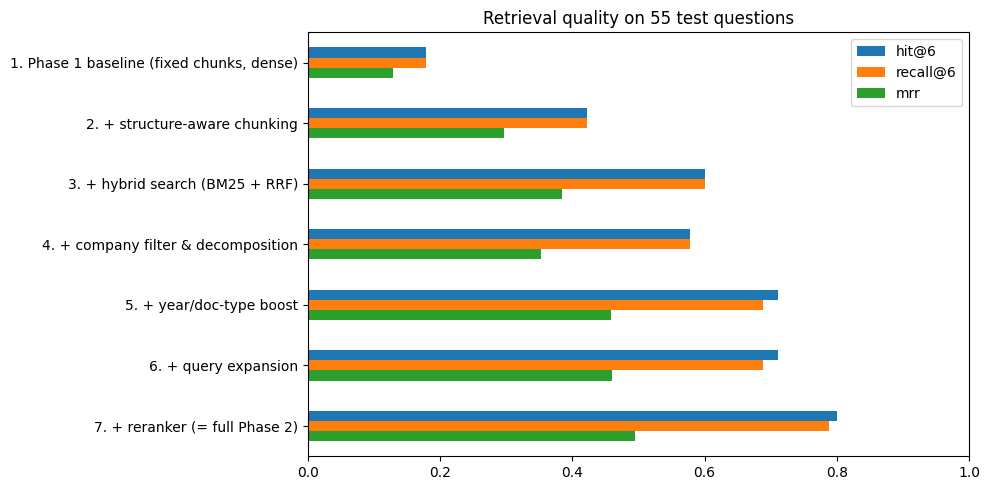


Recall@6 by question type:
| type       |   1. Phase 1 baseline |   7. + reranker |
|:-----------|----------------------:|----------------:|
| call       |                 0.3   |           0.8   |
| comparison |                 0     |           0.5   |
| guidance   |                 0     |           1     |
| lookup     |                 0.125 |           1     |
| table      |                 0.077 |           0.769 |
| temporal   |                 0     |           0     |


In [37]:
# ── Retrieval results: table, chart and breakdown by question type ──
import pandas as pd
import matplotlib.pyplot as plt

table = pd.DataFrame({n: r["summary"] for n, r in retrieval_results.items()}).T
print(md(table))
ax = table[[f"hit@{K}", f"recall@{K}", "mrr"]].plot.barh(figsize=(10, 5))
ax.invert_yaxis(); ax.set_xlim(0, 1); ax.set_title(f"Retrieval quality on {len(golden)} test questions")
plt.tight_layout(); plt.savefig(EVAL["dir"] / "retrieval_ablation.png", dpi=150); plt.show()

by_type = {}
for name in (ABLATIONS[0][0], ABLATIONS[-1][0]):
    df = pd.DataFrame(retrieval_results[name]["rows"])
    by_type[name.split(" (")[0]] = df.groupby("type")[f"recall@{K}"].mean().round(3)
print(f"\nRecall@{K} by question type:")
print(md(pd.DataFrame(by_type)))

Cell 9 (Answer scoring)

In [38]:
# ── PART B: answer scoring  (later file: evaluation/answer_eval.py) ──
JUDGE_PROMPT = """Grade the candidate answer against the reference answer for this question.
Question: {question}
Reference answer: {reference}
Candidate answer: {answer}
Score 1 if the candidate states the key facts of the reference (wording may differ), 0.5 if partly correct,
0 if wrong, missing or a refusal. Return JSON only: {"score": 0 | 0.5 | 1, "reason": "<one sentence>"}"""


def score_answer(q: dict, r: dict, judge=None) -> dict:
    """Numeric answers: numbers + units are checked exactly. Text answers: LLM judge."""
    s = {"refused": r["refused"], "grounded": r["grounded"], "n_citations": len(r["citations"])}
    if q["type"] == "unanswerable":
        s["correct"] = 1.0 if r["refused"] else 0.0
        s["method"] = "refusal"
        return s
    if r["refused"] or r.get("error"):
        s.update(correct=0.0, method="refused" if r["refused"] else "error")
    else:
        ref_nums = extract_numbers(q["answer"])
        if ref_nums:
            overlap = number_overlap(ref_nums, extract_numbers(r["answer"]))
            ref_units = extract_units(q["answer"])
            unit_ok = not ref_units or bool(ref_units & extract_units(r["answer"]))
            s["unit_error"] = overlap > 0 and not unit_ok
            s["correct"] = 0.0 if s["unit_error"] else (1.0 if overlap == 1 else 0.5 if overlap > 0 else 0.0)
            s["method"] = "numbers"
        elif judge is not None:
            prompt = (JUDGE_PROMPT.replace("{question}", q["question"]).replace("{reference}", q["answer"])
                      .replace("{answer}", r["answer"]))
            verdict = parse_json(paced_chat(judge, [{"role": "user", "content": prompt}]).text)
            s["correct"] = float(verdict.get("score", 0) or 0)
            s["judge_reason"] = verdict.get("reason", "")
            s["method"] = "judge"
        else:
            s.update(correct=None, method="not scored")
    cited = r["citations"]
    if cited:
        s["citation_precision"] = sum(any(ref_matches(c, e) for e in q["evidence"]) for c in cited) / len(cited)
    s["evidence_in_final"] = any(ref_matches(x, e) for x in r["sources"] for e in q["evidence"])
    s["evidence_in_candidates"] = any(ref_matches(x, e) for x in r["candidates"] for e in q["evidence"])
    return s

print("Answer scoring ready")

Answer scoring ready


Cell 10 (Run the answer evaluation) — 20–45 minutes; safe to stop and re-run

In [39]:
# ── Run the answer evaluation (safe to stop and re-run: continues where it left off) ──
EVAL["pause_seconds"] = 30       # ~3,500 tokens per question -> about 2 questions per minute under the 8K limit


def evaluate_answers(pipeline, questions, path, judge):
    done = {r["id"] for r in load_jsonl(path)}
    todo = [q for q in questions if q["id"] not in done]
    print(f"{len(done)} already done, {len(todo)} to go ...")
    for i, q in enumerate(todo, 1):
        wait = EVAL["pause_seconds"] - (time.time() - _last_call[0])
        if wait > 0:
            time.sleep(wait)
        try:
            r = pipeline.ask(q["question"])
            _last_call[0] = time.time()
            s = score_answer(q, r, judge)
        except DailyLimitError as exc:
            print(f"\nSTOPPED: daily token limit reached.\n{str(exc)[:220]}\n"
                  f"{i - 1} new results saved. Re-run this cell later to continue from question {len(done) + i}.")
            return
        append_jsonl(path, {"id": q["id"], "type": q["type"], "question": q["question"], "reference": q["answer"],
                            "answer": r["answer"], "citations": [c["label"] for c in r["citations"]],
                            "top_rerank_score": r.get("top_rerank_score"), "latency_ms": r["latency_ms"],
                            "tokens": r.get("tokens", {}), **s})
        if i % 10 == 0:
            print(f"  {i}/{len(todo)}")
    print("Done.")


judge_llm = llm_from_config({**CONFIG["generation"], "max_tokens": 800}, model=os.getenv("JUDGE_MODEL"))
ANSWERS_PATH = find_saved("answers_phase2.jsonl")  
evaluate_answers(pipe, golden, ANSWERS_PATH, judge_llm)

Loaded answers_phase2.jsonl from /kaggle/input/datasets/arpkr678/new-version-1-finsight-eval
56 already done, 0 to go ...
Done.


Cell 11 (Answer report)

In [40]:
# ── Answer results  (later file: evaluation/report.py) ──
def answer_report(path) -> pd.DataFrame:
    df = pd.DataFrame(load_jsonl(path))
    ans = df[df.type != "unanswerable"]
    una = df[df.type == "unanswerable"]
    answered = ans[~ans.refused]
    lat = [r["total"] for r in df.latency_ms if "total" in r]
    report = {
        "questions": len(df),
        "answer accuracy": round(ans.correct.dropna().mean(), 3),
        "fully correct (score = 1)": round((ans.correct == 1).mean(), 3),
        "unit errors": int(ans.get("unit_error", pd.Series(dtype=bool)).fillna(False).sum()),
        "citation precision": round(answered.citation_precision.dropna().mean(), 3) if "citation_precision" in answered else None,
        "answers without citations": int((~answered.grounded).sum()),
        "false refusal rate (answerable but refused)": round(ans.refused.mean(), 3),
        "correct refusal rate (unanswerable)": round(una.refused.mean(), 3) if len(una) else None,
        "median latency (s)": round(np.median(lat) / 1000, 2) if lat else None,
        "avg tokens per question": int(np.mean([t.get("input", 0) + t.get("output", 0) for t in df.tokens])),
    }
    print(md(pd.Series(report)))
    print("\nAccuracy by question type:")
    print(md(ans.groupby("type").correct.agg(["mean", "count"]).round(3)))
    return df


answers_df = answer_report(ANSWERS_PATH)

|                                             |        0 |
|:--------------------------------------------|---------:|
| questions                                   |   56     |
| answer accuracy                             |    0.685 |
| fully correct (score = 1)                   |    0.674 |
| unit errors                                 |    0     |
| citation precision                          |    0.638 |
| answers without citations                   |    0     |
| false refusal rate (answerable but refused) |    0.13  |
| correct refusal rate (unanswerable)         |    1     |
| median latency (s)                          |    1.62  |
| avg tokens per question                     | 2998     |

Accuracy by question type:
| type       |   mean |   count |
|:-----------|-------:|--------:|
| call       |  0.762 |      21 |
| comparison |  0.5   |       1 |
| guidance   |  1     |       1 |
| lookup     |  0.75  |       8 |
| table      |  0.538 |      13 |
| temporal   |  0.5   |   

/tmp/ipykernel_49/2220142940.py:12: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  "unit errors": int(ans.get("unit_error", pd.Series(dtype=bool)).fillna(False).sum()),


Cell 12 (Failure analysis)

In [41]:
# ── Failure analysis: WHY each answer failed  (later file: evaluation/failure_analysis.py) ──
def failure_category(row) -> str:
    if row["type"] == "unanswerable":
        return "ok" if row["refused"] else "hallucinated (answered an unanswerable question)"
    if row["correct"] == 1:
        return "ok"
    if not row["evidence_in_candidates"]:
        return "search miss (evidence never retrieved)"
    if not row["evidence_in_final"]:
        return "reranker drop (retrieved, then ranked out)"
    if row["refused"]:
        return "false refusal (evidence was given to the LLM)"
    if row.get("unit_error") is True:
        return "unit error (right number, wrong unit)"
    if row["correct"] == 0.5:
        return "partly correct (some facts missing)"
    return "LLM error (evidence given, answer wrong)"


answers_df["failure"] = answers_df.apply(failure_category, axis=1)
counts = answers_df.failure.value_counts()
print(md(pd.DataFrame({"count": counts, "share": (counts / len(answers_df)).round(3)})))
print("\nBy question type:")
print(md(pd.crosstab(answers_df.type, answers_df.failure)))

print("\nExamples to inspect:")
for category in counts.index:
    if category == "ok":
        continue
    for _, row in answers_df[answers_df.failure == category].head(2).iterrows():
        print(f"\n[{category}] {row['id']}: {row['question']}\n   expected: {row['reference']}\n   got:      {str(row['answer'])[:250]}")

# relevance gate: would a rerank-score threshold refuse unanswerable questions without losing good answers?
print("\nRelevance-gate threshold check (min_rerank_score):")
scored = answers_df.dropna(subset=["top_rerank_score"])
for t in [0.0, 0.1, 0.3, 0.5, 0.7, 0.9]:
    lost = ((scored.type != "unanswerable") & (scored.correct == 1) & (scored.top_rerank_score < t)).sum()
    caught = ((scored.type == "unanswerable") & ((scored.top_rerank_score < t) | scored.refused)).sum()
    print(f"  threshold {t:.1f}: correct answers lost = {lost:>3} | unanswerable refused = {caught}/{(scored.type == 'unanswerable').sum()}")
answers_df.to_csv(EVAL["dir"] / "answers_phase2_scored.csv", index=False)

| failure                                       |   count |   share |
|:----------------------------------------------|--------:|--------:|
| ok                                            |      41 |   0.732 |
| LLM error (evidence given, answer wrong)      |       5 |   0.089 |
| reranker drop (retrieved, then ranked out)    |       4 |   0.071 |
| search miss (evidence never retrieved)        |       3 |   0.054 |
| false refusal (evidence was given to the LLM) |       2 |   0.036 |
| partly correct (some facts missing)           |       1 |   0.018 |

By question type:
| type         |   LLM error (evidence given, answer wrong) |   false refusal (evidence was given to the LLM) |   ok |   partly correct (some facts missing) |   reranker drop (retrieved, then ranked out) |   search miss (evidence never retrieved) |
|:-------------|-------------------------------------------:|------------------------------------------------:|-----:|--------------------------------------:|--------------

Cell 13 (Re-score with improved scorer v2)

In [42]:
# ── Re-score saved answers with the improved scorer v2 (no LLM calls, no tokens)  (later file: evaluation/scoring.py) ──
# v2 fixes three scorer mistakes found in the first run:
#   1. number words ("four months" = 4)          2. unit conversion (₹16,103,480,210 thousand = ₹16,103.48 billion)
#   3. currency errors per number (₹ vs US$)
NUMBER_WORDS = {"zero": 0, "one": 1, "two": 2, "three": 3, "four": 4, "five": 5, "six": 6, "seven": 7, "eight": 8,
                "nine": 9, "ten": 10, "eleven": 11, "twelve": 12, "fifteen": 15, "twenty": 20, "thirty": 30,
                "forty": 40, "fifty": 50, "hundred": 100}
SCALE = {"thousand": 1e3, "lakh": 1e5, "million": 1e6, "crore": 1e7, "billion": 1e9}
_AMOUNT_RE = re.compile(r"(₹|Rs\.?|INR|US\$|USD|\$)?\s?(?<![\w.])(\d+(?:\.\d+)?)\s*"
                        r"(thousand|lakhs?|million|mn\b|crores?|cr\b|billion|bn\b)?", re.I)


def _clean(text: str) -> str:
    t = _YEAR_RE.sub(" ", _DATE_RE.sub(" ", text or ""))
    t = re.sub(r"(?<=\d),(?=\d)", "", t)
    for word, value in NUMBER_WORDS.items():
        t = re.sub(rf"\b{word}\b", str(value), t, flags=re.I)
    return t


def amounts(text: str) -> list[tuple[float, str]]:
    """Every number as (absolute value, currency): 'US$16,103.48 billion' -> (1.610348e13, 'USD')."""
    out = []
    for cur, num, scale in _AMOUNT_RE.findall(_clean(text)):
        word = (scale or "").lower().rstrip("s")
        word = {"mn": "million", "cr": "crore", "bn": "billion"}.get(word, word)
        cur = "USD" if cur.upper() in ("US$", "USD", "$") else "INR" if cur else ""
        out.append((float(num) * SCALE.get(word, 1), cur))
    return out


def score_numeric_v2(reference: str, answer: str) -> dict:
    """Each reference number must appear in the answer (same value after unit conversion, 0.5% tolerance).
    If both sides state a currency for that number and they differ (₹ vs US$), it is a currency error."""
    ref, ans = amounts(reference), amounts(answer)
    if not ref:
        return {}
    hits, currency_error = 0, False
    for value, cur in ref:
        match = [c for v, c in ans if abs(v - value) <= 0.005 * max(abs(value), 1e-9)]
        if match:
            hits += 1
            if cur and all(c and c != cur for c in match):
                currency_error = True
    share = hits / len(ref)
    correct = 0.0 if currency_error else (1.0 if share == 1 else 0.5 if share > 0 else 0.0)
    return {"correct": correct, "currency_error": currency_error, "number_match": round(share, 2)}


def rescore(path, out_path, drop_ids=()):
    rows = []
    for r in load_jsonl(path):
        if r["id"] in drop_ids:
            continue
        r["correct_v1"] = r.get("correct")
        if r["type"] != "unanswerable" and not r["refused"] and r.get("method") == "numbers":
            r.update(score_numeric_v2(r["reference"], r["answer"]))
            r["unit_error"] = False
        rows.append(r)
    write_jsonl(out_path, rows)
    changed = [r for r in rows if r.get("correct") != r.get("correct_v1")]
    print(f"Re-scored {len(rows)} answers | {len(changed)} changed:")
    for r in changed:
        print(f"  {r['id']}: {r['correct_v1']} -> {r['correct']}"
              f"{'  (currency error)' if r.get('currency_error') else ''} | {str(r['answer'])[:110]}")
    return rows


def failure_category_v2(row) -> str:
    if row.get("currency_error") is True:
        return "currency error (right number, wrong currency)"
    return failure_category(row)


ANSWERS_V2_PATH = EVAL["dir"] / "answers_phase2_v2.jsonl"
rescore(ANSWERS_PATH, ANSWERS_V2_PATH, drop_ids={"g017"})     # g017: scanned transcript misread "100%" -> data problem
print()
answers_v2 = answer_report(ANSWERS_V2_PATH)
answers_v2["failure"] = answers_v2.apply(failure_category_v2, axis=1)
counts = answers_v2.failure.value_counts()
print("\nFailure breakdown (v2):")
print(md(pd.DataFrame({"count": counts, "share": (counts / len(answers_v2)).round(3)})))
print("\nAll remaining failures:")
for _, row in answers_v2[answers_v2.failure != "ok"].iterrows():
    print(f"  [{row['failure'].split(' (')[0]}] {row['id']} ({row['type']}): {row['question'][:90]}")
answers_v2.to_csv(EVAL["dir"] / "answers_phase2_v2_scored.csv", index=False)

Re-scored 55 answers | 6 changed:
  g011: 0.0 -> 1.0 | HDFC Bank's FY2026 Q4 earnings call stated that time deposit rates have remained unchanged in the market for t
  g015: 1.0 -> 0.0 | ICICI Bank's cash flow statement for the year ended 31.03.2025 reported an increase in deposits of ₹1,980,574,
  g045: 1.0 -> 0.0 | ICICI Bank's total cash and balances with the Reserve Bank of India as of 31.03.2025 was ₹1,202,409,132 [1].
  g089: 0.0 -> 1.0 | ICICI Bank's total deposits at March 31, 2025 were ₹16,103.48 billion[2].
  m002: 0.0 -> 1.0 | ICICI Bank’s total provisions during Q4 FY2025 were ₹8.91 billion Rupees, whereas in Q4 FY2026 they were ₹0.96
  m003: 0.5 -> 0.0  (currency error) | HDFC Bank’s total deposits as of March 31, 2026 were ₹3,099,638.29 crore[1], whereas ICICI Bank’s total deposi

|                                             |        0 |
|:--------------------------------------------|---------:|
| questions                                   |   55     |
| answer accuracy

/tmp/ipykernel_49/2220142940.py:12: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  "unit errors": int(ans.get("unit_error", pd.Series(dtype=bool)).fillna(False).sum()),


Phase 4 section

Cell 1 (Build the Phase 4 index) — re-chunks from the parse cache, ~5 minutes, no tokens

In [43]:
# ── Phase 4 config: same as Phase 2 + unit headers + flattened table headers ──
import pandas as pd

PHASE4_OVERRIDES = {"chunker_version": "2.4",
                    "chunking": {"unit_headers": True, "flatten_headers": True}}
CONFIG_P4 = deep_update(CONFIG, PHASE4_OVERRIDES)
print("Phase 2 index:", index_key(CONFIG))
print("Phase 4 index:", index_key(CONFIG_P4))
stats_p4 = ingest(CONFIG_P4)          # re-chunks from the parse cache (no re-parsing), then embeds
print({k: v for k, v in stats_p4.items() if k != "failed"})

index_p4 = get_index(CONFIG_P4)
chunks_p4 = list(index_p4.chunks.values())
with_unit = [c for c in chunks_p4 if "| amounts in " in c.text.split("\n")[0]]
print(f"\n{len(with_unit)} of {len(chunks_p4)} chunks ({len(with_unit) / len(chunks_p4):.0%}) now carry a unit in their header")
print("Units found:", dict(Counter(c.text.split("| amounts in ")[1].split("]")[0] for c in with_unit).most_common()))
print("By company:", {co: f"{sum(c.metadata['company'] == co for c in with_unit) / max(1, sum(c.metadata['company'] == co for c in chunks_p4)):.0%}"
                      for co in COMPANIES})

Phase 2 index: structure512o64m200d__bge-small-en-v1.5__p2.2c2.3
Phase 4 index: structure512o64m200ufd__bge-small-en-v1.5__p2.2c2.4
{'index': 'structure512o64m200ufd__bge-small-en-v1.5__p2.2c2.4', 'added': 36, 'skipped': 0, 'chunks_added': 21321, 'table_chunks': 4408, 'duplicates_dropped': 798, 'unmatched_filenames': [], 'total_chunks': 21321, 'minutes': 3.8}

8447 of 21321 chunks (40%) now carry a unit in their header
Units found: {'₹ crore': 4601, '₹ million': 3141, '₹ thousand': 399, '₹ billion': 206, '₹ lakh': 67, 'US$ billion': 18, 'US$ million': 15}
By company: {'TCS': '46%', 'INFY': '29%', 'WIPRO': '59%', 'HDFCBANK': '22%', 'ICICIBANK': '38%', 'HINDUNILVR': '44%'}


Cell 2 (See the difference) — no tokens

In [44]:
# ── See the difference: the same table chunks in Phase 2 vs Phase 4 ──
def find_chunk(index, text, doc_prefix):
    return next((c for c in index.chunks.values() if text in c.text and c.doc_id.startswith(doc_prefix)), None)

for label, needle, doc in [("ICICI cash and balances with RBI (g045)", "1,202,409,132", "ICICIBANK_FY2025"),
                           ("TCS attrition by gender (g013)", "13.4", "TCS_FY2026"),
                           ("Wipro plan assets (g072)", "15,717", "WIPRO_FY2024")]:
    print(f"\n{'=' * 100}\n{label}")
    for name, idx in (("PHASE 2", get_index(CONFIG)), ("PHASE 4", index_p4)):
        c = find_chunk(idx, needle, doc)
        print(f"--- {name}: " + ("(not found)" if c is None else f"{c.source_label()}\n{c.text[:450]}"))


ICICI cash and balances with RBI (g045)
--- PHASE 2: ICICI Bank FY2025 Annual Report, p. 333 (CONSOLIDATED BALANCE SHEET)
[ICICI Bank FY2025 Annual Report | CONSOLIDATED BALANCE SHEET]
|  | Schedule | At 31.03.2025 | At 31.03.2024 |
| --- | --- | --- | --- |
| CAPITAL AND LIABILITIES |  |  |  |
| Capital | 1 | 14,245,974 | 14,046,790 |
| Employees stock options/units outstanding | 1A | 20,698,433 | 14,053,180 |
| Reserves and surplus | 2 | 3,104,114,654 | 2,533,338,376 |
| Minority interest | 2A | 148,367,361 | 138,884,162 |
| Deposits | 3 | 16,416,374,040 | 14,435,
--- PHASE 4: ICICI Bank FY2025 Annual Report, p. 333 (CONSOLIDATED BALANCE SHEET)
[ICICI Bank FY2025 Annual Report | CONSOLIDATED BALANCE SHEET | amounts in ₹ thousand]
|  | Schedule | At 31.03.2025 | At 31.03.2024 |
| --- | --- | --- | --- |
| CAPITAL AND LIABILITIES |  |  |  |
| Capital | 1 | 14,245,974 | 14,046,790 |
| Employees stock options/units outstanding | 1A | 20,698,433 | 14,053,180 |
| Reserves and surplus | 2 

Cell 3 (Retrieval: Phase 2 vs Phase 4, 6 vs 8 chunks) — no tokens, ~3 minutes

In [45]:
# ── Retrieval: Phase 2 vs Phase 4, with 6 and 8 chunks sent to the LLM (no LLM calls) ──
questions = [q for q in golden if q["id"] not in {"g017"}]
setups = [("Phase 2, k=6", CONFIG, 6), ("Phase 2, k=8", CONFIG, 8),
          ("Phase 4, k=6", CONFIG_P4, 6), ("Phase 4, k=8", CONFIG_P4, 8)]
ret_p4 = {}
for name, base, k in setups:
    cfg = deep_update(base, {"retrieval": {"final_k": k}})
    summary, rows = evaluate_retrieval(RAGPipeline(cfg), questions, k)
    summary = {m.replace(f"@{k}", "@k"): v for m, v in summary.items()}      # same column names for k=6 and k=8
    ret_p4[name] = {"summary": summary, "rows": rows}
table_p4 = pd.DataFrame({n: r["summary"] for n, r in ret_p4.items()}).T
print(md(table_p4))
gain = table_p4.loc["Phase 4, k=8", "hit@k"] - table_p4.loc["Phase 4, k=6", "hit@k"]
n_answerable = len([q for q in questions if q["evidence"]])
print(f"\nSending 8 chunks instead of 6 finds the evidence for {round(gain * n_answerable)} more question(s) "
      f"(+{gain:.1%}), at about 33% more tokens per question.")
print("Recommendation:", "use k=8" if gain * n_answerable >= 2 else "keep k=6 (gain too small for the extra tokens)")

|              |   hit@k |   recall@k |   mrr |   ndcg@k |   candidate_recall |
|:-------------|--------:|-----------:|------:|---------:|-------------------:|
| Phase 2, k=6 |   0.8   |      0.789 | 0.495 |    0.608 |              0.922 |
| Phase 2, k=8 |   0.822 |      0.8   | 0.498 |    0.633 |              0.922 |
| Phase 4, k=6 |   0.8   |      0.789 | 0.483 |    0.599 |              0.889 |
| Phase 4, k=8 |   0.822 |      0.8   | 0.485 |    0.62  |              0.889 |

Sending 8 chunks instead of 6 finds the evidence for 1 more question(s) (+2.2%), at about 33% more tokens per question.
Recommendation: keep k=6 (gain too small for the extra tokens)


Cell 4 (Answer evaluation) — uses ~170K gpt-oss-20b tokens (k=6); safe to stop and re-run

In [46]:
# ── Answer evaluation for Phase 4 (uses gpt-oss-20b budget; safe to stop and re-run) ──
P4_FINAL_K = 6            # Cell 3 showed k=8 finds only 1 more question for 33% more tokens, so keep 6
CONFIG_P4 = deep_update(CONFIG_P4, {"retrieval": {"final_k": P4_FINAL_K}})
pipe_p4 = RAGPipeline(CONFIG_P4)
EVAL["pause_seconds"] = 30
ANSWERS_P4_PATH = EVAL["dir"] / f"answers_phase4_k{P4_FINAL_K}.jsonl"
evaluate_answers(pipe_p4, questions, ANSWERS_P4_PATH, judge_llm)
ANSWERS_P4_V2_PATH = EVAL["dir"] / f"answers_phase4_k{P4_FINAL_K}_v2.jsonl"
rescore(ANSWERS_P4_PATH, ANSWERS_P4_V2_PATH, drop_ids={"g017"})

0 already done, 55 to go ...
  10/55
  20/55
  30/55
  40/55
  50/55
Done.
Re-scored 55 answers | 4 changed:
  g089: 0.0 -> 1.0 | ICICI Bank's total deposits for the financial year ended 31 March 2025 were ₹16,103.48 billion[2]
  g124: 0.0 -> 1.0 | ICICI Bank's total provisions during Q4‑2025 were ₹8.91 billion Rupees[2][3].
  m002: 0.5 -> 1.0 | ICICI Bank’s total provisions during Q4 FY2025 were ₹8.91 billion Rupees, whereas in Q4 FY2026 they were ₹96 c
  m003: 0.5 -> 1.0 | HDFC Bank’s total deposits as of March 31, 2026 were ₹3,099,638.29 crore [5].  
ICICI Bank’s total deposits as


[{'id': 'g002',
  'type': 'call',
  'question': "What are the sizes of ICICI Bank's credit card and unsecured personal loan portfolios in FY2025 Q4?",
  'reference': 'Credit card: ₹57,000 crore; Personal loan: ₹1,21,000 crore',
  'answer': 'ICICI Bank’s credit card portfolio in FY2025 Q4 was ₹57,000\u202fcrore, and its unsecured personal loan portfolio was ₹1,21,000\u202fcrore[3].',
  'citations': ['ICICI Bank FY2025 Q4 Earnings Call, pp. 26-27 (RANJAN)'],
  'top_rerank_score': 0.9993122816085815,
  'latency_ms': {'retrieval': 1043, 'generation': 2079, 'total': 3122},
  'tokens': {'input': 3566, 'output': 84},
  'refused': False,
  'grounded': True,
  'n_citations': 1,
  'unit_error': False,
  'correct': 1.0,
  'method': 'numbers',
  'citation_precision': 1.0,
  'evidence_in_final': True,
  'evidence_in_candidates': True,
  'correct_v1': 1.0,
  'currency_error': False,
  'number_match': 1.0},
 {'id': 'g007',
  'type': 'table',
  'question': "What was Tata Consultancy Services' EBIT as 

Cell 5 (Before vs after report) — no tokens

In [47]:
# ── Before vs after: Phase 2 vs Phase 4 answers (no LLM calls) ──
def answer_summary(path) -> dict:
    df = pd.DataFrame(load_jsonl(path))
    ans, una = df[df.type != "unanswerable"], df[df.type == "unanswerable"]
    answered = ans[~ans.refused]
    return {"answer accuracy": round(ans.correct.mean(), 3),
            "table accuracy": round(ans[ans.type == "table"].correct.mean(), 3),
            "currency errors": int(ans.get("currency_error", pd.Series(dtype=object)).eq(True).sum()),
            "false refusal rate": round(ans.refused.mean(), 3),
            "correct refusal rate": round(una.refused.mean(), 3) if len(una) else None,
            "citation precision": round(answered.citation_precision.dropna().mean(), 3),
            "avg tokens": int(np.mean([t.get("input", 0) + t.get("output", 0) for t in df.tokens]))}


before, after = pd.DataFrame(load_jsonl(ANSWERS_V2_PATH)), pd.DataFrame(load_jsonl(ANSWERS_P4_V2_PATH))
print(md(pd.DataFrame({"Phase 2": answer_summary(ANSWERS_V2_PATH), "Phase 4": answer_summary(ANSWERS_P4_V2_PATH)})))

print("\nAccuracy by question type:")
by_type = pd.DataFrame({"Phase 2": before[before.type != "unanswerable"].groupby("type").correct.mean(),
                        "Phase 4": after[after.type != "unanswerable"].groupby("type").correct.mean(),
                        "questions": after[after.type != "unanswerable"].groupby("type").size()}).round(3)
print(md(by_type))

merged = before[["id", "type", "question", "correct"]].merge(after[["id", "correct", "answer"]], on="id", suffixes=("_p2", "_p4"))
fixed = merged[merged.correct_p4 > merged.correct_p2]
broken = merged[merged.correct_p4 < merged.correct_p2]
print(f"\nFIXED by Phase 4 ({len(fixed)}):")
for _, r in fixed.iterrows():
    print(f"  {r['id']} ({r['type']}): {r['correct_p2']} -> {r['correct_p4']} | {str(r['answer'])[:100]}")
print(f"\nBROKEN by Phase 4 ({len(broken)}):")
for _, r in broken.iterrows():
    print(f"  {r['id']} ({r['type']}): {r['correct_p2']} -> {r['correct_p4']} | {str(r['answer'])[:100]}")

after["failure"] = after.apply(failure_category_v2, axis=1)
print("\nPhase 4 remaining failures:")
for _, row in after[after.failure != "ok"].iterrows():
    print(f"  [{row['failure'].split(' (')[0]}] {row['id']} ({row['type']}): {row['question'][:85]}")

|                      |   Phase 2 |   Phase 4 |
|:---------------------|----------:|----------:|
| answer accuracy      |     0.711 |     0.844 |
| table accuracy       |     0.462 |     0.769 |
| currency errors      |     1     |     0     |
| false refusal rate   |     0.133 |     0.067 |
| correct refusal rate |     1     |     0.9   |
| citation precision   |     0.628 |     0.61  |
| avg tokens           |  2989     |  3053     |

Accuracy by question type:
| type       |   Phase 2 |   Phase 4 |   questions |
|:-----------|----------:|----------:|------------:|
| call       |     0.85  |     0.85  |          20 |
| comparison |     0     |     1     |           1 |
| guidance   |     1     |     1     |           1 |
| lookup     |     0.75  |     0.875 |           8 |
| table      |     0.462 |     0.769 |          13 |
| temporal   |     1     |     1     |           2 |

FIXED by Phase 4 (6):
  g015 (table): 0.0 -> 1.0 | ICICI Bank's cash flow statement for the year ended 31.

Cell 6: look at the pages behind the 3 “wrong” table answers

g072: What was the fair value of Wipro's defined benefit plan assets at the end of FY2024?
  Test-set answer (reference): ₹15,717 million
  System answer:               Wipro's defined benefit plan assets had a fair value of ₹18,005 million at the end of FY2024 (as of March 31, 2024)[1]

  Cited: Wipro FY2024 Annual Report, p. 437 (Notes to the Consolidated Financial Statements)


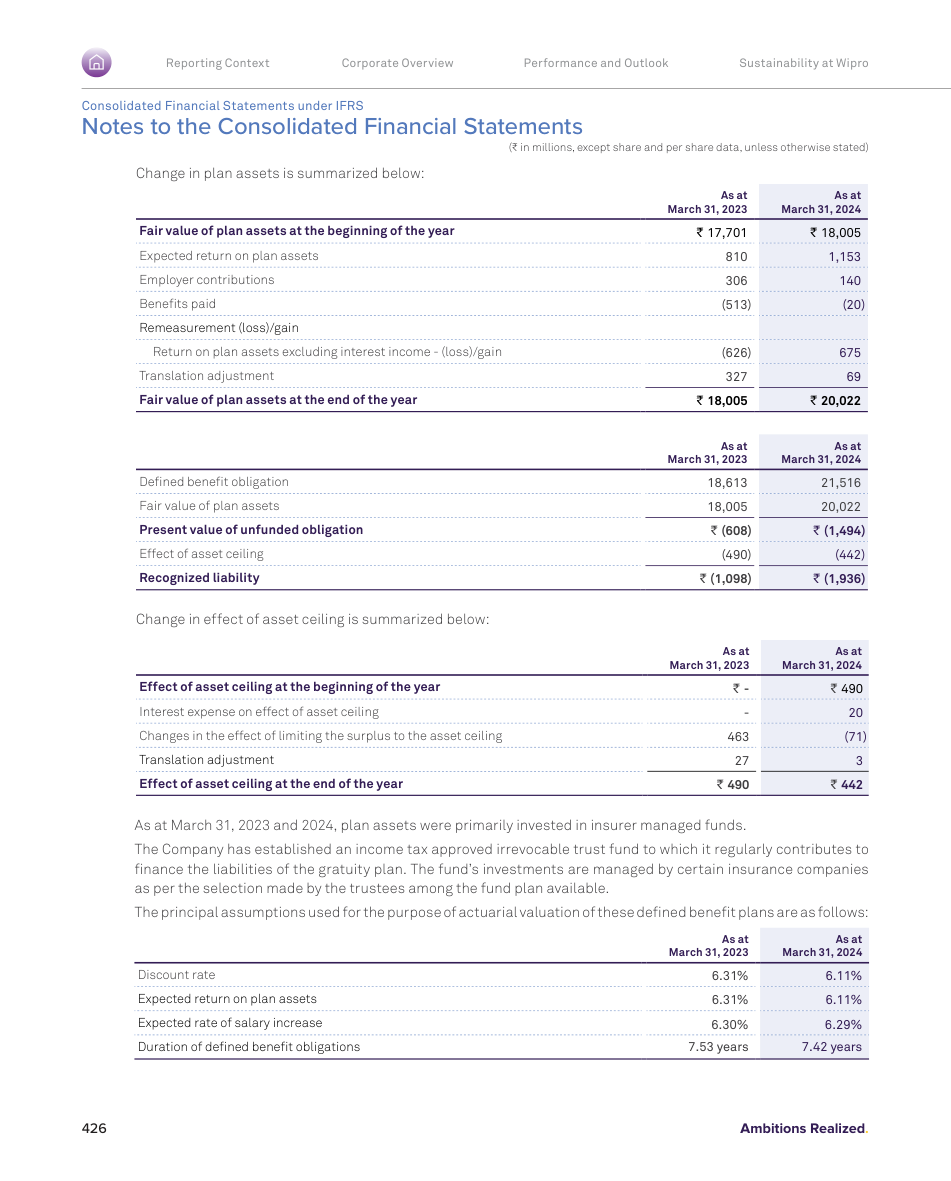

g131: What was Hindustan Unilever's total cash and cash equivalents as at 31 March 2025?
  Test-set answer (reference): ₹5,947 crore
  System answer:               Hindustan Unilever's total cash and cash equivalents as at 31 March 2025 were ₹6,071 crore[1].

  Cited: Hindustan Unilever FY2025 Annual Report, p. 212 (Income, Expenses, Gains or Losses on Financial Instruments)


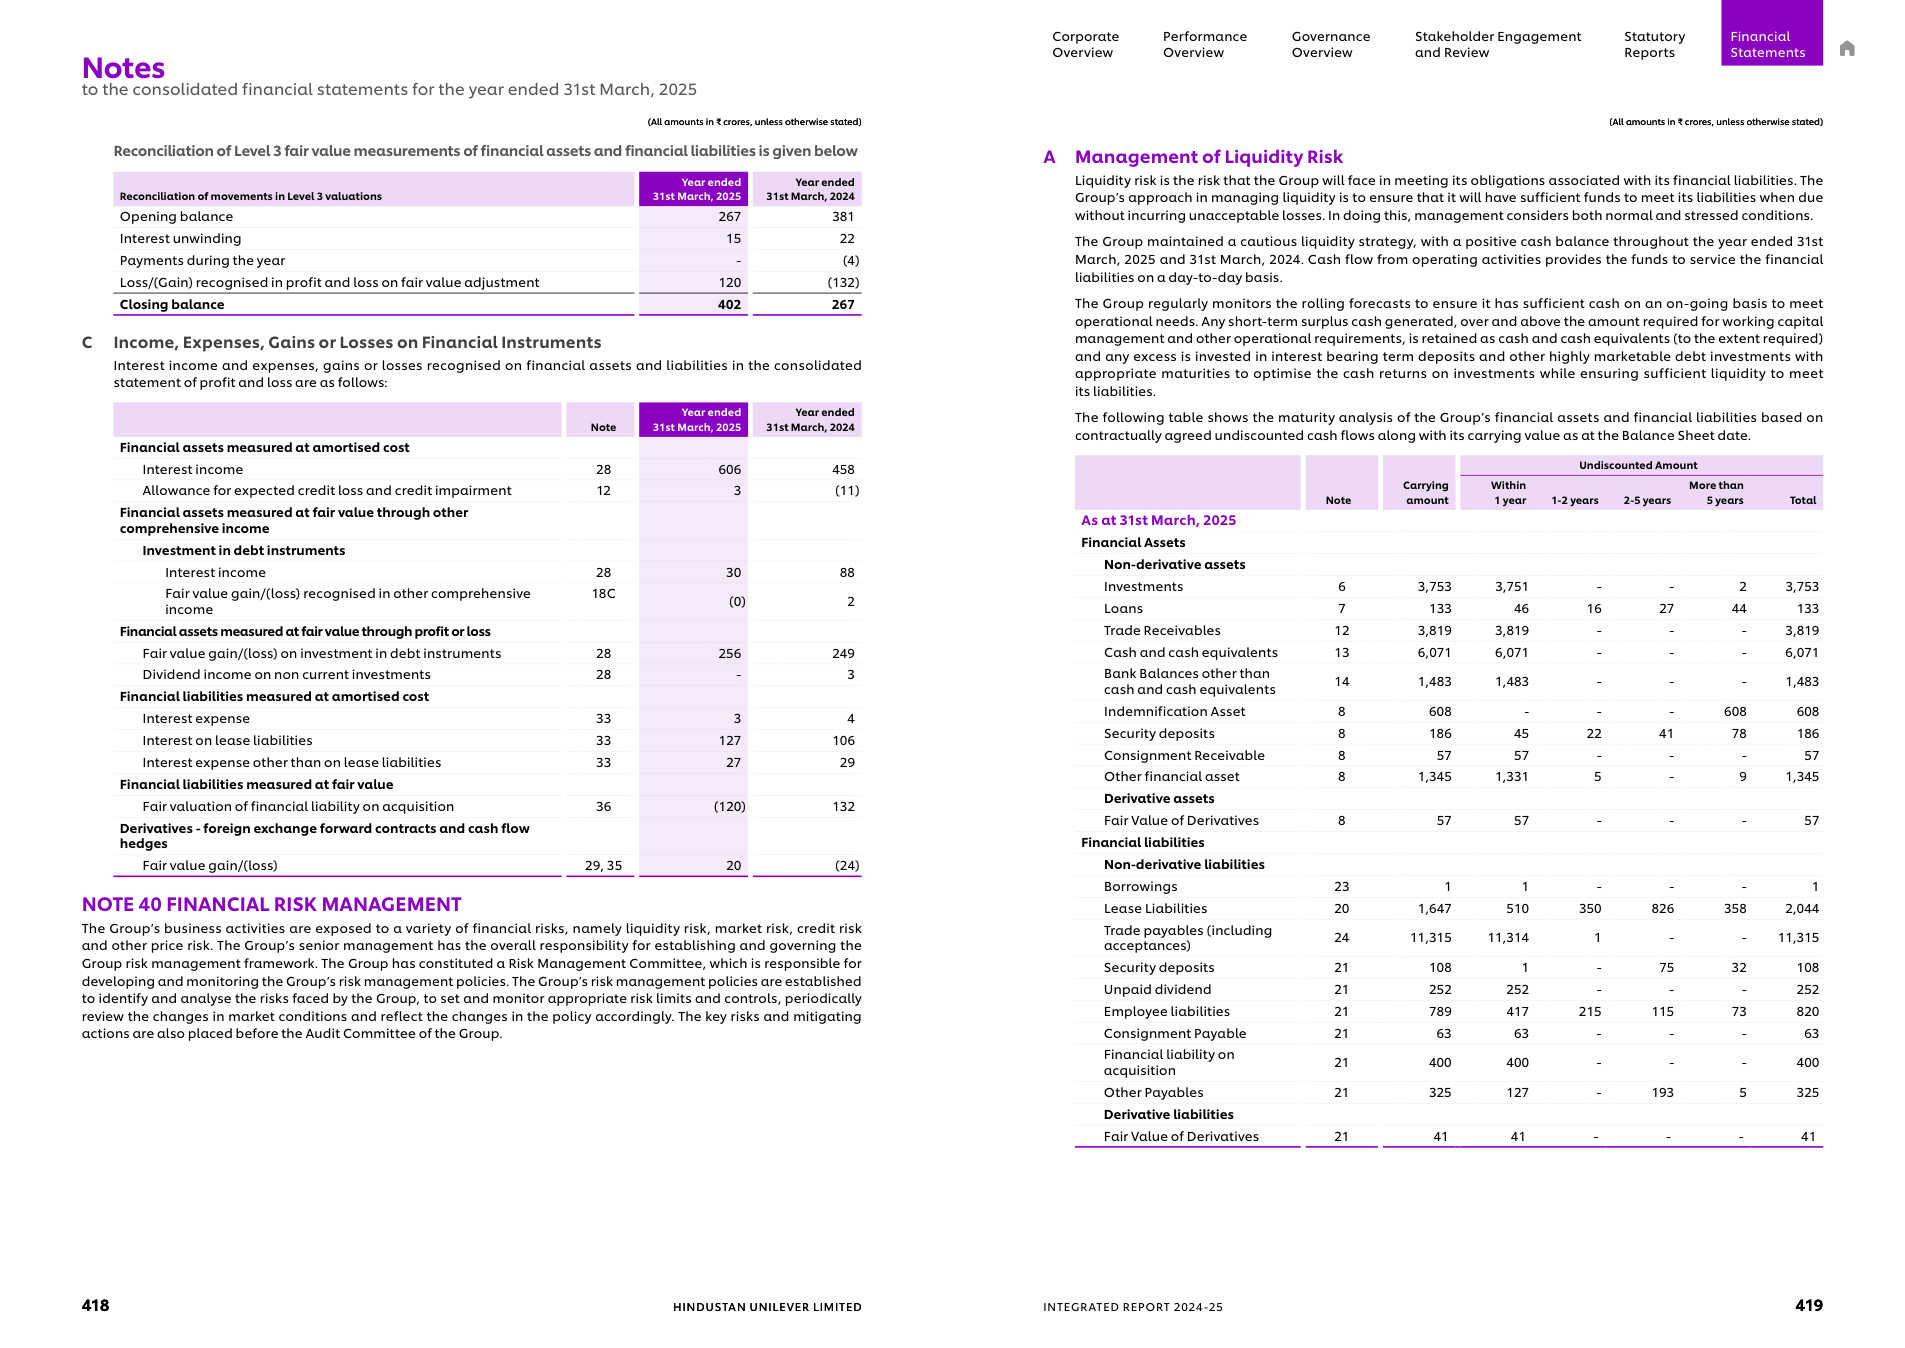

g150: What is the aggregate value of the transaction price allocated to unsatisfied (or partially satisfied) performance obligations for Tata Consultancy Services in FY2025, and what percentage of this amount is expected to be recognised as revenue in the next year?
  Test-set answer (reference): ₹1,55,554 crore, 46.47% expected to be recognised as revenue in the next year
  System answer:               Tata Consultancy Services' aggregate value of the transaction price allocated to unsatisfied (or partially satisfied) performance obligations for FY2025 is ₹1,84,432 crore, of which 46.03% is expected to be recognised as revenue in the next year [1].

  Cited: Tata Consultancy Services FY2025 Annual Report, p. 216 (Notes forming part of Consolidated Financial Statements)


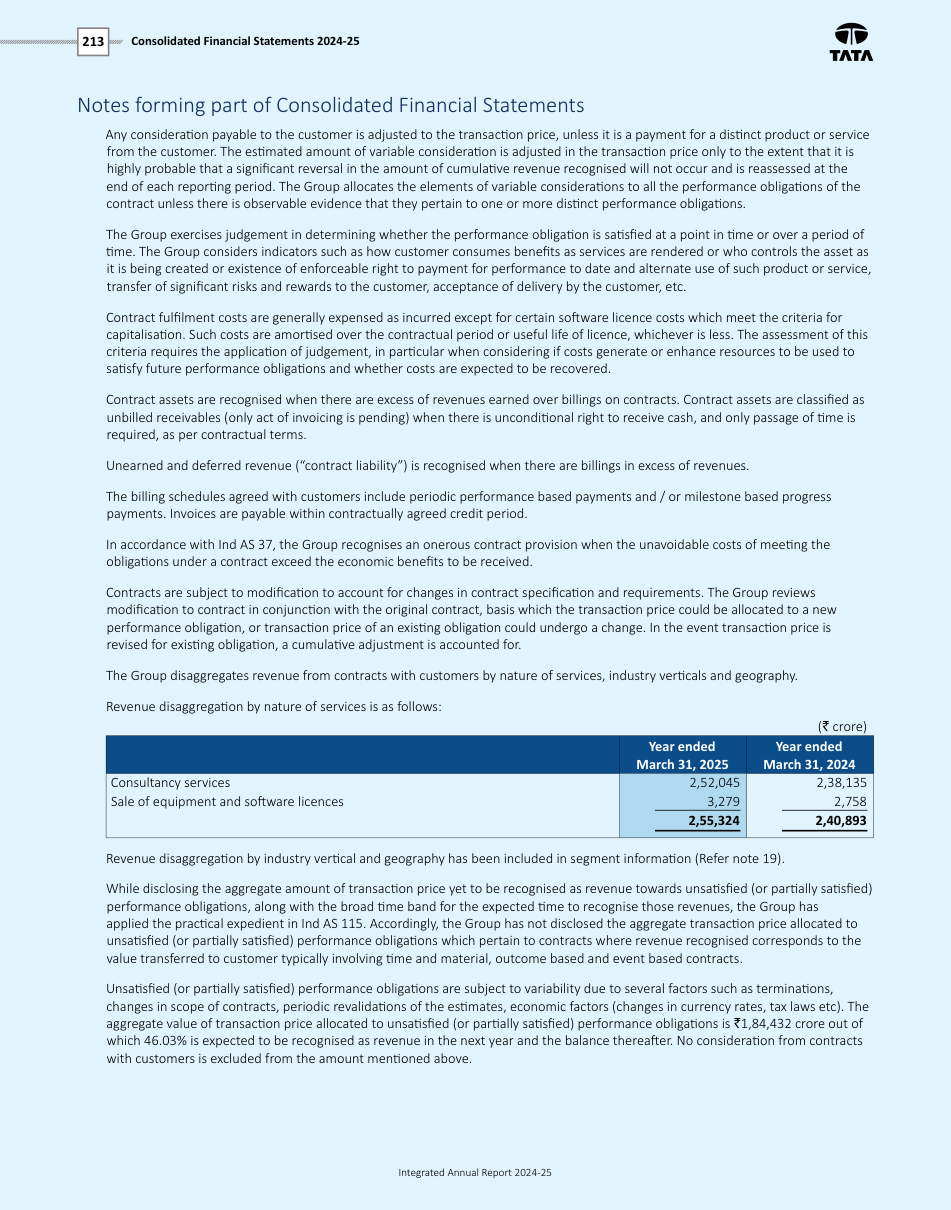

In [48]:
# ==== P4 CELL 6 ====
# (later file: notebooks only - evaluation helper, not part of the app)
# ── Show the PDF pages the system cited, for the standalone vs consolidated questions ──
from IPython.display import Image, display

# Works even after a kernel restart, as long as the Phase 2, Phase 3 and Phase 4 Cell 1 cells were run
if "ANSWERS_P4_V2_PATH" not in globals():
    ANSWERS_P4_V2_PATH = find_saved("answers_phase4_k6_v2.jsonl")
if "ANSWERS_V2_PATH" not in globals():
    ANSWERS_V2_PATH = find_saved("answers_phase2_v2.jsonl")

PDF_BY_STEM = {p.stem: p for p in Path(CONFIG["data"]["raw_dir"]).rglob("*.pdf")}
TITLE_TO_DOC = {}
for c in index_p4.chunks.values():
    title = (getattr(c, "metadata", None) or {}).get("title")
    if title:
        TITLE_TO_DOC.setdefault(title, c.doc_id)


def show_cited_pages(answer_id: str, path=None, zoom: float = 1.6):
    """Prints the question, the test-set answer and the system's answer, then shows every cited PDF page."""
    rows = {x["id"]: x for x in load_jsonl(path or ANSWERS_P4_V2_PATH)}
    if answer_id not in rows:
        print("No answer with id", answer_id)
        return
    r = rows[answer_id]
    print("=" * 100)
    print(f"{answer_id}: {r['question']}")
    print(f"  Test-set answer (reference): {r['reference']}")
    print(f"  System answer:               {r['answer']}")
    for label in r.get("citations") or []:
        m = re.match(r"(.+?), pp?\. (\d+)(?:-(\d+))?", label)
        doc_id = TITLE_TO_DOC.get(m.group(1)) if m else None
        if not doc_id or doc_id not in PDF_BY_STEM:
            print("  (could not locate this citation)", label)
            continue
        first, last = int(m.group(2)), int(m.group(3) or m.group(2))
        print(f"\n  Cited: {label}")
        with pymupdf.open(PDF_BY_STEM[doc_id]) as doc:
            for p in range(first, min(last, len(doc)) + 1):
                display(Image(data=doc[p - 1].get_pixmap(matrix=pymupdf.Matrix(zoom, zoom)).tobytes("png")))

show_cited_pages("g072")   # Wipro plan assets FY2024: is ₹18,005 million in the CONSOLIDATED statements?
show_cited_pages("g131")   # HUL cash & cash equivalents 31 Mar 2025: is ₹6,071 crore CONSOLIDATED?
show_cited_pages("g150")   # TCS unsatisfied performance obligations: is ₹1,84,432 crore / 46.03% CONSOLIDATED?

Cell 7: final Phase 4 numbers

In [50]:
# ==== P4 CELL 7 ====
# (later file: finsight/eval/finalise.py)
# ── Final Phase 4 numbers: ambiguous questions, relevance gate, refusal detection (no LLM calls) ──

# 1. Consolidated figures CHECKED on the cited pages in Cell 6.
#    The questions did not say standalone or consolidated, so both answers count.
ACCEPT_ALSO = {
    "g131": "₹6,071 crore",               # HUL consolidated cash and cash equivalents, 31 March 2025 (verified, p. 212)
    "g150": "₹1,84,432 crore, 46.03%",    # TCS consolidated unsatisfied performance obligations, FY2025 (verified, p. 216)
    # g072 NOT accepted: system gave ₹18,005 million = FY2023 column. Correct consolidated FY2024 is ₹20,022 million.
}

# 2. Relevance gate: if the best reranker score is below this, refuse without calling the LLM.
#    Every correct answer scored >= 0.985. The hallucinated u005 scored 0.13.
GATE = 0.3


def finalise(path, out_path, gate=GATE, accept_also=None):
    accept_also = accept_also or {}
    rows = []
    for r in load_jsonl(path):
        r = dict(r)
        # a) the question was ambiguous (standalone vs consolidated) -> accept the verified consolidated figure too
        if r["type"] != "unanswerable" and r["id"] in accept_also and not r["refused"]:
            alt = score_numeric_v2(accept_also[r["id"]], r["answer"])
            if alt and alt["correct"] > (r.get("correct") or 0):
                r.update(alt, accepted_alternative=True)
        # b) the model wrote NOT_FOUND in the middle of an answer (g100) -> that is a refusal
        if not r["refused"] and "NOT_FOUND" in str(r["answer"]).upper():
            r.update(refused=True, refusal_mid_answer=True)
        # c) gate: weak evidence -> refuse before the LLM ever sees it
        score = r.get("top_rerank_score")
        if not r["refused"] and score is not None and score < gate:
            r.update(refused=True, gated=True)
        # recompute correctness
        if r["type"] == "unanswerable":
            r["correct"] = 1.0 if r["refused"] else 0.0
        elif r["refused"]:
            r["correct"] = 0.0
        rows.append(r)
    write_jsonl(out_path, rows)
    return rows


FINAL_P4_PATH = EVAL["dir"] / "answers_phase4_final.jsonl"
final_rows = finalise(ANSWERS_P4_V2_PATH, FINAL_P4_PATH, GATE, ACCEPT_ALSO)

print(md(pd.DataFrame({"Phase 2": answer_summary(ANSWERS_V2_PATH),
                       "Phase 4 (raw)": answer_summary(ANSWERS_P4_V2_PATH),
                       "Phase 4 (final)": answer_summary(FINAL_P4_PATH)})))

print("\nWhat changed in 'final':")
for r in final_rows:
    notes = [n for n, flag in (("gated (refused before the LLM)", r.get("gated")),
                               ("NOT_FOUND found mid-answer", r.get("refusal_mid_answer")),
                               ("consolidated figure accepted", r.get("accepted_alternative"))) if flag]
    if notes:
        print(f"  {r['id']} ({r['type']}): {', '.join(notes)} -> correct = {r['correct']}  "
              f"(top rerank {r.get('top_rerank_score')})")

gated = [r for r in final_rows if r.get("gated")]
gated_answerable = [r for r in gated if r["type"] != "unanswerable"]
print(f"\nGate check: {len(gated)} question(s) gated, {len(gated_answerable)} of them answerable (should be 0).")

|                      |   Phase 2 |   Phase 4 (raw) |   Phase 4 (final) |
|:---------------------|----------:|----------------:|------------------:|
| answer accuracy      |     0.711 |           0.844 |             0.889 |
| table accuracy       |     0.462 |           0.769 |             0.846 |
| currency errors      |     1     |           0     |             0     |
| false refusal rate   |     0.133 |           0.067 |             0.089 |
| correct refusal rate |     1     |           0.9   |             1     |
| citation precision   |     0.628 |           0.61  |             0.61  |
| avg tokens           |  2989     |        3053     |          3053     |

What changed in 'final':
  g100 (call): NOT_FOUND found mid-answer -> correct = 0.0  (top rerank 0.9855051636695862)
  g131 (table): consolidated figure accepted -> correct = 1.0  (top rerank 0.9997043013572693)
  g150 (lookup): consolidated figure accepted -> correct = 1.0  (top rerank 0.9999665021896362)
  u005 (unanswer

In [51]:
!cd /kaggle/working && rm -f finsight_eval.zip && zip -rqj finsight_eval.zip eval/*.jsonl eval/*.json eval/*.csv eval/*.png; ls -lh finsight_eval.zip && unzip -l finsight_eval.zip

-rw-r--r-- 1 root root 117K Oct  9 03:17 finsight_eval.zip
Archive:  finsight_eval.zip
  Length      Date    Time    Name
---------  ---------- -----   ----
    40009  2026-10-09 02:14   answers_phase2.jsonl
    42043  2026-10-09 02:14   answers_phase2_v2.jsonl
    42522  2026-10-09 03:11   answers_phase4_final.jsonl
    39536  2026-10-09 02:56   answers_phase4_k6.jsonl
    42421  2026-10-09 02:56   answers_phase4_k6_v2.jsonl
    82522  2026-10-09 02:09   candidates.jsonl
    18602  2026-10-09 02:11   golden.jsonl
     1076  2026-10-09 02:12   retrieval_ablation.json
    27001  2026-10-09 02:14   answers_phase2_scored.csv
    27156  2026-10-09 02:14   answers_phase2_v2_scored.csv
    62807  2026-10-09 02:13   retrieval_ablation.png
---------                     -------
   425695                     11 files
